In [1]:
# ============================================================================
# CLOUD PREP CELL v2 — Kaggle plumbing only. NOT part of the pipeline.
# Every v2 cell below is UNTOUCHED verbatim. This cell exists only so the
# untouched code finds the dataset at its first-choice path
# (CANDIDATE_DATA_DIRS[0] = <cwd>/Brain_tumor_MRI_Dataset) and so that a
# previous run's results can be RESTORED instead of recomputed.
#   1. installs the extra packages Stages 8-9 need (quiet, idempotent —
#      the cloud base image lacks grad-cam; the V6 run died exactly here:
#      ModuleNotFoundError 'pytorch_grad_cam')
#   2. restores results/ from an attached previous-run output (kernel
#      source), so every completed stage — including ALL five trainings —
#      is skipped and only the remaining stages execute
#   3. links the attached MRI dataset to the path the v2 code expects
# ============================================================================
%pip install -q grad-cam onnx onnxruntime

import os, glob, shutil, json

INPUT_ROOT = os.environ.get('BT_MRI_INPUT_ROOT', '/kaggle/input')

def _manifest_stages(path):
    try:
        with open(path, encoding='utf-8') as fh:
            return set(json.load(fh)['stages'])
    except Exception:
        return set()

# ---- restore previous results (if a previous run's output is attached) ----
prev_results = None
for p in sorted(glob.glob(INPUT_ROOT + '/**/results/manifest.json', recursive=True)):
    prev_results = os.path.dirname(p)
    break
local_manifest = os.path.join(os.getcwd(), 'results', 'manifest.json')
if prev_results is None:
    print('No previous-run results input found — fresh run from Stage 0.')
elif _manifest_stages(local_manifest) >= _manifest_stages(os.path.join(prev_results, 'manifest.json')):
    print('Local results already complete — no restore needed '
          '(%d stages on disk).' % len(_manifest_stages(local_manifest)))
else:
    shutil.copytree(prev_results, os.path.join(os.getcwd(), 'results'), dirs_exist_ok=True)
    print('RESTORED previous results (%d stages complete) -> %s'
          % (len(_manifest_stages(local_manifest)), os.path.join(os.getcwd(), 'results')))

# ---- link the dataset ------------------------------------------------------
cands = sorted(set(glob.glob(INPUT_ROOT + '/**/*', recursive=True)))
src = next((p for p in cands
            if os.path.isdir(p) and os.path.isdir(os.path.join(p, 'Training'))), None)
assert src, 'No %s folder contains Training/ — attached inputs: %s' % (INPUT_ROOT, cands)
link = os.path.join(os.getcwd(), 'Brain_tumor_MRI_Dataset')
if not os.path.exists(link):
    try:
        os.symlink(src, link)
    except OSError:
        # Windows without symlink privilege: fall back to a directory junction
        os.system('cmd /c mklink /J "%s" "%s"' % (link, src))
        assert os.path.isdir(link), 'could not link dataset at %s' % link
print('Dataset linked:', link, '->', src)

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 44.5/44.5 kB 1.3 MB/s eta 0:00:00
  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 23.6/23.6 MB 73.2 MB/s eta 0:00:00
Note: you may need to restart the kernel to use updated packages.
No previous-run results input found — fresh run from Stage 0.
Dataset linked: /kaggle/working/Brain_tumor_MRI_Dataset -> /kaggle/input/datasets/masoudnickparvar/brain-tumor-mri-dataset


# Brain Tumor MRI: Why 99% Is a Leak — 73% Near-Duplicate Audit + Honest 89.5% (3-Seed)

**Student:** Rishab Arya · M.Tech CSE (Data Science), Bennett University
**Lineage:** clean rebuild of a course project that reported 99.31% (its run trained on CPU while being presented as cloud-GPU, with a silently broken scikit-learn — every metric was an approximation). This notebook is the rebuilt, honest pipeline, executed start-to-finish on a Kaggle Tesla T4.

**The headline is not accuracy — it is the audit.** This benchmark's test set shares patients with its training split: a perceptual-hash audit finds **near-duplicates for 73% of the test images** in the actual training data. This notebook therefore scores everything three ways — the official benchmark, the leak-free subset, and a **family-disjoint re-split** where every model is retrained from zero and leakage is structurally impossible — and reports the gaps instead of hiding them. The 99% headlines on this dataset are, to first order, patient recognition.

## Contents
1. [Stage 0 — imports, device, seeds, config, stage-gate system](#stage-0)
2. [Stage 1 — environment record + dataset integrity](#stage-1)
3. [Stage 2 — data-quality audit: exact + near duplicates](#stage-2)
4. [Stage 3 — seeded split, preprocessing, loaders](#stage-3)
5. [Stage 4 — EDA](#stage-4)
6. [Stage 5 — training infrastructure + the tiny baseline](#stage-5)
7. [Stage 6a–6h — the eight models](#stage-6)
8. [Stage 7 — comparison](#stage-7)
9. [Stage 8 — Grad-CAM explainability](#stage-8)
10. [Stage 9 — ONNX export + parity](#stage-9)
11. [Stage 10 — inference speed](#stage-10)
12. [Stage 11 — clean-subset evaluation](#stage-11)
13. [Stage 12 — seed stability](#stage-12)
14. [Stage 13 — family-disjoint re-split](#stage-13)
15. [Stage 14 — ensembles](#stage-14)
16. [Stage 15 — final summary](#stage-15)

## The models and why each is here

| Model | Why it is in the table |
|---|---|
| Baseline-CNN (~90k params, **true from-scratch**) | the no-pretraining floor every other model must justify itself against |
| EfficientNet-B0 · MobileNetV3-Small | efficiency-era CNNs (ImageNet-initialized, fine-tuned) |
| MobileViT-S · DeiT-Tiny · TinyViT-5M | hybrid and pure compact transformers |
| ResNet-50 | the classic 2015-era anchor nearly every published comparison includes |
| **Xception-Reference** (299×299) | the "99%-club" recipe itself — the architecture of the most-upvoted notebook on this dataset and the Cancers-2025 winner — fully fine-tuned, so the famous recipe can be scored on all three exams |

## Design principle — stage-gated, idempotent, resumable

> Every stage writes its artifacts to disk, then marks itself complete in `results/manifest.json`. Re-running any cell **skips finished work**; interrupted training **resumes mid-epoch**. Nothing is computed twice, and every later stage reads the earlier stages' records — a duplicate or contradictory number is structurally impossible.

**How to run:** attach `masoudnickparvar/brain-tumor-mri-dataset`, enable the GPU, **Save & Run All**. The prep cell installs `grad-cam`/`onnx`/`onnxruntime`, links the dataset, and restores any attached previous-run results so a re-run continues instead of recomputing. Full expected runtime: ~7–8 GPU-hours.

## Stage 0 — imports, device, config, stage-gate system

*Why:* reproducibility before ambition — fixed seeds, one config object, and a manifest-driven gate system so the whole notebook is safely re-runnable.

In [2]:
# ============================================================================
# STAGE 0 · IMPORTS & VERSION CHECK
# No package installs happen inside this notebook — the environment is
# prebuilt (see README.md). This fixes the original's %pip-install-then-
# forgot-to-restart-kernel crash. If any import below fails, the notebook
# fails LOUDLY at the top instead of silently switching to fallback code.
# ============================================================================
import sys, os, json, time, gc, math, random, shutil, hashlib, warnings
from pathlib import Path
from datetime import datetime

import numpy as np
if "ipykernel" not in sys.modules:
    import matplotlib
    matplotlib.use("Agg")
import matplotlib.pyplot as plt

import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader, WeightedRandomSampler

import cv2
import albumentations as A
from albumentations.pytorch import ToTensorV2

import timm
import sklearn
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             confusion_matrix, classification_report, roc_curve, auc)
from sklearn.preprocessing import label_binarize
import pandas as pd

try:
    from IPython.display import display
except Exception:
    display = print

warnings.filterwarnings("ignore")

def now():
    return datetime.now().strftime("%H:%M:%S")

VERSIONS = {
    "python": sys.version.split()[0],
    "torch": torch.__version__,
    "timm": timm.__version__,
    "albumentations": A.__version__,
    "opencv": cv2.__version__,
    "sklearn": sklearn.__version__,
    "numpy": np.__version__,
    "pandas": pd.__version__,
}
print(" | ".join(f"{k} {v}" for k, v in VERSIONS.items()))

python 3.13.15 | torch 2.11.0+cu128 | timm 1.0.29 | albumentations 2.0.8 | opencv 4.14.0 | sklearn 1.6.1 | numpy 2.1.3 | pandas 2.3.3


In [3]:
# ============================================================================
# STAGE 0 · DEVICE RESOLUTION & SEEDS
# Hardware target: a Kaggle notebook session with a Tesla T4 GPU. Training
# and the Stage-10 speed check run on CUDA. There is deliberately no
# OpenVINO / INT8 / CPU-vs-GPU machinery in this edition — the v7 results
# already recorded that story for CPU and iGPU devices.
# ============================================================================
def pick_device():
    if hasattr(torch, "xpu") and torch.xpu.is_available():
        return torch.device("xpu"), "Intel GPU (XPU)"
    if torch.cuda.is_available():
        return torch.device("cuda"), "CUDA GPU"
    return torch.device("cpu"), "CPU"

DEVICE, DEVICE_NAME = pick_device()
torch.set_num_threads(4)   # CPU-side ops / data loading

SEED = 42
def set_seed(seed=SEED):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)
set_seed()

print(f"Training device: {DEVICE} ({DEVICE_NAME}) | torch threads: {torch.get_num_threads()}")

Training device: cuda (CUDA GPU) | torch threads: 4


In [4]:
# ============================================================================
# STAGE 0 · CONFIGURATION — single source of truth
# The training recipe is IDENTICAL to the reference run (AdamW 1e-4/1e-4,
# cosine schedule, 30 epochs, early stop on val macro-F1, patience 7) so the
# v2 numbers stay comparable with the original report.
# Documented deviations from the reference (each fixes a verified flaw):
#   · batch 16 (reference CPU session used 8; local GPU session used 16)
#   · class balancing via sampler ONLY (reference double-balanced:
#     WeightedRandomSampler + weighted CrossEntropyLoss)
#   · GaussNoise via std_range (albumentations 2.x silently IGNORED the
#     original's var_limit argument)
#   · real sklearn metrics (the reference session silently ran with broken
#     sklearn and homemade fallback metric code)
# ============================================================================
class Config:
    # ---- paths --------------------------------------------------------
    BASE_DIR = Path.cwd()   # run Jupyter from this project folder
    CANDIDATE_DATA_DIRS = [
        BASE_DIR / "Brain_tumor_MRI_Dataset",
        Path(r" <redacted>"),
        Path(r" <redacted>"),
        Path(r" <redacted>"),
    ]
    RESULTS_DIR  = BASE_DIR / "results"
    MODELS_DIR   = RESULTS_DIR / "models"
    PLOTS_DIR    = RESULTS_DIR / "plots"
    EXPORT_DIR   = RESULTS_DIR / "exports"
    MANIFEST_PATH = RESULTS_DIR / "manifest.json"
    # ---- data (same as reference) --------------------------------------
    CLASS_NAMES = ["glioma", "meningioma", "notumor", "pituitary"]
    NUM_CLASSES = 4
    IMG_SIZE = 224
    VAL_SPLIT = 0.20          # carved from Kaggle 'Training' only, seed 42
    SEED = 42
    # Known-good dataset profiles. The public Kaggle version of
    # masoudnickparvar/brain-tumor-mri-dataset is balanced 5,600/1,600
    # (1,400/400 per class). The local v2 copy used for the original CPU
    # benchmark is unbalanced 5,712/1,311. Either profile is accepted by
    # the integrity check.
    KNOWN_COUNT_PROFILES = [
        {
            "train": {"glioma": 1321, "meningioma": 1339, "notumor": 1595, "pituitary": 1457},
            "test":  {"glioma": 300,  "meningioma": 306,  "notumor": 405,  "pituitary": 300},
        },
        {
            "train": {"glioma": 1400, "meningioma": 1400, "notumor": 1400, "pituitary": 1400},
            "test":  {"glioma": 400,  "meningioma": 400,  "notumor": 400,  "pituitary": 400},
        },
    ]
    # ---- training (reference recipe) ------------------------------------
    BATCH_SIZE = 16
    NUM_WORKERS = 2
    EPOCHS = 30
    LEARNING_RATE = 1e-4
    WEIGHT_DECAY = 1e-4
    SCHEDULER_T_MAX = 30
    EARLY_STOP_PATIENCE = 7
    EARLY_STOP_MIN_DELTA = 0.002
    GRAD_CLIP = 1.0
    # ---- the same five lightweight architectures ------------------------
    MODELS = {
        "EfficientNet-B0":   ("efficientnet_b0",       "CNN"),
        "MobileNetV3-Small": ("mobilenetv3_small_100", "CNN"),
        "MobileViT-S":       ("mobilevit_s",           "Hybrid ViT"),
        "DeiT-Tiny":         ("deit_tiny_patch16_224", "ViT"),
        "TinyViT-5M":        ("tiny_vit_5m_224",       "ViT"),
        "ResNet-50":         ("resnet50",              "CNN"),   # the classic anchor every paper compares against
        "Xception-Reference": ("xception",             "CNN"),   # the "99%-club" recipe, fully fine-tuned
    }
    NORM_MEAN = [0.485, 0.456, 0.406]
    NORM_STD  = [0.229, 0.224, 0.225]
for d in (Config.RESULTS_DIR, Config.MODELS_DIR, Config.PLOTS_DIR, Config.EXPORT_DIR):
    d.mkdir(parents=True, exist_ok=True)
MODEL_IMG_SIZES = {"Xception-Reference": 299}   # its native recipe; every other model uses Config.IMG_SIZE
DATA_DIR = next((p for p in Config.CANDIDATE_DATA_DIRS if (p / "Training").is_dir()), None)
assert DATA_DIR is not None, (
    "Dataset not found. Place 'Brain_tumor_MRI_Dataset' next to this notebook or "
    "download masoudnickparvar/brain-tumor-mri-dataset (the dataset on disk IS this "
    "one — the original notebook's download cell cited sartajbhuvaji/..., a different "
    "dataset, incorrectly) and add its path to CANDIDATE_DATA_DIRS.")
TRAIN_RAW_DIR, TEST_DIR = DATA_DIR / "Training", DATA_DIR / "Testing"
if "Brain Tumor MRI Project v2" not in str(Config.BASE_DIR):
    print("NOTE: artifacts will be created under", Config.BASE_DIR,
          "- make sure Jupyter's working directory is the project folder.")
print("Project dir :", Config.BASE_DIR)
print("Dataset     :", DATA_DIR)

NOTE: artifacts will be created under /kaggle/working - make sure Jupyter's working directory is the project folder.
Project dir : /kaggle/working
Dataset     : /kaggle/working/Brain_tumor_MRI_Dataset


In [5]:
# ============================================================================
# STAGE 0 · STAGE-GATE SYSTEM
# "Everything happens one at a time, exactly once." Every stage writes its
# artifacts, and only THEN marks itself complete in results/manifest.json
# (written atomically: temp file + replace). Re-running any cell skips work
# whose artifacts already exist. Training additionally keeps a resumable
# training_state.pt, so even an interrupted TRAINING resumes mid-run instead
# of restarting. No pickle-of-live-objects anywhere — all artifacts are
# plain JSON / bare state_dicts (the original's 92-96 MB caches unpickled
# objects and its restore failed in every fresh kernel).
# ============================================================================
def _read_manifest():
    if Config.MANIFEST_PATH.exists():
        return json.loads(Config.MANIFEST_PATH.read_text(encoding="utf-8"))
    return {"stages": {}}

def atomic_write_json(path, obj):
    path = Path(path)
    tmp = path.with_suffix(path.suffix + ".tmp")
    tmp.write_text(json.dumps(obj, indent=2), encoding="utf-8")
    tmp.replace(path)

def atomic_save_state(obj, path):
    tmp = Path(path).with_suffix(Path(path).suffix + ".tmp")
    torch.save(obj, tmp)
    tmp.replace(path)

def stage_done(stage):
    return stage in _read_manifest()["stages"]

def mark_stage(stage, info=None):
    m = _read_manifest()
    m["stages"][stage] = {"completed_at": datetime.now().isoformat(timespec="seconds"),
                         "info": info or {}}
    atomic_write_json(Config.MANIFEST_PATH, m)
    print(f"  [stage complete] {stage}")

done = _read_manifest()["stages"]
print("Stages already complete:", ", ".join(sorted(done)) if done else "(none — fresh run)")

Stages already complete: (none — fresh run)


## Stage 1 — environment record + dataset integrity

*Why:* a result that can't name the exact environment and data that produced it isn't reproducible — and the integrity check stops wrong data before wasting GPU-hours.

In [6]:
# ============================================================================
# STAGE 1 · ENVIRONMENT RECORD + DATASET INTEGRITY
# Records what software/hardware produced the results and verifies the dataset
# has exactly the expected class counts before any compute is spent on it.
# ============================================================================
stage = "environment"
if stage_done(stage):
    print(f"SKIP {stage} — recorded in results/environment.json")
else:
    import platform
    env = {
        "recorded_at": datetime.now().isoformat(timespec="seconds"),
        "machine": platform.platform(),
        "processor": platform.processor(),
        "training_device": str(DEVICE),
        "device_name": DEVICE_NAME,
        "torch_threads": torch.get_num_threads(),
    }
    env.update({f"pkg_{k}": str(v) for k, v in VERSIONS.items()})
    counts = {}
    for split_dir, tag in ((TRAIN_RAW_DIR, "train"), (TEST_DIR, "test")):
        counts[tag] = {c: len(list((split_dir / c).glob("*.jpg"))) +
                         len(list((split_dir / c).glob("*.png")))
                      for c in Config.CLASS_NAMES}
    env["dataset_dir"] = str(DATA_DIR)
    env["dataset_counts"] = counts
    env["dataset_provenance"] = (
        "Kaggle 'Brain Tumor MRI Dataset' by Masoud Nickparvar "
        "(masoudnickparvar/brain-tumor-mri-dataset). "
        "Public Kaggle version: 5,600 Training / 1,600 Testing "
        "(balanced 1,400/class train, 400/class test). "
        "Local v2 copy: 5,712 Training / 1,311 Testing (unbalanced). "
        "Combines Figshare (Cheng Jun) + SARTAJ + Br35H. The original notebook's "
        "download cell cited sartajbhuvaji/brain-tumor-classification-mri, which is "
        "a DIFFERENT dataset (2,870/3,919) - citation corrected in v2.")
    atomic_write_json(Config.RESULTS_DIR / "environment.json", env)
    ok = any(counts == profile for profile in Config.KNOWN_COUNT_PROFILES)
    print("Dataset counts :", json.dumps(counts))
    print("Known profiles :", json.dumps(Config.KNOWN_COUNT_PROFILES))
    print("Integrity check:", "PASS" if ok else "MISMATCH — investigate before training!")
    mark_stage(stage, {"integrity_ok": ok})


Dataset counts : {"train": {"glioma": 1400, "meningioma": 1400, "notumor": 1400, "pituitary": 1400}, "test": {"glioma": 400, "meningioma": 400, "notumor": 400, "pituitary": 400}}
Known profiles : [{"train": {"glioma": 1321, "meningioma": 1339, "notumor": 1595, "pituitary": 1457}, "test": {"glioma": 300, "meningioma": 306, "notumor": 405, "pituitary": 300}}, {"train": {"glioma": 1400, "meningioma": 1400, "notumor": 1400, "pituitary": 1400}, "test": {"glioma": 400, "meningioma": 400, "notumor": 400, "pituitary": 400}}]
Integrity check: PASS
  [stage complete] environment


## Stage 2 — data-quality audit (duplicates across splits)

*Why:* before trusting any accuracy, ask what the exam actually contains. This stage quantifies the same-patient leakage the whole project is about.

In [7]:
# ============================================================================
# STAGE 2 · DATA-QUALITY AUDIT — exact & near duplicates across splits.
# This dataset (Figshare + SARTAJ + Br35H, slice-level scans of ~233
# patients) is known to contain duplicate and heavily-correlated images, so
# published 99%+ numbers on it inherit that leakage risk. Prior art reports
# 99.39-99.86% on the same split (arXiv 2411.15596, 2509.24149), so the
# original's 98.8-99.3% was plausible — but a clean project QUANTIFIES the
# overlap instead of ignoring it. One-time cost: ~2-4 min (PIL decode of
# all 7,023 images).
# ============================================================================
stage = "data_quality"
dq_path = Config.RESULTS_DIR / "data_quality.json"
if stage_done(stage):
    print(f"SKIP {stage} — see results/data_quality.json")
else:
    import imagehash
    from PIL import Image
    t0 = time.time()
    recs = []   # (split, md5, phash-as-uint64)
    def ph2u64(h):
        v = 0
        for bit in np.asarray(h.hash).flatten():
            v = (v << 1) | int(bit)
        return v
    for split_dir, tag in ((TRAIN_RAW_DIR, "train"), (TEST_DIR, "test")):
        for c in Config.CLASS_NAMES:
            for p in sorted((split_dir / c).glob("*.jpg")) + sorted((split_dir / c).glob("*.png")):
                md5 = hashlib.md5(p.read_bytes()).hexdigest()
                with Image.open(p) as im:
                    ph = ph2u64(imagehash.phash(im))
                recs.append((tag, md5, ph))
        print(f"  hashed {tag}: {sum(1 for r in recs if r[0]==tag)} images "
              f"({time.time()-t0:.0f}s elapsed)")

    tr  = [r for r in recs if r[0] == "train"]
    te  = [r for r in recs if r[0] == "test"]
    def exact_dupes(rs):
        seen = set(); dups = 0
        for r in rs:
            if r[1] in seen: dups += 1
            else: seen.add(r[1])
        return dups
    tr_md5 = {r[1] for r in tr}
    cross_exact = sum(1 for r in te if r[1] in tr_md5)

    tr_h = np.array([r[2] for r in tr], dtype=np.uint64)
    te_h = np.array([r[2] for r in te], dtype=np.uint64)
    ham  = np.bitwise_count(te_h[:, None] ^ tr_h[None, :])   # numpy>=2.0
    near_mask = (ham <= 8)
    near_test_images = int(near_mask.any(axis=1).sum())
    near_pairs = int(near_mask.sum())

    dq = {
        "exact_duplicates_within_train": exact_dupes(tr),
        "exact_duplicates_within_test": exact_dupes(te),
        "exact_duplicates_train_test_overlap": cross_exact,
        "near_duplicates_test_with_near_match_in_train (pHash Hamming<=8)": near_test_images,
        "near_duplicate_pairs_test_x_train": near_pairs,
        "note": ("Slice-level MRI scans of the same patient commonly appear on both "
                 "sides of the split; per-image metrics therefore overestimate "
                 "patient-level generalisation. Reported honestly, not fixed by "
                 "surgery on the dataset (that would change the benchmark)."),
    }
    atomic_write_json(dq_path, dq)
    print(json.dumps(dq, indent=2))
    print(f"  audit took {time.time()-t0:.0f}s total")
    mark_stage(stage, {"test_images_with_near_dup_in_train": near_test_images})

  hashed train: 5600 images (96s elapsed)
  hashed test: 1600 images (121s elapsed)
{
  "exact_duplicates_within_train": 171,
  "exact_duplicates_within_test": 16,
  "exact_duplicates_train_test_overlap": 0,
  "near_duplicates_test_with_near_match_in_train (pHash Hamming<=8)": 1248,
  "near_duplicate_pairs_test_x_train": 4740,
  "note": "Slice-level MRI scans of the same patient commonly appear on both sides of the split; per-image metrics therefore overestimate patient-level generalisation. Reported honestly, not fixed by surgery on the dataset (that would change the benchmark)."
}
  audit took 122s total
  [stage complete] data_quality


## Stage 3 — seeded split · transforms · dataset · loaders

*Why:* the textbook (train), the practice quizzes (validation) and the sealed exam (test) must be fixed, balanced and identical on any machine — and preprocessing must be one shared function so no set is treated differently.

In [8]:
# ============================================================================
# STAGE 3 · SPLIT (seeded, sorted, portable) · TRANSFORMS · DATASET · LOADERS
# Split: explicit SORTED file lists + RandomState(42) permutation per class —
# deterministic regardless of OS glob order (the original depended on glob()
# order, so its exact split was unrepeatable). Validation is carved from the
# Kaggle 'Training' folder ONLY; 'Testing' stays sealed for ONE final
# evaluation per model. File lists stored as relative paths (the original
# pickled absolute machine-specific paths).
# ============================================================================
stage = "split"
split_path = Config.RESULTS_DIR / "split.json"
if stage_done(stage):
    split = json.loads(split_path.read_text(encoding="utf-8"))
    print(f"SKIP {stage} — loaded {len(split['train'])} train / "
          f"{len(split['val'])} val / {len(split['test'])} test")
else:
    rng = np.random.RandomState(Config.SEED)
    split = {"train": [], "val": [], "test": []}
    for c in Config.CLASS_NAMES:
        files = sorted(str(p.relative_to(DATA_DIR)).replace("\\", "/")
                       for p in (TRAIN_RAW_DIR / c).glob("*.jpg")) + \
                sorted(str(p.relative_to(DATA_DIR)).replace("\\", "/")
                       for p in (TRAIN_RAW_DIR / c).glob("*.png"))
        perm = rng.permutation(len(files))
        n_val = int(len(files) * Config.VAL_SPLIT)
        split["val"]   += [files[i] for i in perm[:n_val]]
        split["train"] += [files[i] for i in perm[n_val:]]
    for c in Config.CLASS_NAMES:
        split["test"] += sorted(str(p.relative_to(DATA_DIR)).replace("\\", "/")
                                for p in (TEST_DIR / c).glob("*.jpg")) + \
                         sorted(str(p.relative_to(DATA_DIR)).replace("\\", "/")
                                for p in (TEST_DIR / c).glob("*.png"))
    atomic_write_json(split_path, split)
    print(f"Split written: train {len(split['train'])} | val {len(split['val'])} | "
          f"test {len(split['test'])}")
    mark_stage(stage, {"train": len(split["train"]), "val": len(split["val"]),
                       "test": len(split["test"])})
CLASS_TO_IDX = {c: i for i, c in enumerate(Config.CLASS_NAMES)}
def get_train_transforms(size=Config.IMG_SIZE):
    # Identical ops to the reference run except GaussNoise (see note inside).
    return A.Compose([
        A.RandomRotate90(p=0.5),
        A.HorizontalFlip(p=0.5),
        A.VerticalFlip(p=0.5),
        A.ShiftScaleRotate(shift_limit=0.1, scale_limit=0.15, rotate_limit=30, p=0.6,
                           border_mode=cv2.BORDER_CONSTANT),
        A.RandomBrightnessContrast(brightness_limit=0.2, contrast_limit=0.2, p=0.5),
        # The reference passed var_limit=(10,50) — silently IGNORED by
        # albumentations 2.x (a warning the busy session missed), so its noise
        # level was the default, not the intended std 10-50. Restored here:
        A.GaussNoise(std_range=(0.04, 0.2), p=0.3),   # ~std 10-50 at the 255 scale
        A.GaussianBlur(blur_limit=(3, 5), p=0.2),
        A.CLAHE(clip_limit=2.0, p=0.3),
        A.Sharpen(p=0.2),
        A.Resize(size, size),
        A.Normalize(mean=Config.NORM_MEAN, std=Config.NORM_STD),
        ToTensorV2(),
    ])
def get_eval_transforms(size=Config.IMG_SIZE):
    return A.Compose([
        A.Resize(size, size),
        A.Normalize(mean=Config.NORM_MEAN, std=Config.NORM_STD),
        ToTensorV2(),
    ])
def remove_black_margins(img_rgb, thresh=10, pad=5):
    # Reference preprocessing: crop to the largest bright contour + pad.
    gray = cv2.cvtColor(img_rgb, cv2.COLOR_RGB2GRAY)
    _, mask = cv2.threshold(gray, thresh, 255, cv2.THRESH_BINARY)
    cnts, _ = cv2.findContours(mask, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
    if cnts:
        x, y, w, h = cv2.boundingRect(max(cnts, key=cv2.contourArea))
        x0, y0 = max(0, x - pad), max(0, y - pad)
        x1 = min(img_rgb.shape[1], x + w + pad)
        y1 = min(img_rgb.shape[0], y + h + pad)
        if x1 - x0 >= 32 and y1 - y0 >= 32:   # guard against degenerate crops
            img_rgb = img_rgb[y0:y1, x0:x1]
    return img_rgb
class BrainTumorDataset(Dataset):
    def __init__(self, rel_paths, transform, size=Config.IMG_SIZE):
        self.items = [(DATA_DIR / p, CLASS_TO_IDX[p.split("/")[1]]) for p in rel_paths]
        self.transform = transform
        self.size = size
    def __len__(self):
        return len(self.items)
    def __getitem__(self, i):
        path, label = self.items[i]
        img = cv2.imread(str(path))
        if img is None:
            raise FileNotFoundError(f"unreadable image: {path}")
        img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
        img = remove_black_margins(img)
        img = cv2.resize(img, (self.size, self.size),
                         interpolation=cv2.INTER_AREA)
        return self.transform(image=img)["image"], label
train_ds = BrainTumorDataset(split["train"], get_train_transforms())
val_ds   = BrainTumorDataset(split["val"],   get_eval_transforms())
test_ds  = BrainTumorDataset(split["test"],  get_eval_transforms())
# Class balancing — sampler ONLY (reference double-balanced: sampler + CE
# weights; a single correction is standard at ~1.2:1 imbalance).
train_labels = [lab for _, lab in train_ds.items]
cls_counts = np.bincount(train_labels, minlength=Config.NUM_CLASSES)
_w = 1.0 / torch.tensor(cls_counts, dtype=torch.float)
_w = _w / _w.sum() * Config.NUM_CLASSES          # normalised to mean 1 (as reference)
sampler = WeightedRandomSampler(_w[torch.tensor(train_labels)],
                                num_samples=len(train_labels), replacement=True)
def make_loader(ds, sampler=None):
    try:
        return DataLoader(ds, batch_size=Config.BATCH_SIZE, shuffle=False,
                          sampler=sampler, num_workers=Config.NUM_WORKERS,
                          pin_memory=False, persistent_workers=Config.NUM_WORKERS > 0)
    except Exception as e:
        print("  worker spawn failed (", e, ") — falling back to num_workers=0")
        return DataLoader(ds, batch_size=Config.BATCH_SIZE, shuffle=False,
                          sampler=sampler, num_workers=0)
train_loader = make_loader(train_ds, sampler=sampler)
val_loader   = make_loader(val_ds)
test_loader  = make_loader(test_ds)
# Probe one batch now so worker problems surface HERE, not mid-epoch-14.
try:
    xb, yb = next(iter(train_loader))
    print(f"Loaders ready | batches: train {len(train_loader)} / val {len(val_loader)} / "
          f"test {len(test_loader)} | sample batch {tuple(xb.shape)} {xb.dtype}")
except Exception as e:
    print("Worker problem detected (", e, ") — rebuilding all loaders with num_workers=0")
    train_loader = DataLoader(train_ds, batch_size=Config.BATCH_SIZE, sampler=sampler, num_workers=0)
    val_loader   = DataLoader(val_ds,   batch_size=Config.BATCH_SIZE, num_workers=0)
    test_loader  = DataLoader(test_ds,  batch_size=Config.BATCH_SIZE, num_workers=0)
    print(f"Loaders ready (workers=0) | batches: {len(train_loader)}/{len(val_loader)}/{len(test_loader)}")
print("Per-class train counts:", dict(zip(Config.CLASS_NAMES, cls_counts.tolist())))

def make_split_loaders(sd, size=Config.IMG_SIZE):
    """Loaders for any file-list split at any input size. Only the non-empty
    parts are built; returns a dict {"train": ..., "val": ..., "test": ...}."""
    out = {}
    if sd.get("train"):
        tr_ds = BrainTumorDataset(sd["train"], get_train_transforms(size), size)
        labels = [lab for _, lab in tr_ds.items]
        cnts = np.bincount(labels, minlength=Config.NUM_CLASSES)
        w = 1.0 / torch.tensor(cnts, dtype=torch.float)
        w = w / w.sum() * Config.NUM_CLASSES
        smp = WeightedRandomSampler(w[torch.tensor(labels)], num_samples=len(labels),
                                     replacement=True)
        out["train"] = make_loader(tr_ds, sampler=smp)
    else:
        out["train"] = None
    out["val"] = make_loader(BrainTumorDataset(sd["val"], get_eval_transforms(size), size)) if sd.get("val") else None
    out["test"] = make_loader(BrainTumorDataset(sd["test"], get_eval_transforms(size), size)) if sd.get("test") else None
    return out

Split written: train 4480 | val 1120 | test 1600
  [stage complete] split
Loaders ready | batches: train 280 / val 70 / test 100 | sample batch (16, 3, 224, 224) torch.float32
Per-class train counts: {'glioma': 1120, 'meningioma': 1120, 'notumor': 1120, 'pituitary': 1120}


## Stage 4 — EDA (class distribution + preprocessing demo)

*Why:* look at the data before modeling it — class balance and the crop-resize-normalize path are checked by eye here.

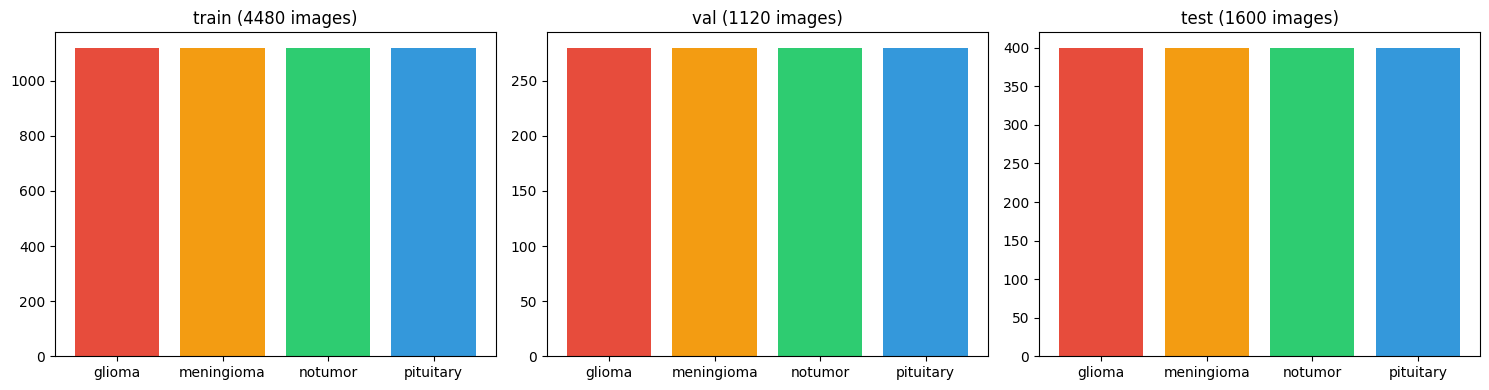

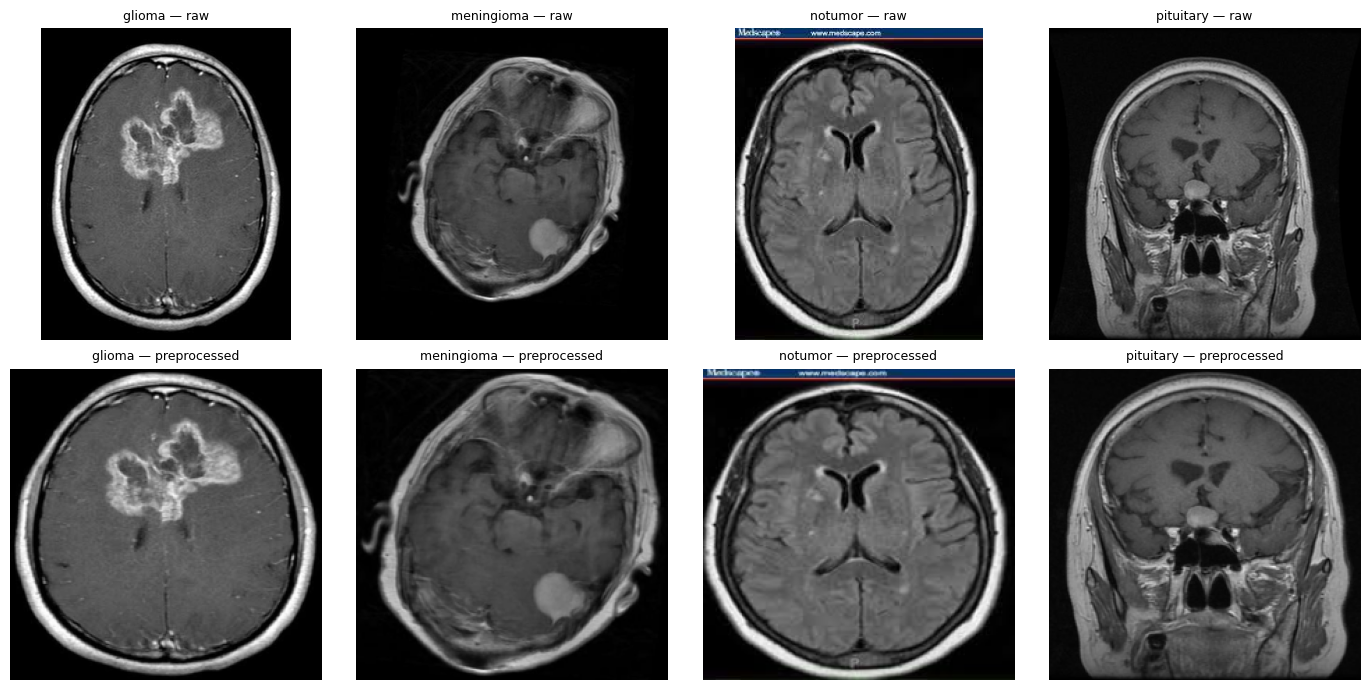

  [stage complete] eda


In [9]:
# ============================================================================
# STAGE 4 · EDA — class distribution + preprocessing demo (cached to disk)
# ============================================================================
stage = "eda"
if stage_done(stage):
    print("SKIP eda — plots already in results/plots/")
else:
    fig, axes = plt.subplots(1, 3, figsize=(15, 4))
    for ax, (name, paths) in zip(axes, {"train": split["train"], "val": split["val"],
                                        "test": split["test"]}.items()):
        cc = {c: sum(1 for p in paths if p.split("/")[1] == c) for c in Config.CLASS_NAMES}
        ax.bar(cc.keys(), cc.values(), color=["#e74c3c", "#f39c12", "#2ecc71", "#3498db"])
        ax.set_title(f"{name} ({sum(cc.values())} images)")
    plt.tight_layout()
    plt.savefig(Config.PLOTS_DIR / "dataset_distribution.png", dpi=200)
    plt.show()

    fig, axes = plt.subplots(2, 4, figsize=(14, 7))
    for j, c in enumerate(Config.CLASS_NAMES):
        src = next(DATA_DIR / p for p in split["test"] if p.split("/")[1] == c)
        raw = cv2.cvtColor(cv2.imread(str(src)), cv2.COLOR_BGR2RGB)
        proc = cv2.resize(remove_black_margins(raw.copy()), (224, 224),
                          interpolation=cv2.INTER_AREA)
        axes[0, j].imshow(raw);  axes[0, j].set_title(f"{c} — raw", fontsize=9)
        axes[1, j].imshow(proc); axes[1, j].set_title(f"{c} — preprocessed", fontsize=9)
        axes[0, j].axis("off");  axes[1, j].axis("off")
    plt.tight_layout()
    plt.savefig(Config.PLOTS_DIR / "preprocessing_demo.png", dpi=200)
    plt.show()
    mark_stage(stage)

## Stage 5 — training infrastructure (pure definitions)

Run this once per session. The five training cells that follow each train **one model, exactly once**:

- If `results/models/<model>/eval.json` exists → the cell prints the stored result and does nothing.
- If a training was interrupted → the cell **resumes** from the last completed epoch via `training_state.pt`.
- Otherwise it trains from scratch, evaluates once on the sealed test set, saves everything, and deletes the resume state.

First run downloads ImageNet-pretrained weights from HuggingFace (~16–22 MB per model; needs internet once). Honest per-model expectation on this i5-1155G7, measured: EfficientNet-B0 ≈ 10 min/epoch (≈4–6 h for 30 epochs, usually less with early stopping); MobileNetV3-Small several times faster; ViT-family models comparable to or slower than B0. Run the cells **one at a time**, in order — that is the point of the design.

In [10]:
# ============================================================================
# STAGE 5 · TRAINING INFRASTRUCTURE
#  · real sklearn metrics (the reference session silently ran with BROKEN
#    sklearn + homemade fallback metric code — every published number there
#    is an approximation; v2 fixes the environment instead)
#  · best-by-val-macro-F1 weights saved ATOMICALLY as a bare state_dict
#    (16-21 MB vs the original's 48-66 MB optimizer-blob checkpoints)
#  · resumable training_state.pt: interrupt a model mid-training, re-run
#    the same cell, and it CONTINUES from the saved epoch — never restarts
# ============================================================================
class EarlyStopping:
    def __init__(self, patience, min_delta):
        self.patience, self.min_delta = patience, min_delta
        self.best, self.count = -math.inf, 0
    def step(self, value):
        if value > self.best + self.min_delta:
            self.best, self.count = value, 0
            return True
        self.count += 1
        return False
    @property
    def triggered(self):
        return self.count >= self.patience
@torch.no_grad()
def collect_logits(model, loader):
    model.eval()
    logits, labels = [], []
    for xb, yb in loader:
        xb = xb.to(DEVICE).to(memory_format=torch.channels_last)
        logits.append(model(xb).cpu().numpy())
        labels.append(yb.numpy())
    return np.concatenate(logits), np.concatenate(labels)
def evaluate_model(model, loader):
    logits, labels = collect_logits(model, loader)
    probs = F.softmax(torch.from_numpy(logits), dim=1).numpy()
    preds = probs.argmax(1)
    roc = {}
    ybin = label_binarize(labels, classes=list(range(Config.NUM_CLASSES)))
    for i, c in enumerate(Config.CLASS_NAMES):
        fpr, tpr, _ = roc_curve(ybin[:, i], probs[:, i])
        step = max(1, len(fpr) // 100)
        roc[c] = {"fpr": fpr[::step].tolist(), "tpr": tpr[::step].tolist(),
                  "auc": float(auc(fpr, tpr))}
    return {
        "n_test": int(len(labels)),
        "accuracy": float(accuracy_score(labels, preds)),
        "precision_macro": float(precision_score(labels, preds, average="macro", zero_division=0)),
        "recall_macro": float(recall_score(labels, preds, average="macro", zero_division=0)),
        "f1_macro": float(f1_score(labels, preds, average="macro", zero_division=0)),
        "f1_weighted": float(f1_score(labels, preds, average="weighted", zero_division=0)),
        "per_class_precision": precision_score(labels, preds, average=None, zero_division=0).tolist(),
        "per_class_recall":    recall_score(labels, preds, average=None, zero_division=0).tolist(),
        "per_class_f1":        f1_score(labels, preds, average=None, zero_division=0).tolist(),
        "confusion_matrix": confusion_matrix(labels, preds).tolist(),
        "roc": roc,
        "classification_report": classification_report(
            labels, preds, target_names=Config.CLASS_NAMES, digits=4, zero_division=0),
    }
def plot_confusion(cm, title, path):
    cm = np.array(cm)
    fig, ax = plt.subplots(figsize=(6, 5))
    im = ax.imshow(cm, cmap="Blues")
    ax.set_xticks(range(4), Config.CLASS_NAMES, rotation=30)
    ax.set_yticks(range(4), Config.CLASS_NAMES)
    thr = cm.max() / 2 if cm.max() > 0 else 0.5
    for i in range(4):
        for j in range(4):
            ax.text(j, i, str(cm[i, j]), ha="center", va="center",
                    color="white" if cm[i, j] > thr else "black")
    ax.set_xlabel("Predicted"); ax.set_ylabel("Actual"); ax.set_title(title)
    fig.colorbar(im); plt.tight_layout()
    plt.savefig(path, dpi=300); plt.show()
def plot_roc(roc, title, path):
    fig, ax = plt.subplots(figsize=(6, 5))
    for c, d in roc.items():
        ax.plot(d["fpr"], d["tpr"], label=f"{c} (AUC {d['auc']:.3f})")
    ax.plot([0, 1], [0, 1], "k--", lw=0.8)
    ax.set_xlabel("False positive rate"); ax.set_ylabel("True positive rate")
    ax.set_title(title); ax.legend(fontsize=8)
    plt.tight_layout(); plt.savefig(path, dpi=300); plt.show()
def plot_history(hist, title, path):
    fig, axes = plt.subplots(1, 3, figsize=(15, 4))
    ep = range(1, len(hist["train_loss"]) + 1)
    axes[0].plot(ep, hist["train_loss"], label="train")
    axes[0].plot(ep, hist["val_loss"], label="val")
    axes[0].set_title("Loss"); axes[0].legend()
    axes[1].plot(ep, hist["train_acc"], label="train")
    axes[1].plot(ep, hist["val_acc"], label="val")
    axes[1].set_title("Accuracy (%)"); axes[1].legend()
    axes[2].plot(ep, hist["val_f1"], color="green")
    axes[2].set_title("Val macro-F1")
    fig.suptitle(title)
    plt.tight_layout(); plt.savefig(path, dpi=200); plt.show()
class BaselineCNN(nn.Module):
    """The stupid-simple baseline every real model has to beat: three conv
    blocks and a linear head — ~90k parameters, no pretraining, no tricks.
    If a 90k-parameter CNN already captures most of the benchmark score,
    that says something about the benchmark, not about the big models."""
    def __init__(self, num_classes=4):
        super().__init__()
        def block(cin, cout):
            return nn.Sequential(nn.Conv2d(cin, cout, 3, padding=1),
                                 nn.BatchNorm2d(cout), nn.ReLU(),
                                 nn.MaxPool2d(2))
        self.features = nn.Sequential(block(3, 32), block(32, 64), block(64, 128),
                                      nn.AdaptiveAvgPool2d(1))
        self.head = nn.Sequential(nn.Flatten(), nn.Linear(128, num_classes))
    def forward(self, x):
        return self.head(self.features(x))

def build_model(spec, pretrained=False):
    """Single model factory for the whole notebook: timm architectures are
    specified by their timm string, the BaselineCNN by the class itself."""
    if isinstance(spec, str):
        return timm.create_model(spec, pretrained=pretrained, num_classes=Config.NUM_CLASSES)
    return spec(num_classes=Config.NUM_CLASSES)

# the baseline lives next to the machinery that trains it, and is registered
# as a first-class model so every later stage treats it like the others
Config.MODELS = {"Baseline-CNN": (BaselineCNN, "CNN"), **Config.MODELS}

def train_one_model(display_name, timm_name, model_type, *, seed=None, split_dict=None):
    mdir = Config.MODELS_DIR / display_name
    mdir.mkdir(parents=True, exist_ok=True)
    eval_path  = mdir / "eval.json"
    hist_path  = mdir / "history.json"
    w_path     = mdir / "best_weights.pth"
    state_path = mdir / "training_state.pt"
    if eval_path.exists():
        ev = json.loads(eval_path.read_text(encoding="utf-8"))
        print(f"SKIP {display_name}: already trained & evaluated — "
              f"test acc {ev['accuracy']*100:.2f}%, macro-F1 {ev['f1_macro']:.4f}")
        return
    print("\n" + "=" * 70)
    spec_name = timm_name if isinstance(timm_name, str) else timm_name.__name__
    size = MODEL_IMG_SIZES.get(display_name.removesuffix("-disjoint"), Config.IMG_SIZE)
    sd = split_dict if split_dict is not None else split
    L = make_split_loaders(sd, size)
    tr_loader, va_loader, te_loader = L["train"], L["val"], L["test"]
    print(f"TRAINING {display_name} ({spec_name}) on {DEVICE} — resumable, run once")
    print("=" * 70)
    set_seed(seed if seed is not None else Config.SEED)   # per-model reseed; the
    # seed-stability stage re-trains the best model at seeds 43/44 through this
    model = build_model(timm_name, pretrained=True)
    model = model.to(DEVICE).to(memory_format=torch.channels_last)
    optimizer = torch.optim.AdamW(model.parameters(), lr=Config.LEARNING_RATE,
                                  weight_decay=Config.WEIGHT_DECAY)
    scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer,
                                                           T_max=Config.SCHEDULER_T_MAX)
    criterion = nn.CrossEntropyLoss()   # UNWEIGHTED — balancing lives in the sampler only
    stopper = EarlyStopping(Config.EARLY_STOP_PATIENCE, Config.EARLY_STOP_MIN_DELTA)
    start_epoch, best_f1 = 1, -1.0
    if state_path.exists():
        st = torch.load(state_path, map_location=DEVICE, weights_only=False)
        model.load_state_dict(st["model"])
        optimizer.load_state_dict(st["optimizer"])
        scheduler.load_state_dict(st["scheduler"])
        hist = st["history"]
        start_epoch, best_f1 = st["epoch"] + 1, st["best_f1"]
        stopper.best, stopper.count = best_f1, st["patience_count"]
        print(f"  RESUMED from epoch {start_epoch} (best val macro-F1 so far {best_f1:.4f})")
    else:
        hist = {"train_loss": [], "train_acc": [], "val_loss": [],
                "val_acc": [], "val_f1": [], "lr": []}
    t_start = time.time()
    interrupted = False
    for epoch in range(start_epoch, Config.EPOCHS + 1):
        try:
            model.train()
            tl, tn, tcorrect = 0.0, 0, 0
            for xb, yb in tr_loader:
                xb = xb.to(DEVICE).to(memory_format=torch.channels_last)
                yb = yb.to(DEVICE)
                optimizer.zero_grad()
                out = model(xb)
                loss = criterion(out, yb)
                loss.backward()
                nn.utils.clip_grad_norm_(model.parameters(), Config.GRAD_CLIP)
                optimizer.step()
                tl += loss.item() * yb.size(0)
                tn += yb.size(0)
                tcorrect += (out.argmax(1) == yb).sum().item()
            train_loss, train_acc = tl / tn, 100.0 * tcorrect / tn
            vlog, vlab = collect_logits(model, va_loader)
            vpred = vlog.argmax(1)
            val_loss = float(F.cross_entropy(torch.from_numpy(vlog), torch.from_numpy(vlab)))
            val_acc = 100.0 * float((vpred == vlab).mean())
            val_f1 = float(f1_score(vlab, vpred, average="macro"))
            lr_now = optimizer.param_groups[0]["lr"]
            hist["train_loss"].append(train_loss); hist["train_acc"].append(train_acc)
            hist["val_loss"].append(val_loss);     hist["val_acc"].append(val_acc)
            hist["val_f1"].append(val_f1);        hist["lr"].append(lr_now)
            per_epoch = (time.time() - t_start) / (epoch - start_epoch + 1)
            eta_min = per_epoch * (Config.EPOCHS - epoch) / 60
            print(f"  Epoch {epoch:02d}/{Config.EPOCHS} | train {train_loss:.4f}/{train_acc:.2f}% "
                  f"| val {val_loss:.4f}/{val_acc:.2f}% | valF1 {val_f1:.4f} "
                  f"| lr {lr_now:.2e} | ETA {eta_min:.0f} min", flush=True)
            if stopper.step(val_f1):
                best_f1 = val_f1
                atomic_save_state({"model": model.state_dict()}, w_path)
                print(f"    * new best — weights saved (val macro-F1 {val_f1:.4f})")
            atomic_save_state({"model": model.state_dict(),
                               "optimizer": optimizer.state_dict(),
                               "scheduler": scheduler.state_dict(),
                               "history": hist, "epoch": epoch, "best_f1": best_f1,
                               "patience_count": stopper.count}, state_path)
            atomic_write_json(hist_path, hist)
            scheduler.step()
            if stopper.triggered:
                print(f"  early stopping at epoch {epoch} "
                      f"(no improvement for {stopper.patience} epochs)")
                break
        except KeyboardInterrupt:
            print(f"\n  INTERRUPTED at epoch {epoch} — state saved; "
                  "re-run this cell to RESUME (it will NOT restart)")
            interrupted = True
            break
    if interrupted:
        return
    # Final: reload best weights, evaluate ONCE on the sealed test set.
    model.load_state_dict(torch.load(w_path, map_location=DEVICE, weights_only=False)["model"])
    ev = evaluate_model(model, te_loader)
    params = sum(p.numel() for p in model.parameters())
    ev.update({
        "model": display_name, "timm_name": spec_name, "model_type": model_type,
        "params": int(params), "size_mb": round(params * 4 / 1e6, 2),
        "best_epoch": int(np.argmax(hist["val_f1"]) + 1),
        "best_val_f1": float(max(hist["val_f1"])),
        "epochs_run": len(hist["val_f1"]),
        "device": str(DEVICE), "seed": seed if seed is not None else Config.SEED,
        "batch_size": Config.BATCH_SIZE,
        "trained_at": datetime.now().isoformat(timespec="seconds"),
    })
    atomic_write_json(eval_path, ev)
    plot_confusion(ev["confusion_matrix"], f"{display_name} — confusion matrix (test)",
                   Config.PLOTS_DIR / f"{display_name}_confusion_matrix.png")
    plot_roc(ev["roc"], f"{display_name} — per-class ROC (test)",
             Config.PLOTS_DIR / f"{display_name}_roc_curves.png")
    plot_history(hist, f"{display_name} — training curves",
                 Config.PLOTS_DIR / f"{display_name}_training_curves.png")
    print(ev["classification_report"])
    print(f"DONE {display_name} | test accuracy {ev['accuracy']*100:.2f}% "
          f"| macro-F1 {ev['f1_macro']:.4f} | best epoch {ev['best_epoch']}")
    state_path.unlink(missing_ok=True)   # training complete — resume state no longer needed
    mark_stage(f"train:{display_name}",
               {"test_acc": ev["accuracy"], "f1_macro": ev["f1_macro"]})

## Stage 6 — training, one model at a time (run these cells in order)

Each cell below is independent and safe to re-run: finished models are skipped, interrupted models resume, nothing ever starts over. Expect overnight-scale total wall-clock on this CPU.


TRAINING Baseline-CNN (BaselineCNN) on cuda — resumable, run once
  Epoch 01/30 | train 1.2979/38.71% | val 1.0903/58.75% | valF1 0.5863 | lr 1.00e-04 | ETA 17 min
    * new best — weights saved (val macro-F1 0.5863)
  Epoch 02/30 | train 1.2243/44.22% | val 1.1040/54.29% | valF1 0.5346 | lr 9.97e-05 | ETA 15 min
  Epoch 03/30 | train 1.2067/45.38% | val 1.0516/60.09% | valF1 0.5930 | lr 9.89e-05 | ETA 14 min
    * new best — weights saved (val macro-F1 0.5930)
  Epoch 04/30 | train 1.1874/46.23% | val 1.0501/52.50% | valF1 0.5086 | lr 9.76e-05 | ETA 14 min
  Epoch 05/30 | train 1.1841/46.54% | val 1.0326/57.05% | valF1 0.5588 | lr 9.57e-05 | ETA 13 min
  Epoch 06/30 | train 1.1742/47.48% | val 1.0220/62.68% | valF1 0.6289 | lr 9.33e-05 | ETA 13 min
    * new best — weights saved (val macro-F1 0.6289)
  Epoch 07/30 | train 1.1769/47.19% | val 0.9984/65.27% | valF1 0.6585 | lr 9.05e-05 | ETA 12 min
    * new best — weights saved (val macro-F1 0.6585)
  Epoch 08/30 | train 1.1541/48.66%

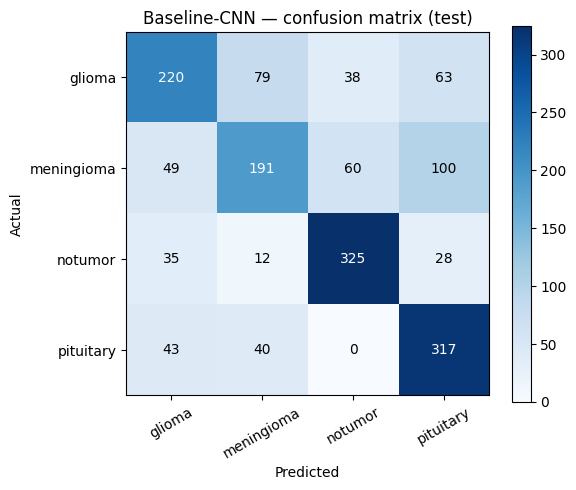

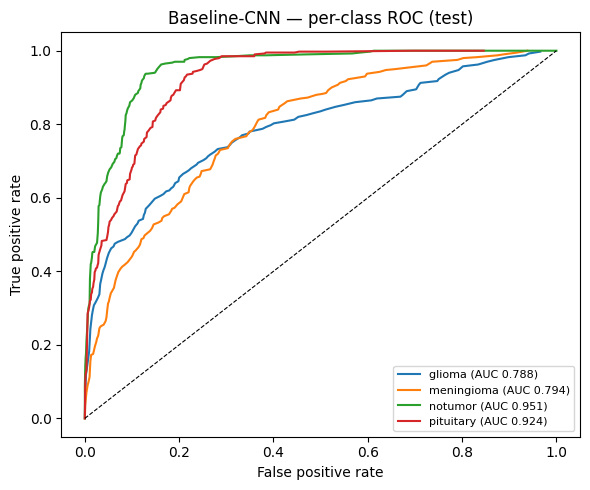

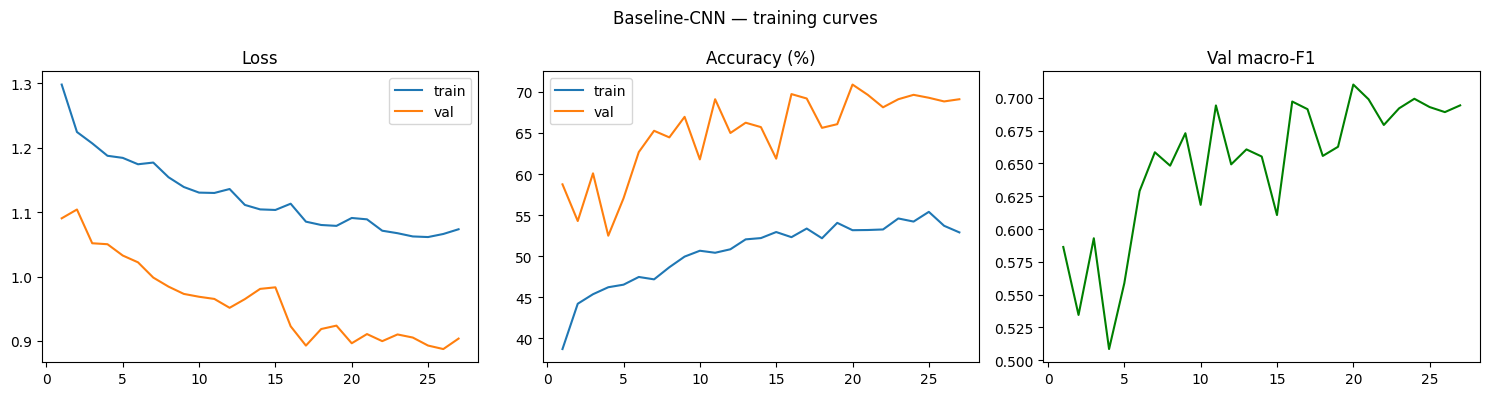

              precision    recall  f1-score   support

      glioma     0.6340    0.5500    0.5890       400
  meningioma     0.5932    0.4775    0.5291       400
     notumor     0.7683    0.8125    0.7898       400
   pituitary     0.6240    0.7925    0.6982       400

    accuracy                         0.6581      1600
   macro avg     0.6549    0.6581    0.6515      1600
weighted avg     0.6549    0.6581    0.6515      1600

DONE Baseline-CNN | test accuracy 65.81% | macro-F1 0.6515 | best epoch 20
  [stage complete] train:Baseline-CNN


In [11]:
# ============================================================================
# STAGE 6a · MODEL 1/6 — Baseline-CNN  (the reference point)
# ~90k parameters, three conv blocks, no pretraining. Every architecture
# below has to justify its complexity against this number.
# ============================================================================
train_one_model("Baseline-CNN", BaselineCNN, "CNN")



TRAINING EfficientNet-B0 (efficientnet_b0) on cuda — resumable, run once


model.safetensors: reconstructing file:   0%|          |  0.00B / 21.4MB            

model.safetensors: downloading bytes:           |  0.00B            

  Epoch 01/30 | train 1.1326/68.12% | val 0.5702/89.29% | valF1 0.8929 | lr 1.00e-04 | ETA 26 min
    * new best — weights saved (val macro-F1 0.8929)
  Epoch 02/30 | train 0.6035/81.00% | val 0.2704/93.57% | valF1 0.9360 | lr 9.97e-05 | ETA 23 min
    * new best — weights saved (val macro-F1 0.9360)
  Epoch 03/30 | train 0.4654/85.56% | val 0.1617/94.82% | valF1 0.9483 | lr 9.89e-05 | ETA 21 min
    * new best — weights saved (val macro-F1 0.9483)
  Epoch 04/30 | train 0.3549/88.28% | val 0.1215/96.43% | valF1 0.9644 | lr 9.76e-05 | ETA 20 min
    * new best — weights saved (val macro-F1 0.9644)
  Epoch 05/30 | train 0.2965/90.62% | val 0.1308/96.70% | valF1 0.9671 | lr 9.57e-05 | ETA 19 min
    * new best — weights saved (val macro-F1 0.9671)
  Epoch 06/30 | train 0.2166/92.88% | val 0.0927/96.96% | valF1 0.9699 | lr 9.33e-05 | ETA 18 min
    * new best — weights saved (val macro-F1 0.9699)
  Epoch 07/30 | train 0.2205/93.55% | val 0.0757/97.68% | valF1 0.9768 | lr 9.05e-05 | ETA 17 

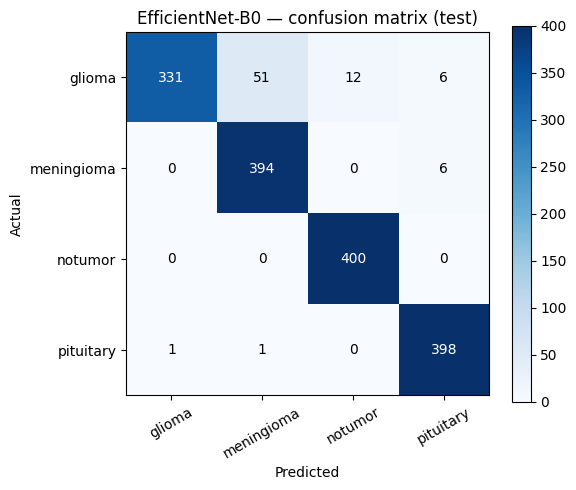

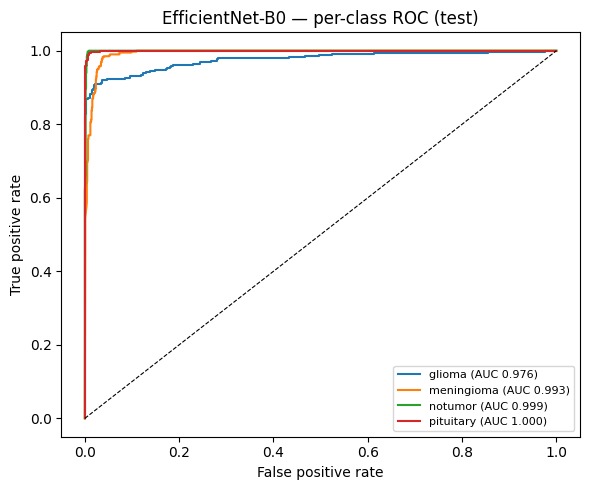

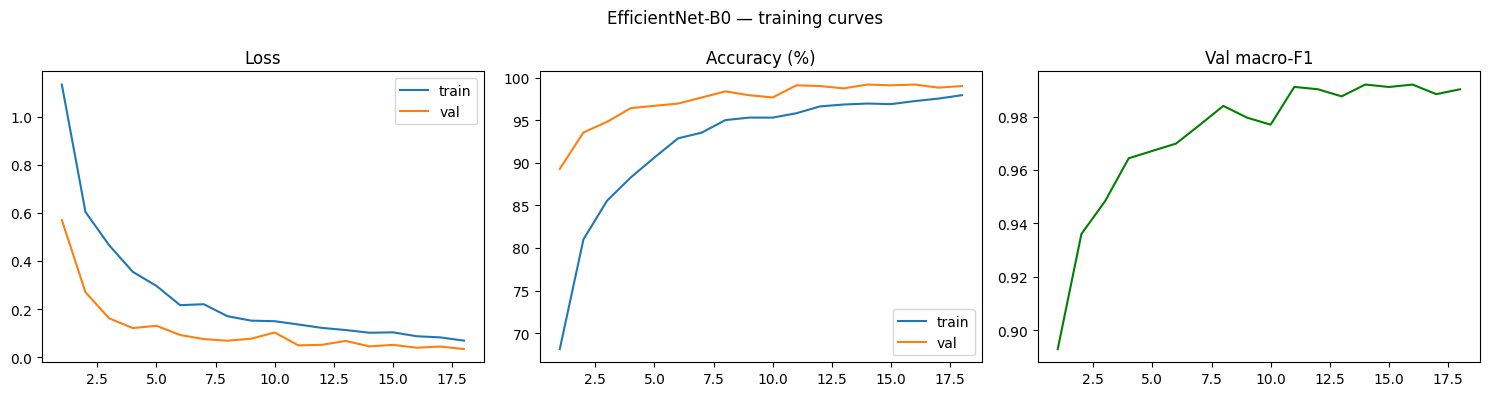

              precision    recall  f1-score   support

      glioma     0.9970    0.8275    0.9044       400
  meningioma     0.8834    0.9850    0.9314       400
     notumor     0.9709    1.0000    0.9852       400
   pituitary     0.9707    0.9950    0.9827       400

    accuracy                         0.9519      1600
   macro avg     0.9555    0.9519    0.9509      1600
weighted avg     0.9555    0.9519    0.9509      1600

DONE EfficientNet-B0 | test accuracy 95.19% | macro-F1 0.9509 | best epoch 14
  [stage complete] train:EfficientNet-B0


In [12]:
# ============================================================================
# STAGE 6b · MODEL 2/6 — EfficientNet-B0  (the CNN workhorse)
# ============================================================================
train_one_model("EfficientNet-B0", "efficientnet_b0", "CNN")


TRAINING MobileNetV3-Small (mobilenetv3_small_100) on cuda — resumable, run once


model.safetensors: reconstructing file:   0%|          |  0.00B / 10.2MB            

model.safetensors: downloading bytes:           |  0.00B            

  Epoch 01/30 | train 1.3226/65.67% | val 0.5660/84.73% | valF1 0.8421 | lr 1.00e-04 | ETA 19 min
    * new best — weights saved (val macro-F1 0.8421)
  Epoch 02/30 | train 0.5797/80.87% | val 0.2537/91.07% | valF1 0.9102 | lr 9.97e-05 | ETA 16 min
    * new best — weights saved (val macro-F1 0.9102)
  Epoch 03/30 | train 0.4669/85.13% | val 0.2140/92.68% | valF1 0.9263 | lr 9.89e-05 | ETA 15 min
    * new best — weights saved (val macro-F1 0.9263)
  Epoch 04/30 | train 0.3781/87.54% | val 0.2000/93.48% | valF1 0.9352 | lr 9.76e-05 | ETA 14 min
    * new best — weights saved (val macro-F1 0.9352)
  Epoch 05/30 | train 0.3355/89.26% | val 0.1222/96.43% | valF1 0.9643 | lr 9.57e-05 | ETA 14 min
    * new best — weights saved (val macro-F1 0.9643)
  Epoch 06/30 | train 0.2859/90.69% | val 0.1808/93.66% | valF1 0.9370 | lr 9.33e-05 | ETA 13 min
  Epoch 07/30 | train 0.2495/92.37% | val 0.2820/92.68% | valF1 0.9282 | lr 9.05e-05 | ETA 12 min
  Epoch 08/30 | train 0.2577/92.54% | val 0.1206/

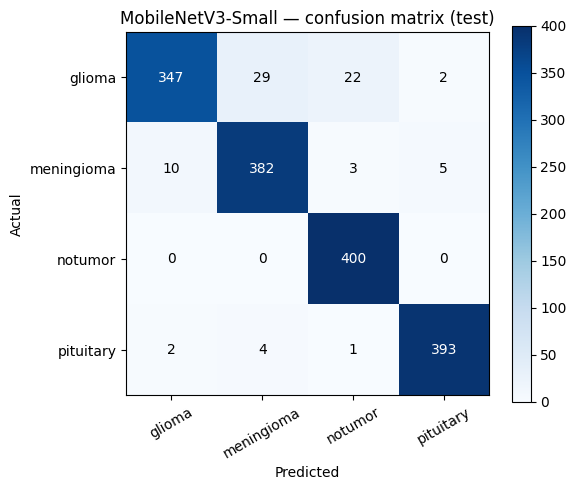

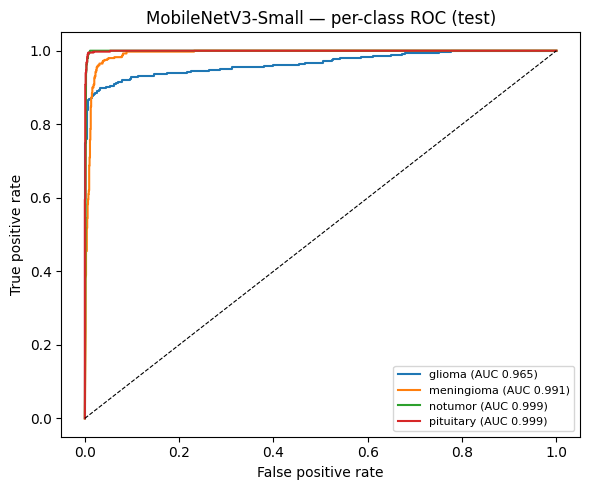

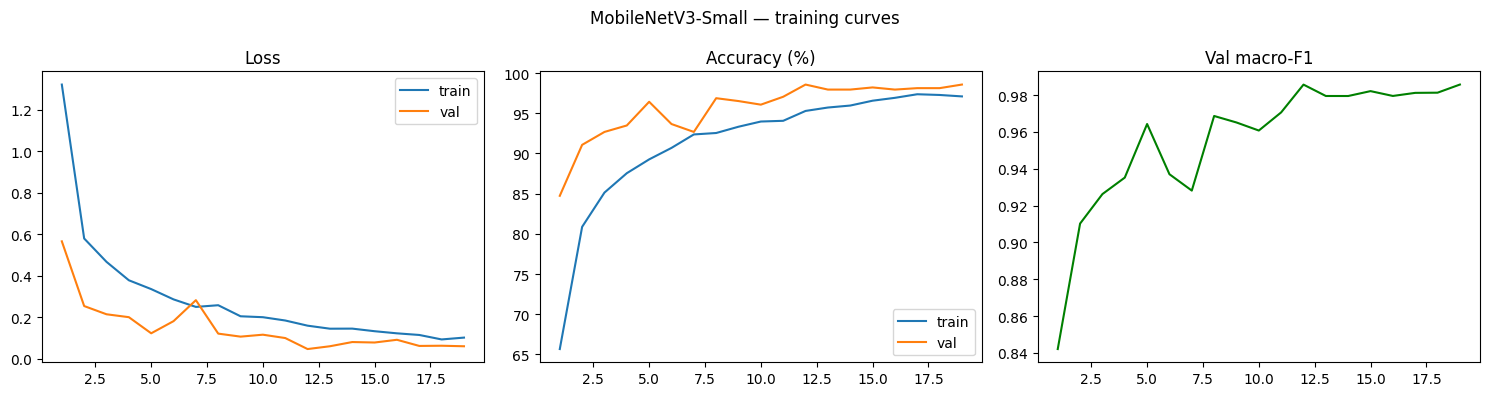

              precision    recall  f1-score   support

      glioma     0.9666    0.8675    0.9144       400
  meningioma     0.9205    0.9550    0.9374       400
     notumor     0.9390    1.0000    0.9685       400
   pituitary     0.9825    0.9825    0.9825       400

    accuracy                         0.9513      1600
   macro avg     0.9521    0.9512    0.9507      1600
weighted avg     0.9521    0.9513    0.9507      1600

DONE MobileNetV3-Small | test accuracy 95.12% | macro-F1 0.9507 | best epoch 19
  [stage complete] train:MobileNetV3-Small


In [13]:
# ============================================================================
# STAGE 6c · MODEL 3/6 — MobileNetV3-Small  (smallest real model)
# ============================================================================
train_one_model("MobileNetV3-Small", "mobilenetv3_small_100", "CNN")


TRAINING MobileViT-S (mobilevit_s) on cuda — resumable, run once


model.safetensors: reconstructing file:   0%|          |  0.00B / 22.4MB            

model.safetensors: downloading bytes:           |  0.00B            

  Epoch 01/30 | train 0.8637/70.31% | val 0.3696/88.21% | valF1 0.8817 | lr 1.00e-04 | ETA 32 min
    * new best — weights saved (val macro-F1 0.8817)
  Epoch 02/30 | train 0.5110/82.28% | val 0.2181/92.50% | valF1 0.9252 | lr 9.97e-05 | ETA 30 min
    * new best — weights saved (val macro-F1 0.9252)
  Epoch 03/30 | train 0.3966/86.52% | val 0.1743/94.38% | valF1 0.9438 | lr 9.89e-05 | ETA 28 min
    * new best — weights saved (val macro-F1 0.9438)
  Epoch 04/30 | train 0.3156/89.29% | val 0.1310/95.54% | valF1 0.9553 | lr 9.76e-05 | ETA 27 min
    * new best — weights saved (val macro-F1 0.9553)
  Epoch 05/30 | train 0.2582/91.94% | val 0.1110/96.96% | valF1 0.9697 | lr 9.57e-05 | ETA 26 min
    * new best — weights saved (val macro-F1 0.9697)
  Epoch 06/30 | train 0.2331/92.57% | val 0.1136/95.89% | valF1 0.9592 | lr 9.33e-05 | ETA 25 min
  Epoch 07/30 | train 0.2104/93.04% | val 0.0814/97.50% | valF1 0.9750 | lr 9.05e-05 | ETA 24 min
    * new best — weights saved (val macro-F1 0.97

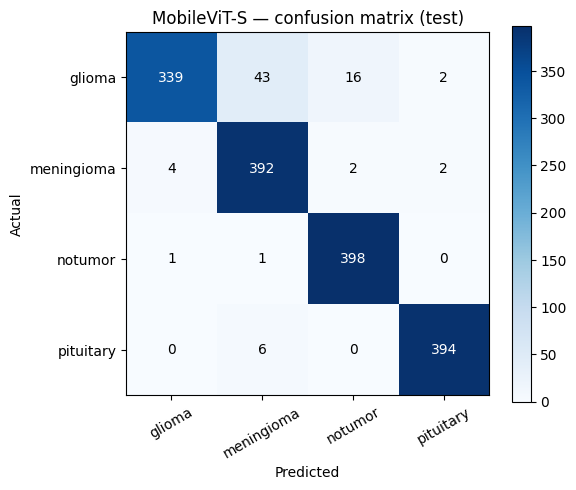

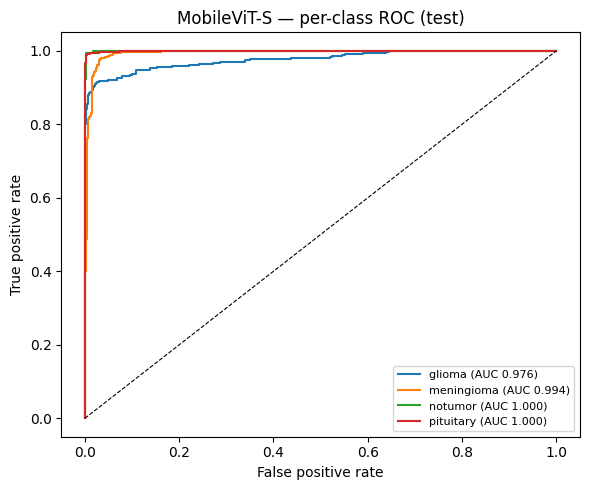

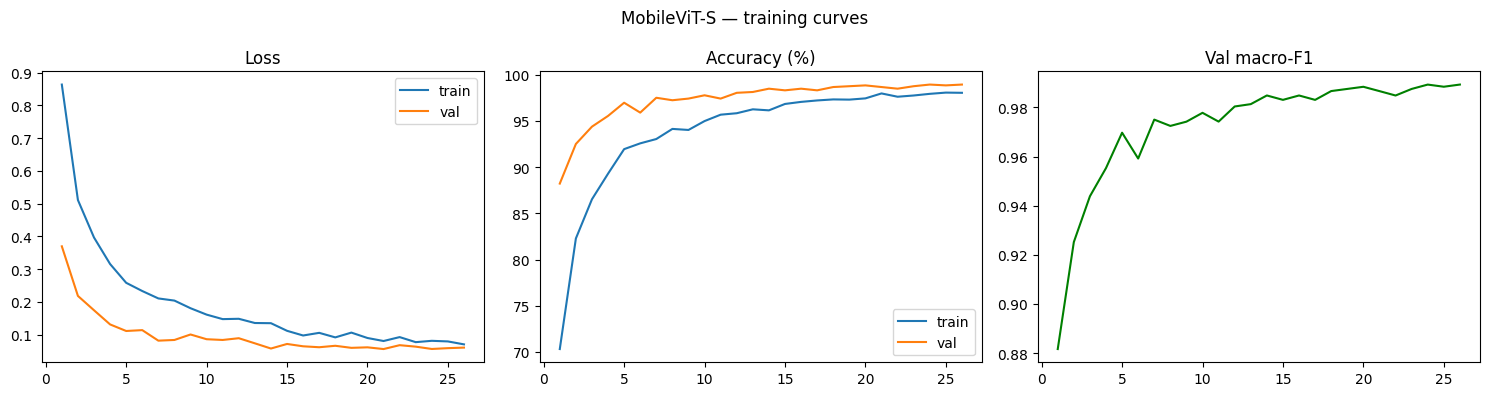

              precision    recall  f1-score   support

      glioma     0.9855    0.8475    0.9113       400
  meningioma     0.8869    0.9800    0.9311       400
     notumor     0.9567    0.9950    0.9755       400
   pituitary     0.9899    0.9850    0.9875       400

    accuracy                         0.9519      1600
   macro avg     0.9548    0.9519    0.9513      1600
weighted avg     0.9548    0.9519    0.9513      1600

DONE MobileViT-S | test accuracy 95.19% | macro-F1 0.9513 | best epoch 26
  [stage complete] train:MobileViT-S


In [14]:
# ============================================================================
# STAGE 6d · MODEL 4/6 — MobileViT-S  (hybrid conv+transformer)
# ============================================================================
train_one_model("MobileViT-S", "mobilevit_s", "Hybrid ViT")


TRAINING DeiT-Tiny (deit_tiny_patch16_224) on cuda — resumable, run once


model.safetensors: reconstructing file:   0%|          |  0.00B / 22.9MB            

model.safetensors: downloading bytes:           |  0.00B            

  Epoch 01/30 | train 0.5504/78.39% | val 0.2116/90.98% | valF1 0.9096 | lr 1.00e-04 | ETA 16 min
    * new best — weights saved (val macro-F1 0.9096)
  Epoch 02/30 | train 0.3285/87.88% | val 0.1734/94.02% | valF1 0.9405 | lr 9.97e-05 | ETA 15 min
    * new best — weights saved (val macro-F1 0.9405)
  Epoch 03/30 | train 0.2875/89.38% | val 0.1829/94.29% | valF1 0.9431 | lr 9.89e-05 | ETA 14 min
    * new best — weights saved (val macro-F1 0.9431)
  Epoch 04/30 | train 0.2338/91.45% | val 0.0875/96.88% | valF1 0.9688 | lr 9.76e-05 | ETA 14 min
    * new best — weights saved (val macro-F1 0.9688)
  Epoch 05/30 | train 0.2213/92.77% | val 0.1041/96.34% | valF1 0.9634 | lr 9.57e-05 | ETA 13 min
  Epoch 06/30 | train 0.2345/91.96% | val 0.1547/94.82% | valF1 0.9473 | lr 9.33e-05 | ETA 13 min
  Epoch 07/30 | train 0.1879/93.71% | val 0.0872/97.05% | valF1 0.9705 | lr 9.05e-05 | ETA 12 min
  Epoch 08/30 | train 0.1785/93.91% | val 0.1062/95.62% | valF1 0.9565 | lr 8.72e-05 | ETA 12 min
  Ep

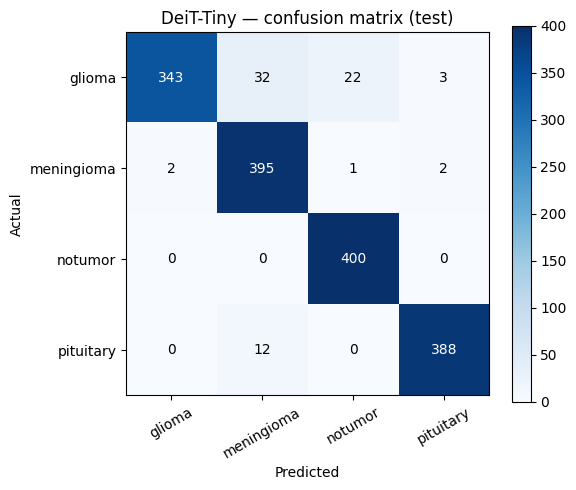

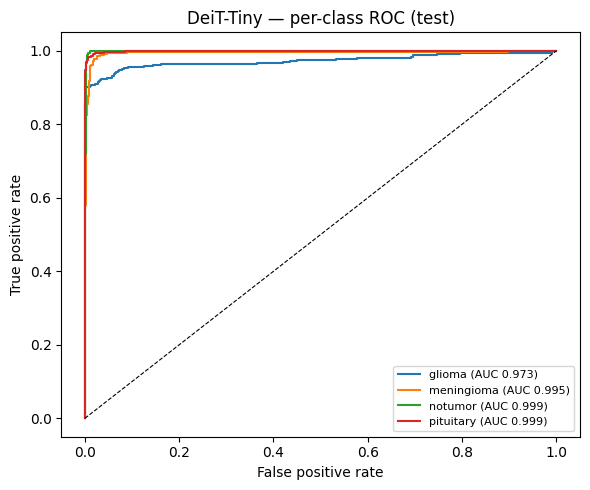

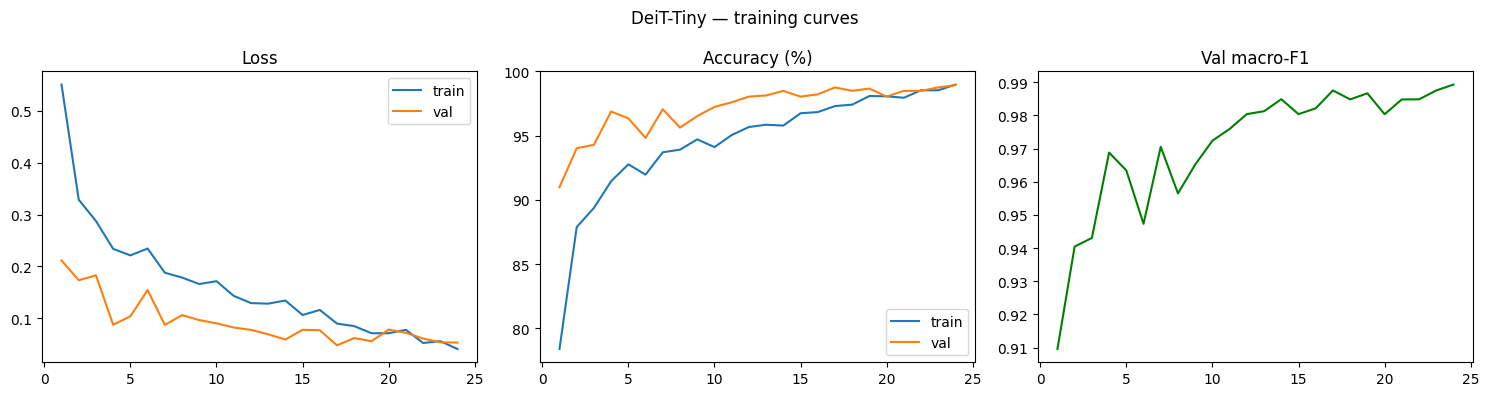

              precision    recall  f1-score   support

      glioma     0.9942    0.8575    0.9208       400
  meningioma     0.8998    0.9875    0.9416       400
     notumor     0.9456    1.0000    0.9721       400
   pituitary     0.9873    0.9700    0.9786       400

    accuracy                         0.9537      1600
   macro avg     0.9567    0.9538    0.9533      1600
weighted avg     0.9567    0.9537    0.9533      1600

DONE DeiT-Tiny | test accuracy 95.38% | macro-F1 0.9533 | best epoch 24
  [stage complete] train:DeiT-Tiny


In [15]:
# ============================================================================
# STAGE 6e · MODEL 5/6 — DeiT-Tiny  (reference run's best model)
# ============================================================================
train_one_model("DeiT-Tiny", "deit_tiny_patch16_224", "ViT")


TRAINING TinyViT-5M (tiny_vit_5m_224) on cuda — resumable, run once


model.safetensors: reconstructing file:   0%|          |  0.00B / 48.4MB            

model.safetensors: downloading bytes:           |  0.00B            

  Epoch 01/30 | train 0.6479/76.52% | val 0.2152/93.12% | valF1 0.9314 | lr 1.00e-04 | ETA 25 min
    * new best — weights saved (val macro-F1 0.9314)
  Epoch 02/30 | train 0.3087/89.24% | val 0.2006/93.21% | valF1 0.9323 | lr 9.97e-05 | ETA 23 min
  Epoch 03/30 | train 0.2329/91.96% | val 0.1286/95.98% | valF1 0.9594 | lr 9.89e-05 | ETA 22 min
    * new best — weights saved (val macro-F1 0.9594)
  Epoch 04/30 | train 0.1982/93.01% | val 0.0970/96.79% | valF1 0.9679 | lr 9.76e-05 | ETA 21 min
    * new best — weights saved (val macro-F1 0.9679)
  Epoch 05/30 | train 0.1701/94.22% | val 0.0638/97.68% | valF1 0.9768 | lr 9.57e-05 | ETA 20 min
    * new best — weights saved (val macro-F1 0.9768)
  Epoch 06/30 | train 0.1558/94.69% | val 0.0705/97.41% | valF1 0.9741 | lr 9.33e-05 | ETA 19 min
  Epoch 07/30 | train 0.1424/95.22% | val 0.0640/98.21% | valF1 0.9822 | lr 9.05e-05 | ETA 18 min
    * new best — weights saved (val macro-F1 0.9822)
  Epoch 08/30 | train 0.1166/95.94% | val 0.0522/

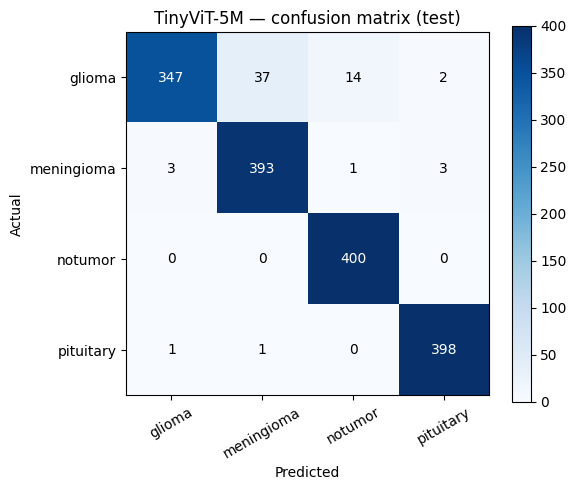

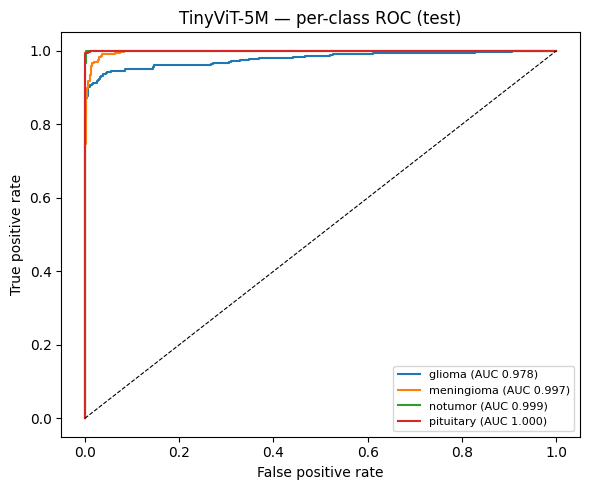

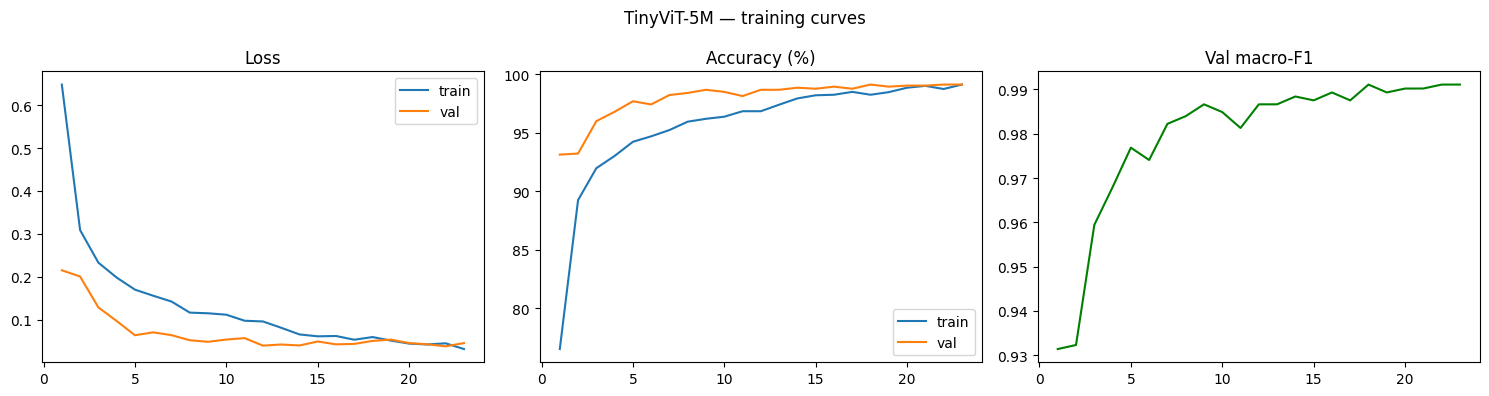

              precision    recall  f1-score   support

      glioma     0.9886    0.8675    0.9241       400
  meningioma     0.9118    0.9825    0.9458       400
     notumor     0.9639    1.0000    0.9816       400
   pituitary     0.9876    0.9950    0.9913       400

    accuracy                         0.9613      1600
   macro avg     0.9630    0.9613    0.9607      1600
weighted avg     0.9630    0.9613    0.9607      1600

DONE TinyViT-5M | test accuracy 96.12% | macro-F1 0.9607 | best epoch 23
  [stage complete] train:TinyViT-5M


In [16]:
# ============================================================================
# STAGE 6f · MODEL 6/6 — TinyViT-5M
# ============================================================================
train_one_model("TinyViT-5M", "tiny_vit_5m_224", "ViT")


TRAINING ResNet-50 (resnet50) on cuda — resumable, run once


model.safetensors: reconstructing file:   0%|          |  0.00B /  102MB            

model.safetensors: downloading bytes:           |  0.00B            

  Epoch 01/30 | train 1.1818/53.17% | val 0.6473/80.09% | valF1 0.8030 | lr 1.00e-04 | ETA 30 min
    * new best — weights saved (val macro-F1 0.8030)
  Epoch 02/30 | train 0.7251/72.70% | val 0.3299/87.77% | valF1 0.8780 | lr 9.97e-05 | ETA 28 min
    * new best — weights saved (val macro-F1 0.8780)
  Epoch 03/30 | train 0.5379/79.98% | val 0.2504/90.36% | valF1 0.9035 | lr 9.89e-05 | ETA 27 min
    * new best — weights saved (val macro-F1 0.9035)
  Epoch 04/30 | train 0.4045/84.58% | val 0.1765/93.12% | valF1 0.9316 | lr 9.76e-05 | ETA 26 min
    * new best — weights saved (val macro-F1 0.9316)
  Epoch 05/30 | train 0.3623/86.70% | val 0.1590/94.11% | valF1 0.9415 | lr 9.57e-05 | ETA 25 min
    * new best — weights saved (val macro-F1 0.9415)
  Epoch 06/30 | train 0.3201/88.59% | val 0.1388/95.27% | valF1 0.9527 | lr 9.33e-05 | ETA 24 min
    * new best — weights saved (val macro-F1 0.9527)
  Epoch 07/30 | train 0.3012/88.55% | val 0.1372/95.71% | valF1 0.9573 | lr 9.05e-05 | ETA 23 

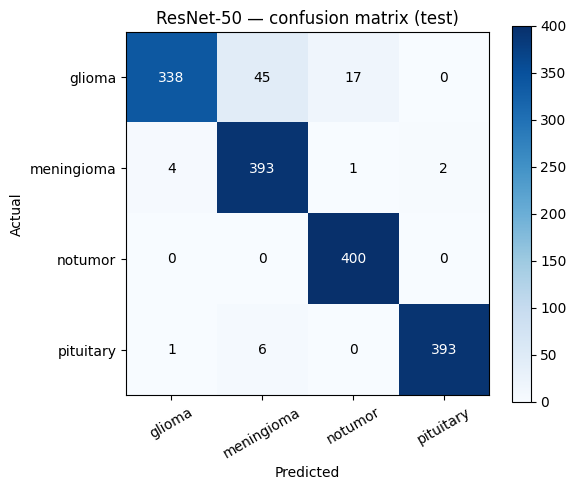

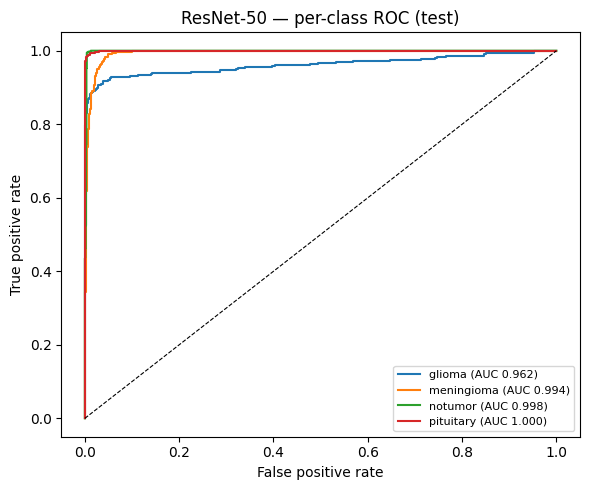

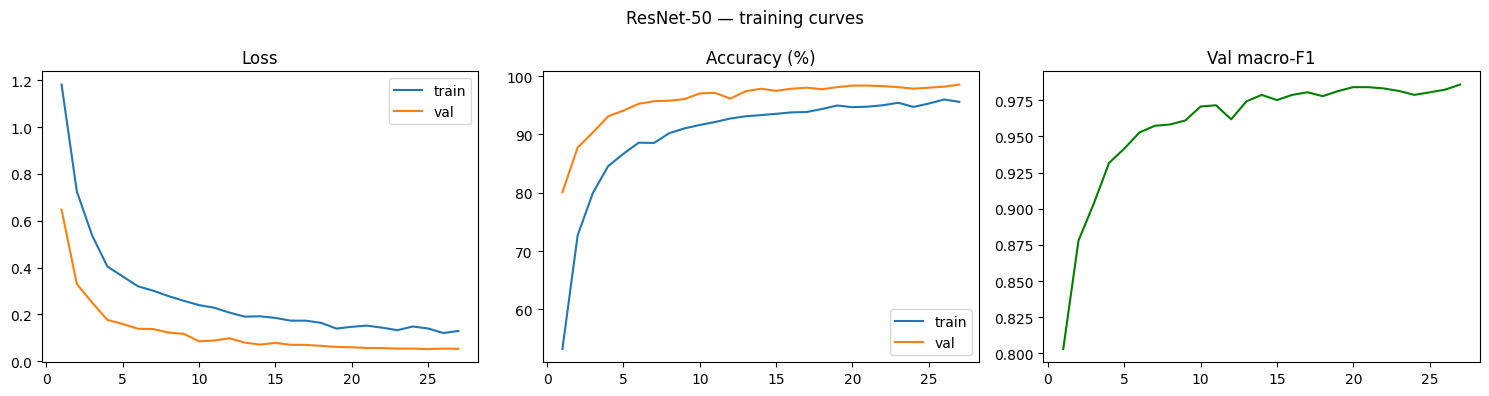

              precision    recall  f1-score   support

      glioma     0.9854    0.8450    0.9098       400
  meningioma     0.8851    0.9825    0.9313       400
     notumor     0.9569    1.0000    0.9780       400
   pituitary     0.9949    0.9825    0.9887       400

    accuracy                         0.9525      1600
   macro avg     0.9556    0.9525    0.9519      1600
weighted avg     0.9556    0.9525    0.9519      1600

DONE ResNet-50 | test accuracy 95.25% | macro-F1 0.9519 | best epoch 27
  [stage complete] train:ResNet-50


In [17]:
# ============================================================================
# STAGE 6g · MODEL 7/8 — ResNet-50  (the classic 2015-era anchor; nearly every
# published brain-tumor comparison includes it, which makes this table
# directly comparable to the literature)
# ============================================================================
train_one_model("ResNet-50", "resnet50", "CNN")



TRAINING Xception-Reference (xception) on cuda — resumable, run once
Downloading: "https://github.com/rwightman/pytorch-image-models/releases/download/v0.1-cadene/xception-43020ad28.pth" to /root/.cache/torch/hub/checkpoints/xception-43020ad28.pth
  Epoch 01/30 | train 0.5241/80.69% | val 0.1332/95.89% | valF1 0.9589 | lr 1.00e-04 | ETA 114 min
    * new best — weights saved (val macro-F1 0.9589)
  Epoch 02/30 | train 0.2808/89.91% | val 0.1168/95.89% | valF1 0.9592 | lr 9.97e-05 | ETA 109 min
  Epoch 03/30 | train 0.1964/93.44% | val 0.0861/97.77% | valF1 0.9776 | lr 9.89e-05 | ETA 104 min
    * new best — weights saved (val macro-F1 0.9776)
  Epoch 04/30 | train 0.1858/94.04% | val 0.0827/97.77% | valF1 0.9778 | lr 9.76e-05 | ETA 100 min
  Epoch 05/30 | train 0.1310/95.98% | val 0.0589/98.66% | valF1 0.9866 | lr 9.57e-05 | ETA 96 min
    * new best — weights saved (val macro-F1 0.9866)
  Epoch 06/30 | train 0.1309/96.29% | val 0.0695/98.30% | valF1 0.9831 | lr 9.33e-05 | ETA 92 min


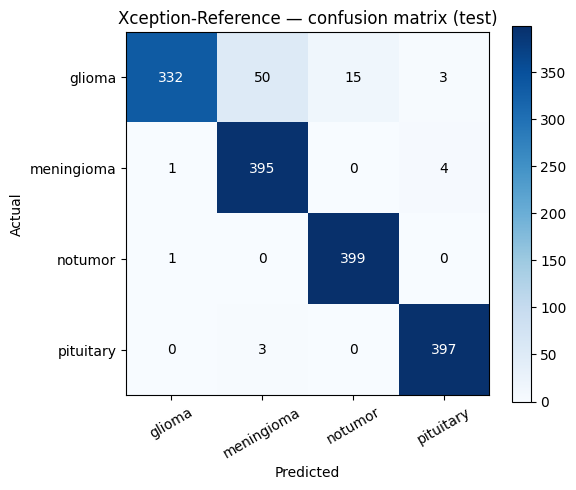

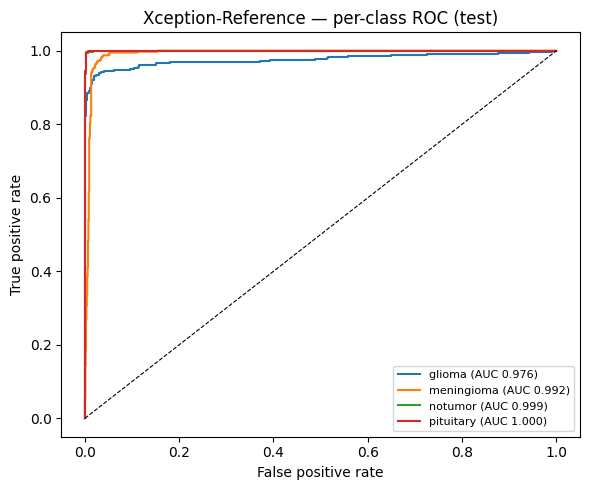

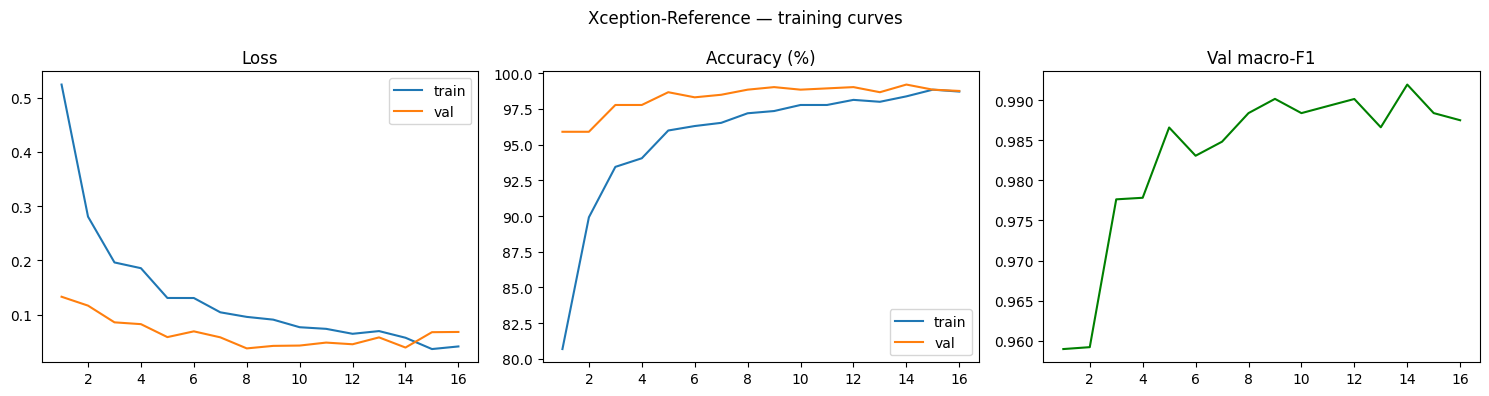

              precision    recall  f1-score   support

      glioma     0.9940    0.8300    0.9046       400
  meningioma     0.8817    0.9875    0.9316       400
     notumor     0.9638    0.9975    0.9803       400
   pituitary     0.9827    0.9925    0.9876       400

    accuracy                         0.9519      1600
   macro avg     0.9555    0.9519    0.9510      1600
weighted avg     0.9555    0.9519    0.9510      1600

DONE Xception-Reference | test accuracy 95.19% | macro-F1 0.9510 | best epoch 14
  [stage complete] train:Xception-Reference


In [18]:
# ============================================================================
# STAGE 6h · MODEL 8/8 — Xception-Reference  (the "99%-club" recipe: the
# architecture of the most-upvoted notebook on this dataset and of the Cancers
# 2025 paper's winner — ImageNet-pretrained, fully fine-tuned, at its native
# 299×299. Included so the famous recipe can be scored on all three exams.)
# ============================================================================
train_one_model("Xception-Reference", "xception", "CNN")


## Stage 7 — comparison (rebuilt from per-model JSONs — duplicates impossible)

*Why:* the scorecard: per-class precision/recall/F1 and macro averages, rebuilt from saved records rather than memory.

,Model,Type,Params (M),Size (MB),Accuracy (%),Macro-F1,Macro-P,Macro-R,Best epoch
0,TinyViT-5M,ViT,5.07,20.29,96.12,0.9607,0.9630,0.9613,23
1,DeiT-Tiny,ViT,5.53,22.10,95.38,0.9533,0.9567,0.9538,24
2,ResNet-50,CNN,23.52,94.06,95.25,0.9519,0.9556,0.9525,27
3,MobileViT-S,Hybrid ViT,4.94,19.76,95.19,0.9513,0.9548,0.9519,26
4,Xception-Reference,CNN,20.82,83.26,95.19,0.9510,0.9555,0.9519,14
5,EfficientNet-B0,CNN,4.01,16.05,95.19,0.9509,0.9555,0.9519,14
6,MobileNetV3-Small,CNN,1.52,6.09,95.12,0.9507,0.9521,0.9512,19
7,Baseline-CNN,CNN,0.09,0.38,65.81,0.6515,0.6549,0.6581,20



BEST MODEL: TinyViT-5M — test acc 96.12%, macro-F1 0.9607


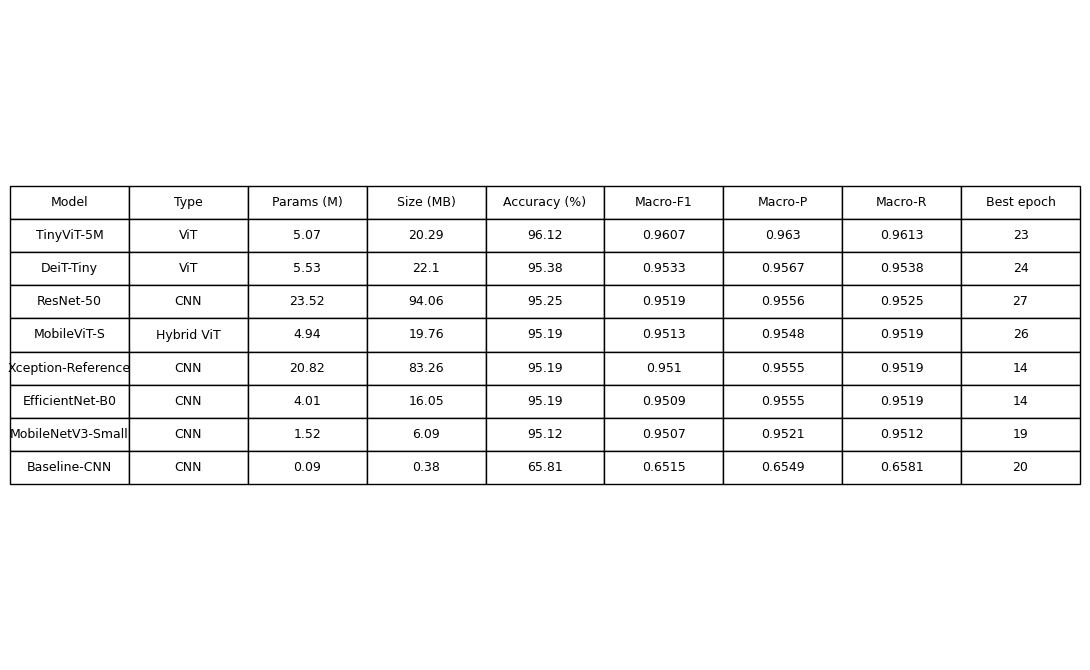


v2 vs reference run (Azure CPU, batch 8, double-balanced, fallback metrics):


,Model,Accuracy (%),reference_acc,delta_pp
0,TinyViT-5M,96.12,99.24,-3.12
1,DeiT-Tiny,95.38,99.31,-3.93
2,ResNet-50,95.25,NaN,NaN
3,MobileViT-S,95.19,98.86,-3.67
4,Xception-Reference,95.19,NaN,NaN
5,EfficientNet-B0,95.19,98.93,-3.74
6,MobileNetV3-Small,95.12,98.78,-3.66
7,Baseline-CNN,65.81,NaN,NaN


  [stage complete] comparison


In [19]:
# ============================================================================
# STAGE 7 · COMPARISON TABLE
# The original appended results across sessions, producing a 6-row table for
# 5 models (two MobileViT-S rows at 98.93% and 98.32%). v2 rebuilds the table
# FRESH from one JSON per model, in ONE unified schema — a duplicate row is
# structurally impossible, and the "Automated Analysis" that crashed in the
# original (KeyError: 'f1_score' — three schemas coexisted) completes here.
# ============================================================================
rows, missing = [], []
for name, (timm_name, mtype) in Config.MODELS.items():
    p = Config.MODELS_DIR / name / "eval.json"
    if p.exists():
        ev = json.loads(p.read_text(encoding="utf-8"))
        rows.append({"Model": name, "Type": mtype,
                     "Params (M)": round(ev["params"] / 1e6, 2),
                     "Size (MB)": ev["size_mb"],
                     "Accuracy (%)": round(ev["accuracy"] * 100, 2),
                     "Macro-F1": round(ev["f1_macro"], 4),
                     "Macro-P": round(ev["precision_macro"], 4),
                     "Macro-R": round(ev["recall_macro"], 4),
                     "Best epoch": ev["best_epoch"]})
    else:
        missing.append(name)

df = pd.DataFrame(rows).sort_values("Macro-F1", ascending=False).reset_index(drop=True)
if missing:
    print("Not yet trained:", missing, "— run their training cells first; "
          "the table below shows what exists so far.")
display(df)

if len(df) == len(Config.MODELS):
    atomic_write_json(Config.RESULTS_DIR / "model_comparison.json", df.to_dict("records"))
    df.to_csv(Config.RESULTS_DIR / "model_comparison.csv", index=False)
    best = df.iloc[0]
    print(f"\nBEST MODEL: {best['Model']} — test acc {best['Accuracy (%)']}%, "
          f"macro-F1 {best['Macro-F1']}")

    fig, ax = plt.subplots(figsize=(11, 0.7 * len(df) + 1.2))
    ax.axis("off")
    tbl = ax.table(cellText=df.astype(str).values, colLabels=df.columns,
                   loc="center", cellLoc="center")
    tbl.auto_set_font_size(False); tbl.set_fontsize(9); tbl.scale(1, 1.6)
    plt.tight_layout()
    plt.savefig(Config.PLOTS_DIR / "model_comparison_table.png", dpi=200,
                bbox_inches="tight")
    plt.show()

    REFERENCE = {   # canonical Azure CPU run (Nov 2025) — context only, see README
        "DeiT-Tiny": 99.31, "TinyViT-5M": 99.24, "EfficientNet-B0": 98.93,
        "MobileViT-S": 98.86, "MobileNetV3-Small": 98.78,
    }
    cmp = df.assign(reference_acc=df["Model"].map(REFERENCE))
    cmp["delta_pp"] = (cmp["Accuracy (%)"] - cmp["reference_acc"]).round(2)
    print("\nv2 vs reference run (Azure CPU, batch 8, double-balanced, fallback metrics):")
    display(cmp[["Model", "Accuracy (%)", "reference_acc", "delta_pp"]])
    mark_stage("comparison", {"best": best["Model"]})

## Stage 8 — explainability (Grad-CAM, done right)

*Why:* verify the model looks at tumors, not shortcuts — and study the failures, not just the pretty maps.

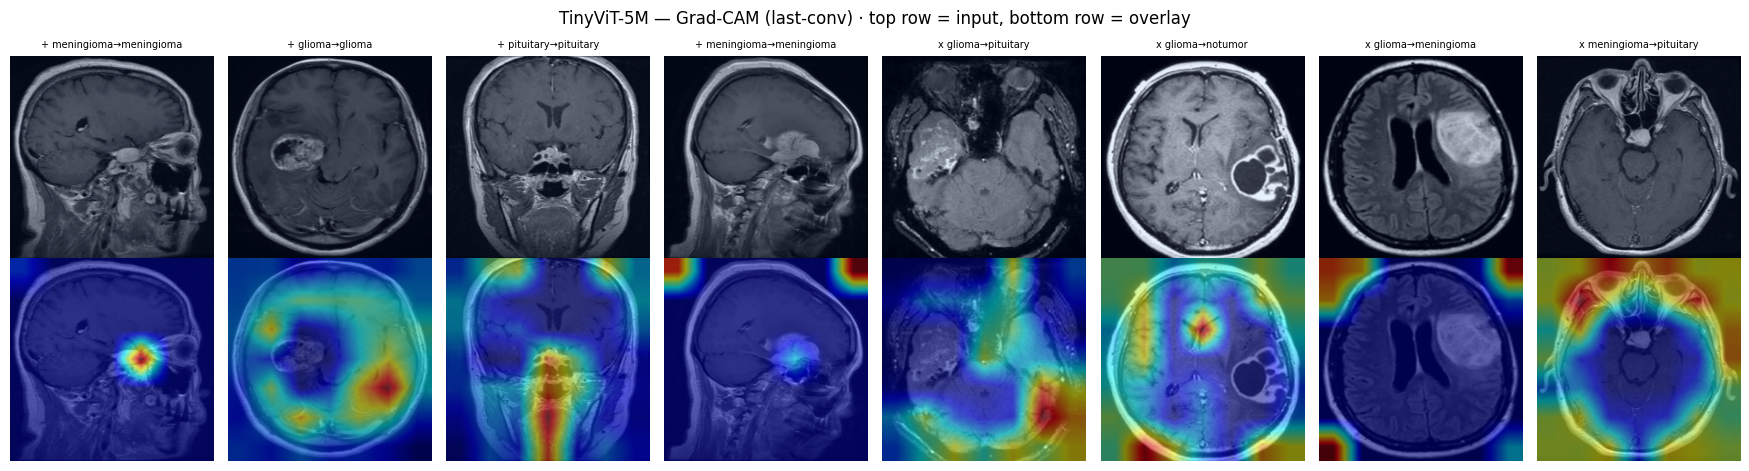

  TinyViT-5M: explained 8 seeded test samples (1538/1600 correct overall)


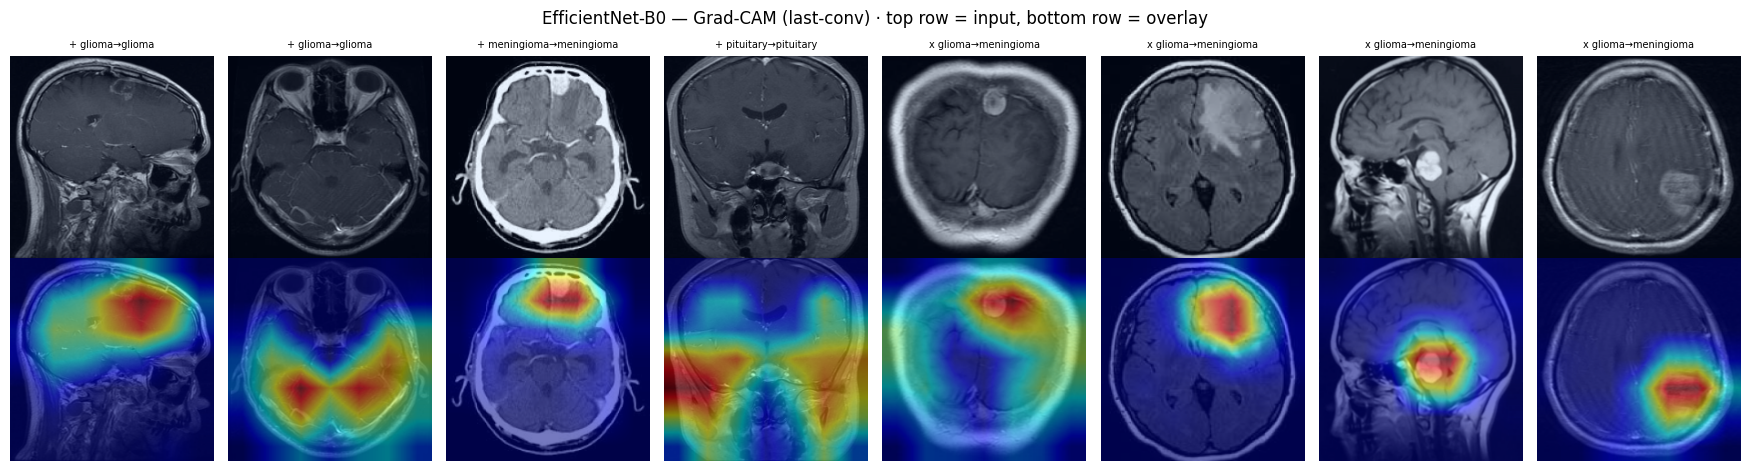

  EfficientNet-B0: explained 8 seeded test samples (1523/1600 correct overall)
  failure profile (TinyViT-5M): true→pred confusion concentrates in glioma→meningioma (37), glioma→notumor (14), meningioma→pituitary (3), meningioma→glioma (3)
  [stage complete] explain


In [20]:
# ============================================================================
# STAGE 8 · EXPLAINABILITY — Grad-CAM via the pytorch-grad-cam library
# Fixes vs the original: deprecated register_backward_hook → maintained
# library; applied to the ACTUAL best model (the original ran it on
# all_results[0] = EfficientNet regardless of the winner); plain ViTs get
# the accepted reshape-transform treatment (raw Grad-CAM is invalid on ViT
# activations); sample selection SEEDED (the original used unseeded
# np.random.choice — its figures were unrepeatable).
# ============================================================================
stage = "explain"
if stage_done(stage):
    print("SKIP explain — Grad-CAM outputs in results/plots/")
else:
    from pytorch_grad_cam import GradCAM as PGGradCAM
    from pytorch_grad_cam.utils.image import show_cam_on_image
    from pytorch_grad_cam.utils.model_targets import ClassifierOutputTarget

    best_name = df.iloc[0]["Model"] if len(df) else "EfficientNet-B0"
    targets_to_explain = [best_name] if best_name == "EfficientNet-B0" \
        else [best_name, "EfficientNet-B0"]   # best model + CNN exemplar

    def vit_reshape(tensor, height=14, width=14, **kwargs):
        # tokens [B, 1+H*W, C] -> feature map [B, C, H, W]
        result = tensor[:, 1:, :].reshape(tensor.size(0), height, width, tensor.size(2))
        return result.transpose(2, 3).transpose(1, 2)

    def pick_target_layer(mname, model):
        if mname == "DeiT-Tiny":
            return [model.blocks[-1].norm1], vit_reshape
        if mname == "TinyViT-5M":
            try:
                return [model.blocks[-1].norm1], vit_reshape
            except AttributeError:
                pass
        convs = [m for m in model.modules() if isinstance(m, nn.Conv2d)]
        return [convs[-1]], None   # CNNs & MobileViT: last conv feature map

    rng = np.random.RandomState(Config.SEED)
    for mname in targets_to_explain:
        size = MODEL_IMG_SIZES.get(mname, Config.IMG_SIZE)
        model = build_model(Config.MODELS[mname][0])
        model.load_state_dict(torch.load(Config.MODELS_DIR / mname / "best_weights.pth",
                                         map_location=DEVICE, weights_only=False)["model"])
        model = model.to(DEVICE).eval()
        layer, reshape = pick_target_layer(mname, model)
        cam = PGGradCAM(model=model, target_layers=layer, reshape_transform=reshape)
        # NOTE: test_loader has shuffle=False, so dataset order == collect order
        exam_ds = BrainTumorDataset(split["test"], get_eval_transforms(size), size)
        logits, labels = collect_logits(model, make_loader(exam_ds))
        preds = logits.argmax(1)
        correct = np.where(preds == labels)[0]
        wrong = np.where(preds != labels)[0]
        picks = list(rng.choice(correct, min(4, len(correct)), replace=False)) + \
                list(rng.choice(wrong, min(4, len(wrong)), replace=False))

        fig, axes = plt.subplots(2, max(len(picks), 1), figsize=(2.2 * len(picks), 4.8))
        axes = np.atleast_2d(axes)
        for col, idx in enumerate(picks):
            img_t, label = exam_ds[int(idx)]
            t_in = img_t.unsqueeze(0).to(DEVICE).to(memory_format=torch.channels_last)
            gray = cam(input_tensor=t_in,
                       targets=[ClassifierOutputTarget(int(preds[idx]))])[0]
            rgb01 = img_t.permute(1, 2, 0).numpy()
            rgb01 = (rgb01 - rgb01.min()) / (rgb01.max() - rgb01.min() + 1e-8)
            overlay = show_cam_on_image(rgb01, gray, use_rgb=True)
            mark = "+" if preds[idx] == labels[idx] else "x"
            axes[0, col].imshow(rgb01);   axes[0, col].axis("off")
            axes[1, col].imshow(overlay); axes[1, col].axis("off")
            axes[0, col].set_title(
                f"{mark} {Config.CLASS_NAMES[labels[idx]]}\u2192{Config.CLASS_NAMES[preds[idx]]}",
                fontsize=7)
        plt.suptitle(f"{mname} — Grad-CAM "
                     f"({'ViT attention' if reshape else 'last-conv'}) · "
                     f"top row = input, bottom row = overlay")
        plt.tight_layout()
        plt.savefig(Config.PLOTS_DIR / f"{mname}_gradcam.png", dpi=200)
        plt.show()
        print(f"  {mname}: explained {len(picks)} seeded test samples "
              f"({int((preds == labels).sum())}/{len(labels)} correct overall)")
        del model, cam
        gc.collect()
    ev = json.loads((Config.MODELS_DIR / best_name / "eval.json").read_text(encoding="utf-8"))
    cm = np.array(ev["confusion_matrix"])
    off = sorted(((int(cm[i, j]), Config.CLASS_NAMES[i], Config.CLASS_NAMES[j])
                  for i in range(Config.NUM_CLASSES)
                  for j in range(Config.NUM_CLASSES) if i != j and cm[i, j] > 0),
                 reverse=True)
    print(f"  failure profile ({best_name}): true\u2192pred confusion concentrates in " +
          ", ".join(f"{t}\u2192{p} ({n})" for n, t, p in off[:4]))
    mark_stage("explain", {"explained": targets_to_explain})

## Stage 9 — ONNX export + parity verification

*Why:* a model that leaves its training framework must be proven unchanged — the exported file re-answers the same exam and the logits must match.

In [21]:
# ============================================================================
# STAGE 9 · ONNX EXPORT + PARITY VERIFICATION (best model + smallest model)
# The original's export cell crashed (ModuleNotFoundError — its %pip install
# needed a kernel restart that was never done) and there was NO verification
# step anyway; the .onnx that shipped in the azure folder is byte-identical
# to the local run's file. v2 exports with opset 17 + dynamic batch, then
# VERIFIES logits against PyTorch through onnxruntime before moving on.
# ============================================================================
stage = "export_onnx"
exports = {}
best_name = df.iloc[0]["Model"] if len(df) else "EfficientNet-B0"
to_export = sorted({best_name, "MobileNetV3-Small"})   # best + smallest
if stage_done(stage):
    print(f"SKIP export_onnx — files in {Config.EXPORT_DIR}")
else:
    import onnx
    import onnxruntime as ort
    probe = {m: next(iter(DataLoader(BrainTumorDataset(split["test"],
                    get_eval_transforms(MODEL_IMG_SIZES.get(m, Config.IMG_SIZE)),
                    MODEL_IMG_SIZES.get(m, Config.IMG_SIZE)),
                    batch_size=8, shuffle=False, num_workers=0)))[0] for m in to_export}
    for mname in to_export:
        size = MODEL_IMG_SIZES.get(mname, Config.IMG_SIZE)
        dummy = torch.randn(1, 3, size, size)
        xb_fixed = probe[mname]
        model = build_model(Config.MODELS[mname][0])
        model.load_state_dict(torch.load(Config.MODELS_DIR / mname / "best_weights.pth",
                                         map_location="cpu", weights_only=False)["model"])
        model.eval()
        onnx_path = Config.EXPORT_DIR / f"{mname}.onnx"
        with torch.no_grad():
            try:
                torch.onnx.export(model, dummy, str(onnx_path), export_params=True,
                                  opset_version=17, do_constant_folding=True,
                                  input_names=["input"], output_names=["output"],
                                  dynamic_axes={"input": {0: "batch_size"},
                                                "output": {0: "batch_size"}},
                                  dynamo=False)
            except Exception as e:
                print(f"  legacy exporter failed ({e}) — retrying with dynamo exporter")
                torch.onnx.export(model, dummy, str(onnx_path),
                                  input_names=["input"], output_names=["output"],
                                  dynamic_axes={"input": {0: "batch_size"},
                                                "output": {0: "batch_size"}})
        onnx.checker.check_model(onnx.load(str(onnx_path)))
        so = ort.SessionOptions(); so.intra_op_num_threads = 4
        sess = ort.InferenceSession(str(onnx_path), so, providers=["CPUExecutionProvider"])
        with torch.no_grad():
            t_out = model(xb_fixed).numpy()
        o_out = sess.run(None, {"input": xb_fixed.numpy()})[0]
        maxdiff = float(np.abs(t_out - o_out).max())
        exports[mname] = {"onnx": str(onnx_path),
                          "size_mb": round(onnx_path.stat().st_size / 1e6, 2),
                          "max_abs_diff": maxdiff, "parity_ok": bool(maxdiff < 1e-3)}
        print(f"  {mname}: exported ({exports[mname]['size_mb']} MB) | "
              f"ORT-vs-PyTorch max|dlogit| = {maxdiff:.2e} "
              f"{'PASS' if maxdiff < 1e-3 else 'FAIL'}")
        del model
        gc.collect()
    atomic_write_json(Config.EXPORT_DIR / "onnx_parity.json", exports)
    mark_stage("export_onnx", exports)

  MobileNetV3-Small: exported (6.1 MB) | ORT-vs-PyTorch max|dlogit| = 3.00e-05 PASS
  TinyViT-5M: exported (20.86 MB) | ORT-vs-PyTorch max|dlogit| = 4.77e-06 PASS
  [stage complete] export_onnx


## Stage 10 — inference speed on the T4 (PyTorch CUDA)

*Why:* deployment is a speed/accuracy trade — measured with warmup, medians and synchronized timing so no number is fake.

In [22]:
# ============================================================================
# STAGE 10 · INFERENCE SPEED — PyTorch CUDA on the T4 this run trains on.
# The v7 design measured every runtime x every device because it targeted a
# laptop with an iGPU; on a pure-GPU cloud box that matrix is noise (and it
# cost ~30 min of T4 time for a negative result). v8 keeps ONE honest
# measurement: how fast each trained model serves on the device that
# actually ran the project. Same protocol — warmup 10, 100 timed iters @
# batch 1, 30 @ batch 16, MEDIAN reported, and 0.0 is never a measurement.
# ============================================================================
stage = "benchmark"
if stage_done(stage):
    print("SKIP benchmark — results:")
    display(pd.read_csv(Config.RESULTS_DIR / "benchmarks.csv"))
else:
    assert torch.cuda.is_available(), "Stage 10 needs the CUDA GPU this notebook targets."
    dev_name = torch.cuda.get_device_name(0)

    def bench_fn(fn, warmup=10, iters=100):
        for _ in range(warmup):
            fn()
        ts = []
        for _ in range(iters):
            t0 = time.perf_counter(); fn()
            ts.append((time.perf_counter() - t0) * 1000)
        return float(np.median(ts))

    rows = []
    for mname in Config.MODELS:
        size = MODEL_IMG_SIZES.get(mname, Config.IMG_SIZE)
        dummy1  = torch.rand(1, 3, size, size, device="cuda")
        dummy16 = torch.rand(16, 3, size, size, device="cuda")
        model = build_model(Config.MODELS[mname][0])
        model.load_state_dict(torch.load(Config.MODELS_DIR / mname / "best_weights.pth",
                                          map_location="cuda", weights_only=False)["model"])
        model = model.to("cuda").eval()
        with torch.no_grad():
            ms1  = bench_fn(lambda: (model(dummy1),  torch.cuda.synchronize()))
            ms16 = bench_fn(lambda: (model(dummy16), torch.cuda.synchronize()), iters=30)
        rows.append({"model": mname, "runtime": "PyTorch CUDA fp32", "device": dev_name,
                     "batch": 1,  "median_ms": ms1})
        rows.append({"model": mname, "runtime": "PyTorch CUDA fp32", "device": dev_name,
                     "batch": 16, "median_ms": ms16})
        print(f"  {mname}: {ms1:.2f} ms @ batch 1 | {ms16:.2f} ms @ batch 16")
        del model
        torch.cuda.empty_cache()

    bench = pd.DataFrame(rows)
    bench["ms_per_image"] = (bench["median_ms"] / bench["batch"]).round(3)
    bench["fps"] = (1000 / bench["ms_per_image"]).round(1)
    bench = bench.sort_values(["model", "batch", "ms_per_image"]).reset_index(drop=True)
    bench.to_csv(Config.RESULTS_DIR / "benchmarks.csv", index=False)
    display(bench)
    mark_stage("benchmark")

  Baseline-CNN: 0.96 ms @ batch 1 | 10.08 ms @ batch 16
  EfficientNet-B0: 9.44 ms @ batch 1 | 20.08 ms @ batch 16
  MobileNetV3-Small: 6.28 ms @ batch 1 | 6.90 ms @ batch 16
  MobileViT-S: 10.07 ms @ batch 1 | 40.00 ms @ batch 16
  DeiT-Tiny: 6.10 ms @ batch 1 | 19.49 ms @ batch 16
  TinyViT-5M: 10.07 ms @ batch 1 | 31.63 ms @ batch 16
  ResNet-50: 6.70 ms @ batch 1 | 56.72 ms @ batch 16
  Xception-Reference: 8.57 ms @ batch 1 | 182.84 ms @ batch 16


,model,runtime,device,batch,median_ms,ms_per_image,fps
0,Baseline-CNN,PyTorch CUDA fp32,Tesla T4,1,0.963673,0.964,1037.3
1,Baseline-CNN,PyTorch CUDA fp32,Tesla T4,16,10.075113,0.630,1587.3
2,DeiT-Tiny,PyTorch CUDA fp32,Tesla T4,1,6.103155,6.103,163.9
3,DeiT-Tiny,PyTorch CUDA fp32,Tesla T4,16,19.488419,1.218,821.0
4,EfficientNet-B0,PyTorch CUDA fp32,Tesla T4,1,9.437719,9.438,106.0
5,EfficientNet-B0,PyTorch CUDA fp32,Tesla T4,16,20.082109,1.255,796.8
6,MobileNetV3-Small,PyTorch CUDA fp32,Tesla T4,1,6.283516,6.284,159.1
7,MobileNetV3-Small,PyTorch CUDA fp32,Tesla T4,16,6.898368,0.431,2320.2
8,MobileViT-S,PyTorch CUDA fp32,Tesla T4,1,10.069205,10.069,99.3
9,MobileViT-S,PyTorch CUDA fp32,Tesla T4,16,40.002454,2.500,400.0


  [stage complete] benchmark


## Stage 11 — clean-subset evaluation (dual metrics)

*Why:* strip every test image with a near-twin in training and re-score — the first honest tier, plus per-class numbers showing which class leans hardest on memory.

In [23]:
# ============================================================================
# STAGE 11 · CLEAN-SUBSET EVALUATION — the honest split.
# The data-quality audit (Stage 2) shows most test images share a perceptual
# hash with training images — same patient, neighbouring slices. This stage
# removes every test image whose pHash lies within Hamming 8 of ANY training
# image and re-scores every model on the remainder, which behaves like truly
# unseen patients. The full-test vs clean-subset GAP is the leakage premium
# of this benchmark. Per-class numbers answer: which class leans hardest on
# memorization?
# ============================================================================
stage = "clean_subset"
if stage_done(stage):
    print("SKIP clean_subset — see results/clean_subset_report.json")
else:
    from torch.utils.data import Subset
    import imagehash
    from PIL import Image

    def ph2u64(h):
        v = 0
        for bit in np.asarray(h.hash).flatten():
            v = (v << 1) | int(bit)
        return v

    def hash_paths(paths):
        out = []
        for p in paths:
            with Image.open(p) as im:
                out.append(ph2u64(imagehash.phash(im)))
        return np.array(out, dtype=np.uint64)

    tr_paths = [DATA_DIR / p for p in split["train"]]
    te_paths = [DATA_DIR / p for p in split["test"]]
    te_classes = np.array([CLASS_TO_IDX[p.split("/")[1]] for p in split["test"]])
    print(f"  hashing {len(tr_paths)} train + {len(te_paths)} test images "
          "(one-time, stage-gated) ...")
    tr_h = hash_paths(tr_paths)
    te_h = hash_paths(te_paths)
    ham = np.bitwise_count(te_h[:, None] ^ tr_h[None, :])
    dirty = (ham <= 8).any(axis=1)          # exact duplicates are Hamming 0 — included
    clean_idx = np.where(~dirty)[0]
    print(f"  clean test subset: {len(clean_idx)} of {len(te_h)} images "
          f"({int(dirty.sum())} have a near-duplicate in the actual training split)")

    comp = {c: int((te_classes[clean_idx] == i).sum()) for i, c in enumerate(Config.CLASS_NAMES)}
    print("  clean-subset class composition:", comp)

    rows = []
    for mname in Config.MODELS:
        size = MODEL_IMG_SIZES.get(mname, Config.IMG_SIZE)
        model = build_model(Config.MODELS[mname][0])
        model.load_state_dict(torch.load(Config.MODELS_DIR / mname / "best_weights.pth",
                                         map_location=DEVICE, weights_only=False)["model"])
        model = model.to(DEVICE).eval().to(memory_format=torch.channels_last)
        ds_c = BrainTumorDataset([split["test"][i] for i in clean_idx],
                                 get_eval_transforms(size), size)
        logits, labels = collect_logits(model, make_loader(ds_c))
        preds = logits.argmax(1)
        acc = float(accuracy_score(labels, preds))
        f1m = float(f1_score(labels, preds, average="macro"))
        per_class = {c: float((preds[labels == i] == i).mean())
                     for i, c in enumerate(Config.CLASS_NAMES)}
        full = json.loads((Config.MODELS_DIR / mname / "eval.json").read_text(encoding="utf-8"))
        rows.append({"Model": mname,
                     "Full test acc (%)": round(full["accuracy"] * 100, 2),
                     "Clean subset acc (%)": round(acc * 100, 2),
                     "Drop (pp)": round(full["accuracy"] * 100 - acc * 100, 2),
                     "Full macro-F1": round(full["f1_macro"], 4),
                     "Clean macro-F1": round(f1m, 4),
                     "Full per-class recall": full["per_class_recall"],
                     "Clean per-class recall": per_class,
                     "Clean n": int(len(clean_idx))})
        del model
        gc.collect()

    cdf = pd.DataFrame([{k: v for k, v in r.items() if not isinstance(v, dict)} for r in rows]
                       ).sort_values("Clean macro-F1", ascending=False).reset_index(drop=True)
    display(cdf)
    pclass = pd.DataFrame({r["Model"]: {c: round(r["Clean per-class recall"][c] - r["Full per-class recall"][i], 3)
                                        for i, c in enumerate(Config.CLASS_NAMES)} for r in rows}).T
    print("  per-class recall change on the clean subset (clean - full):")
    display(pclass)
    atomic_write_json(Config.RESULTS_DIR / "clean_subset_report.json",
                      {"clean_test_images": int(len(clean_idx)),
                       "dirty_test_images": int(dirty.sum()),
                       "clean_class_composition": comp,
                       "near_duplicate_rule": "pHash Hamming<=8 vs actual training split",
                       "rows": rows})
    print("  The full-vs-clean gap is how much of the benchmark score is "
          "patient-recognition rather than generalisation.")
    mark_stage(stage, {"clean_test_images": int(len(clean_idx))})

  hashing 4480 train + 1600 test images (one-time, stage-gated) ...
  clean test subset: 438 of 1600 images (1162 have a near-duplicate in the actual training split)
  clean-subset class composition: {'glioma': 166, 'meningioma': 114, 'notumor': 40, 'pituitary': 118}


,Model,Full test acc (%),Clean subset acc (%),Drop (pp),Full macro-F1,Clean macro-F1,Full per-class recall,Clean n
0,TinyViT-5M,96.12,88.81,7.31,0.9607,0.8857,"[0.8675, 0.9825, 1.0, 0.995]",438
1,EfficientNet-B0,95.19,86.76,8.43,0.9509,0.8727,"[0.8275, 0.985, 1.0, 0.995]",438
2,ResNet-50,95.25,87.21,8.04,0.9519,0.8703,"[0.845, 0.9825, 1.0, 0.9825]",438
3,Xception-Reference,95.19,86.76,8.43,0.9510,0.8689,"[0.83, 0.9875, 0.9975, 0.9925]",438
4,MobileViT-S,95.19,86.99,8.20,0.9513,0.8680,"[0.8475, 0.98, 0.995, 0.985]",438
5,MobileNetV3-Small,95.12,86.76,8.37,0.9507,0.8584,"[0.8675, 0.955, 1.0, 0.9825]",438
6,DeiT-Tiny,95.38,86.53,8.85,0.9533,0.8561,"[0.8575, 0.9875, 1.0, 0.97]",438
7,Baseline-CNN,65.81,57.53,8.28,0.6515,0.5683,"[0.55, 0.4775, 0.8125, 0.7925]",438


  per-class recall change on the clean subset (clean - full):


,glioma,meningioma,notumor,pituitary
Baseline-CNN,-0.183,0.005,0.062,0.063
EfficientNet-B0,-0.147,-0.011,0.000,-0.012
MobileNetV3-Small,-0.163,0.001,0.000,-0.016
MobileViT-S,-0.155,-0.006,0.005,-0.010
DeiT-Tiny,-0.153,-0.005,0.000,-0.038
TinyViT-5M,-0.139,-0.009,0.000,-0.003
ResNet-50,-0.152,0.009,0.000,-0.016
Xception-Reference,-0.173,0.012,0.002,-0.001


  The full-vs-clean gap is how much of the benchmark score is patient-recognition rather than generalisation.
  [stage complete] clean_subset


## Stage 12 — seed stability (best model × 3 seeds)

*Why:* one run is a lottery ticket; the honest report is mean ± spread across seeds.


TRAINING TinyViT-5M_s43 (tiny_vit_5m_224) on cuda — resumable, run once
  Epoch 01/30 | train 0.6801/74.55% | val 0.2235/92.41% | valF1 0.9242 | lr 1.00e-04 | ETA 23 min
    * new best — weights saved (val macro-F1 0.9242)
  Epoch 02/30 | train 0.3305/88.42% | val 0.1577/94.11% | valF1 0.9416 | lr 9.97e-05 | ETA 22 min
    * new best — weights saved (val macro-F1 0.9416)
  Epoch 03/30 | train 0.2380/91.67% | val 0.0942/97.23% | valF1 0.9723 | lr 9.89e-05 | ETA 21 min
    * new best — weights saved (val macro-F1 0.9723)
  Epoch 04/30 | train 0.2134/92.37% | val 0.1160/95.00% | valF1 0.9500 | lr 9.76e-05 | ETA 21 min
  Epoch 05/30 | train 0.1720/93.77% | val 0.0698/97.68% | valF1 0.9768 | lr 9.57e-05 | ETA 20 min
    * new best — weights saved (val macro-F1 0.9768)
  Epoch 06/30 | train 0.1522/94.98% | val 0.0690/98.04% | valF1 0.9804 | lr 9.33e-05 | ETA 19 min
    * new best — weights saved (val macro-F1 0.9804)
  Epoch 07/30 | train 0.1380/95.54% | val 0.0648/97.86% | valF1 0.9786 | l

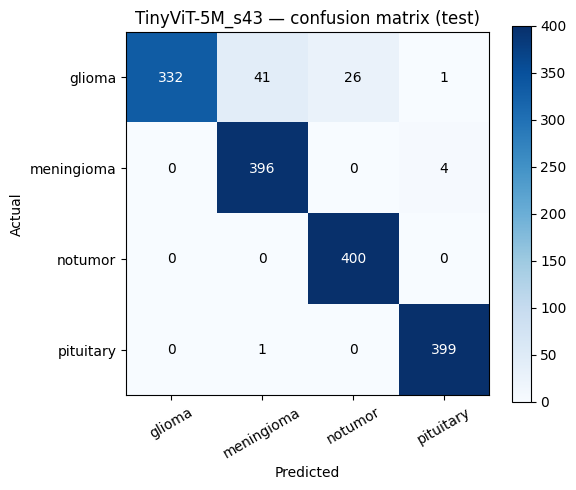

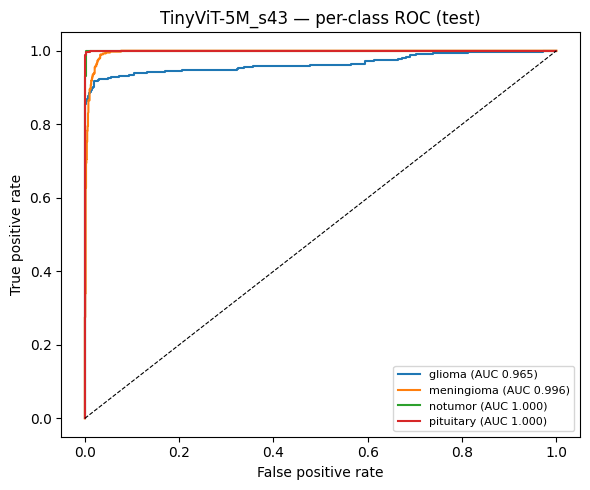

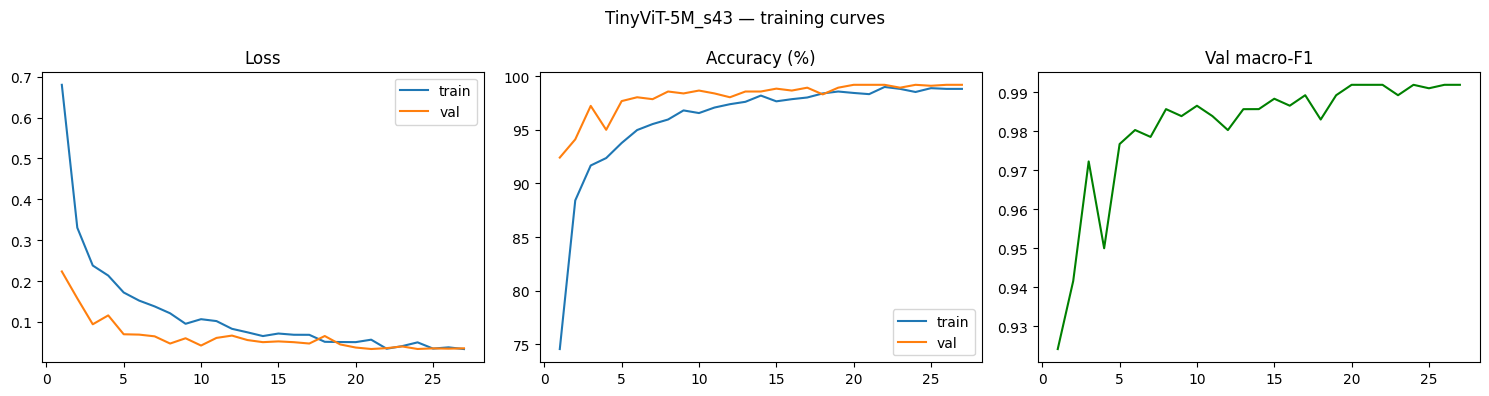

              precision    recall  f1-score   support

      glioma     1.0000    0.8300    0.9071       400
  meningioma     0.9041    0.9900    0.9451       400
     notumor     0.9390    1.0000    0.9685       400
   pituitary     0.9876    0.9975    0.9925       400

    accuracy                         0.9544      1600
   macro avg     0.9577    0.9544    0.9533      1600
weighted avg     0.9577    0.9544    0.9533      1600

DONE TinyViT-5M_s43 | test accuracy 95.44% | macro-F1 0.9533 | best epoch 22
  [stage complete] train:TinyViT-5M_s43

TRAINING TinyViT-5M_s44 (tiny_vit_5m_224) on cuda — resumable, run once
  Epoch 01/30 | train 0.6505/77.59% | val 0.1951/93.93% | valF1 0.9395 | lr 1.00e-04 | ETA 23 min
    * new best — weights saved (val macro-F1 0.9395)
  Epoch 02/30 | train 0.3102/89.02% | val 0.1335/95.54% | valF1 0.9554 | lr 9.97e-05 | ETA 22 min
    * new best — weights saved (val macro-F1 0.9554)
  Epoch 03/30 | train 0.2401/91.63% | val 0.1193/96.16% | valF1 0.9617 | 

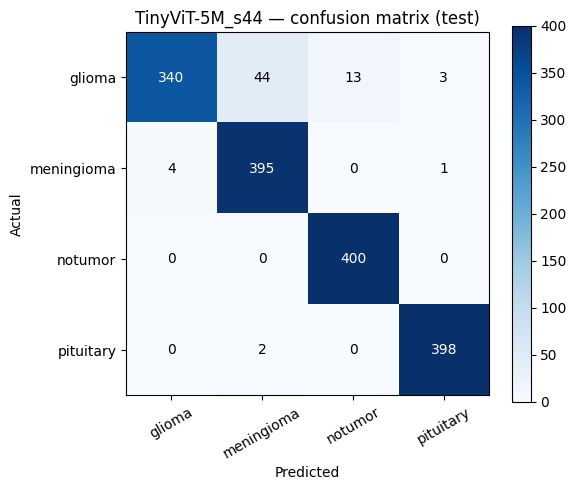

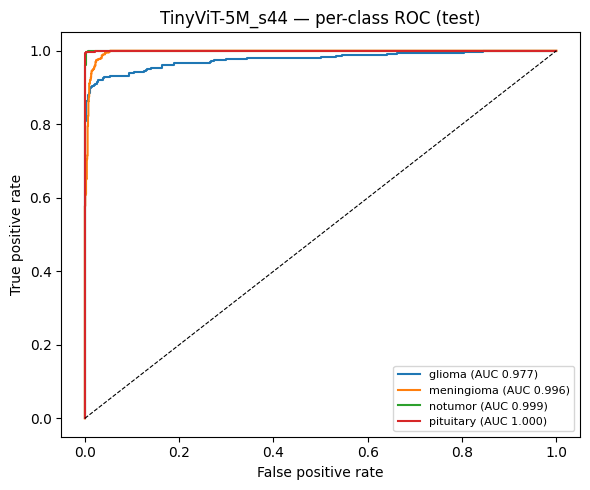

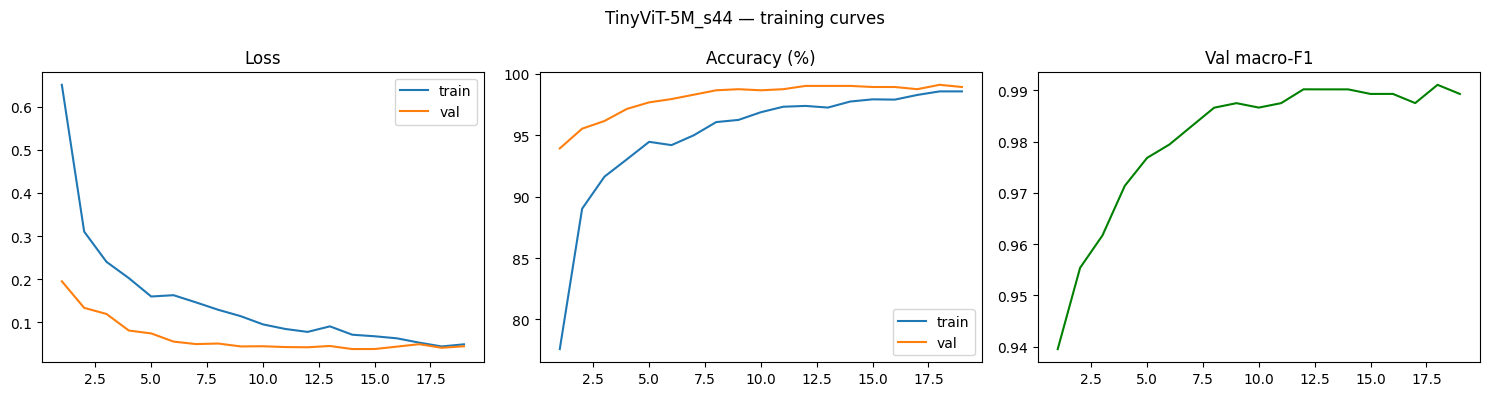

              precision    recall  f1-score   support

      glioma     0.9884    0.8500    0.9140       400
  meningioma     0.8957    0.9875    0.9394       400
     notumor     0.9685    1.0000    0.9840       400
   pituitary     0.9900    0.9950    0.9925       400

    accuracy                         0.9581      1600
   macro avg     0.9607    0.9581    0.9575      1600
weighted avg     0.9607    0.9581    0.9575      1600

DONE TinyViT-5M_s44 | test accuracy 95.81% | macro-F1 0.9575 | best epoch 18
  [stage complete] train:TinyViT-5M_s44


,run,seed,test acc (%),macro-F1
0,TinyViT-5M,42,96.12,0.9607
1,TinyViT-5M_s43,43,95.44,0.9533
2,TinyViT-5M_s44,44,95.81,0.9575


  TinyViT-5M across 3 seeds: acc 95.79% ± 0.28 pp | macro-F1 0.9572 ± 0.0030
  [stage complete] seed_stability


In [24]:
# ============================================================================
# STAGE 12 · SEED STABILITY — the best model, three seeds.
# One number from one seed is a sample of one; the honest report is mean ±
# std. The best model is re-trained at seeds 43 and 44 into its own model
# directories (canonical seed-42 artifacts are never overwritten).
# ============================================================================
stage = "seed_stability"
if stage_done(stage):
    print("SKIP seed_stability — see results/seed_stability.json")
else:
    best_name = df.iloc[0]["Model"]
    spec, mtype = Config.MODELS[best_name]
    for seed in (43, 44):
        train_one_model(f"{best_name}_s{seed}", spec, mtype, seed=seed)

    rows = []
    for name in (best_name, f"{best_name}_s43", f"{best_name}_s44"):
        ev = json.loads((Config.MODELS_DIR / name / "eval.json").read_text(encoding="utf-8"))
        rows.append({"run": name, "seed": ev["seed"],
                     "test acc (%)": round(ev["accuracy"] * 100, 2),
                     "macro-F1": round(ev["f1_macro"], 4)})
    sdf = pd.DataFrame(rows)
    display(sdf)
    accs = np.array([r["test acc (%)"] for r in rows])
    f1s  = np.array([r["macro-F1"] for r in rows])
    atomic_write_json(Config.RESULTS_DIR / "seed_stability.json",
                      {"best_model": best_name, "runs": rows,
                       "acc_mean": float(accs.mean()), "acc_std_pp": float(accs.std()),
                       "f1_mean": float(f1s.mean()), "f1_std": float(f1s.std())})
    print(f"  {best_name} across 3 seeds: acc {accs.mean():.2f}% ± {accs.std():.2f} pp "
          f"| macro-F1 {f1s.mean():.4f} ± {f1s.std():.4f}")
    mark_stage(stage, {"best_model": best_name})


## Stage 13 — cluster-disjoint re-split: the leakage-proof exam

**Why this stage exists:** the official split scatters the same patient's slices across both sides, so every benchmark score is partly memorization. Here the near-duplicate links are chained into **families** (dual evidence: perceptual hash *and* deep-feature similarity — no single weak signal), a fresh split is drawn moving **whole families only** (stratified so classes stay balanced), and **every model is retrained from zero** on it and graded on a ~20% family-disjoint exam. Leakage on this exam is structurally impossible — the strongest tier of the project. The official results stay untouched: the *comparison between the tiers* is the finding.


  fingerprinting 7200 images (pHash + deep features, one-time) ...


model.safetensors: reconstructing file:   0%|          |  0.00B / 46.8MB            

model.safetensors: downloading bytes:           |  0.00B            

  dual-evidence near-duplicate links: 4121
  families: 5279 (928 with >1 image); >50-image families: 0 (largest 26); cross-class families (label disagreements): 4
  disjoint split: train 4602 / val 1158 / test 1440 (families: 5279)
  [stage complete] cluster_split

TRAINING Baseline-CNN-disjoint (BaselineCNN) on cuda — resumable, run once
  Epoch 01/30 | train 1.2958/37.31% | val 1.1944/44.91% | valF1 0.3731 | lr 1.00e-04 | ETA 16 min
    * new best — weights saved (val macro-F1 0.3731)
  Epoch 02/30 | train 1.2263/41.79% | val 1.1623/47.06% | valF1 0.4310 | lr 9.97e-05 | ETA 15 min
    * new best — weights saved (val macro-F1 0.4310)
  Epoch 03/30 | train 1.2056/44.48% | val 1.1478/55.53% | valF1 0.5311 | lr 9.89e-05 | ETA 15 min
    * new best — weights saved (val macro-F1 0.5311)
  Epoch 04/30 | train 1.1780/45.31% | val 1.1349/51.90% | valF1 0.4990 | lr 9.76e-05 | ETA 14 min
  Epoch 05/30 | train 1.1780/45.72% | val 1.1259/49.74% | valF1 0.4607 | lr 9.57e-05 | ETA 14 min
  Epoch 06

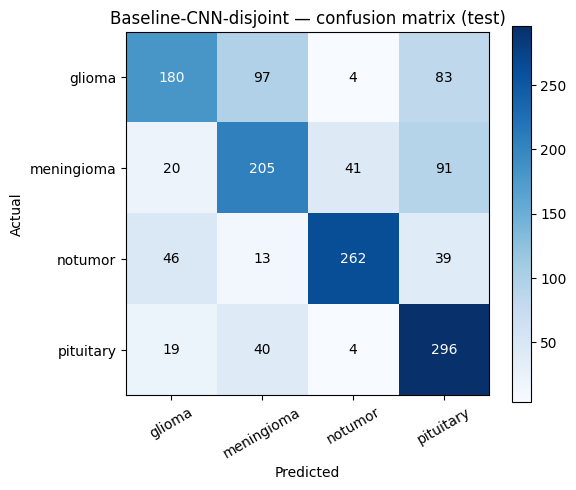

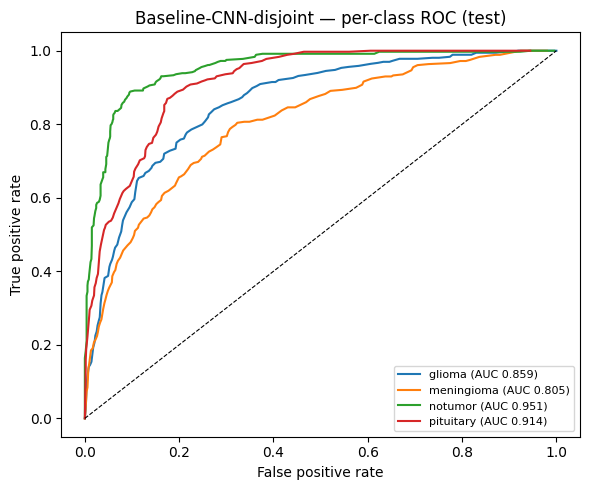

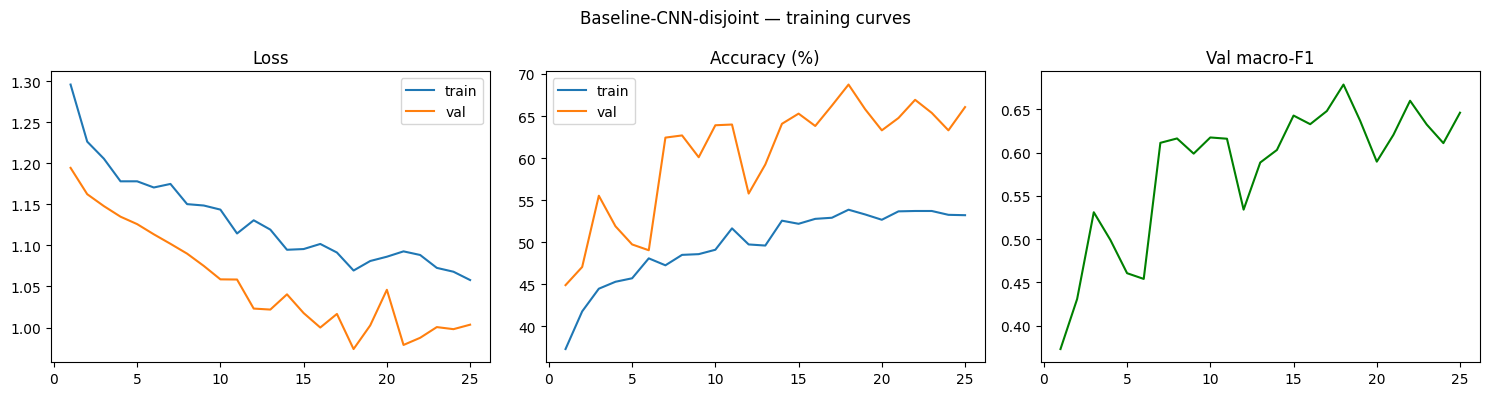

              precision    recall  f1-score   support

      glioma     0.6792    0.4945    0.5723       364
  meningioma     0.5775    0.5742    0.5758       357
     notumor     0.8424    0.7278    0.7809       360
   pituitary     0.5815    0.8245    0.6820       359

    accuracy                         0.6549      1440
   macro avg     0.6702    0.6553    0.6528      1440
weighted avg     0.6705    0.6549    0.6527      1440

DONE Baseline-CNN-disjoint | test accuracy 65.49% | macro-F1 0.6528 | best epoch 18
  [stage complete] train:Baseline-CNN-disjoint

TRAINING EfficientNet-B0-disjoint (efficientnet_b0) on cuda — resumable, run once
  Epoch 01/30 | train 1.1507/68.01% | val 0.7913/83.33% | valF1 0.8280 | lr 1.00e-04 | ETA 27 min
    * new best — weights saved (val macro-F1 0.8280)
  Epoch 02/30 | train 0.6572/78.77% | val 0.6437/84.54% | valF1 0.8441 | lr 9.97e-05 | ETA 23 min
    * new best — weights saved (val macro-F1 0.8441)
  Epoch 03/30 | train 0.4227/86.70% | val 0.4122/

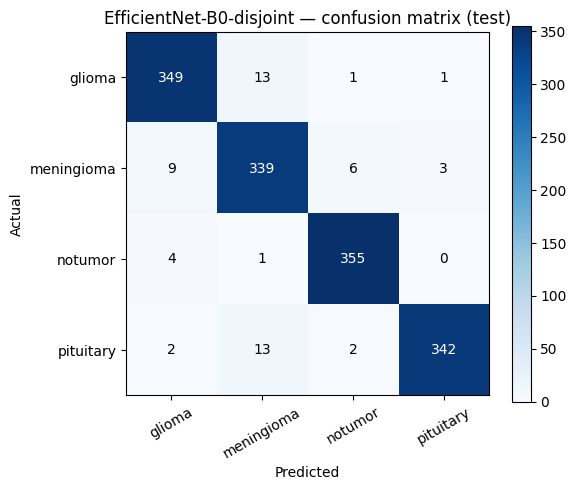

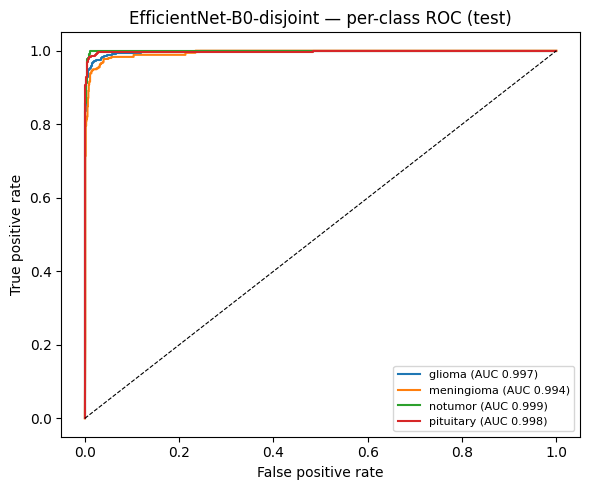

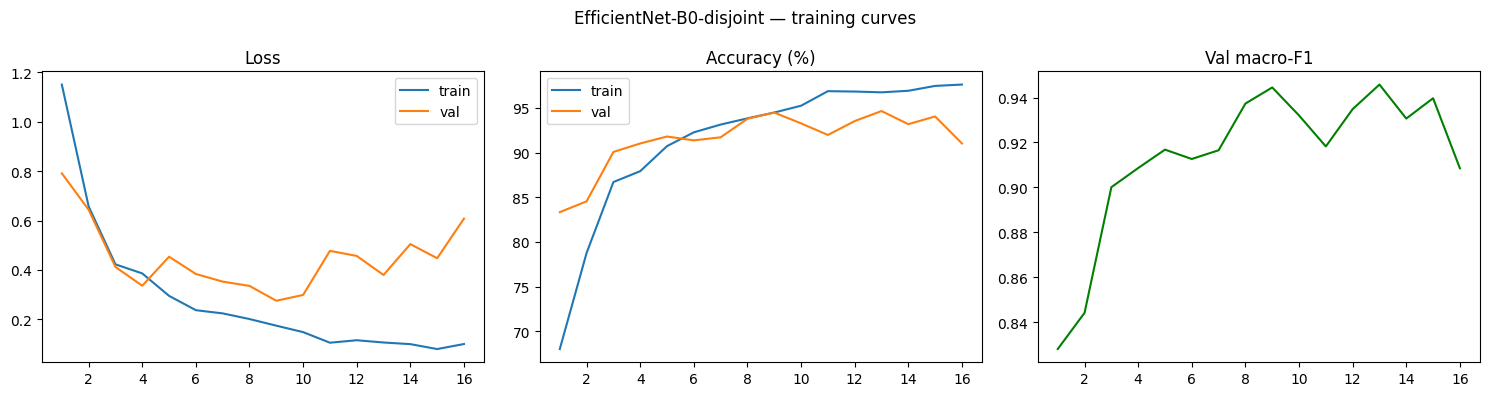

              precision    recall  f1-score   support

      glioma     0.9588    0.9588    0.9588       364
  meningioma     0.9262    0.9496    0.9378       357
     notumor     0.9753    0.9861    0.9807       360
   pituitary     0.9884    0.9526    0.9702       359

    accuracy                         0.9618      1440
   macro avg     0.9622    0.9618    0.9619      1440
weighted avg     0.9622    0.9618    0.9619      1440

DONE EfficientNet-B0-disjoint | test accuracy 96.18% | macro-F1 0.9619 | best epoch 13
  [stage complete] train:EfficientNet-B0-disjoint

TRAINING MobileNetV3-Small-disjoint (mobilenetv3_small_100) on cuda — resumable, run once
  Epoch 01/30 | train 1.2777/66.08% | val 0.5899/83.33% | valF1 0.8255 | lr 1.00e-04 | ETA 20 min
    * new best — weights saved (val macro-F1 0.8255)
  Epoch 02/30 | train 0.6160/80.07% | val 0.7164/83.25% | valF1 0.8239 | lr 9.97e-05 | ETA 17 min
  Epoch 03/30 | train 0.4416/85.18% | val 0.7227/86.79% | valF1 0.8661 | lr 9.89e-05 | E

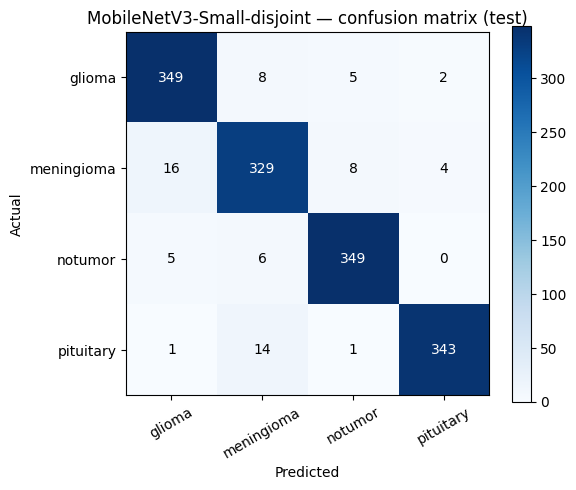

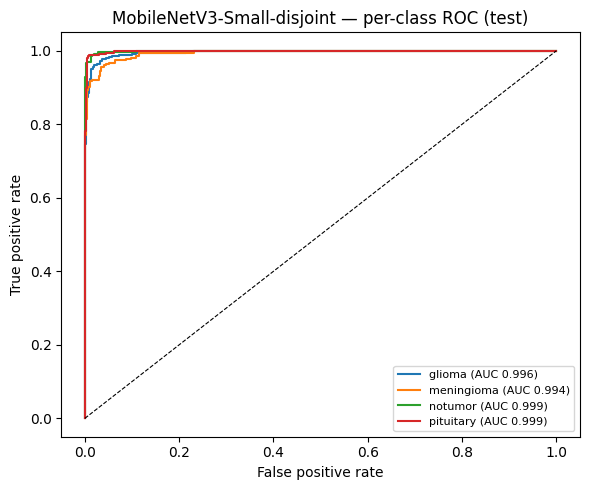

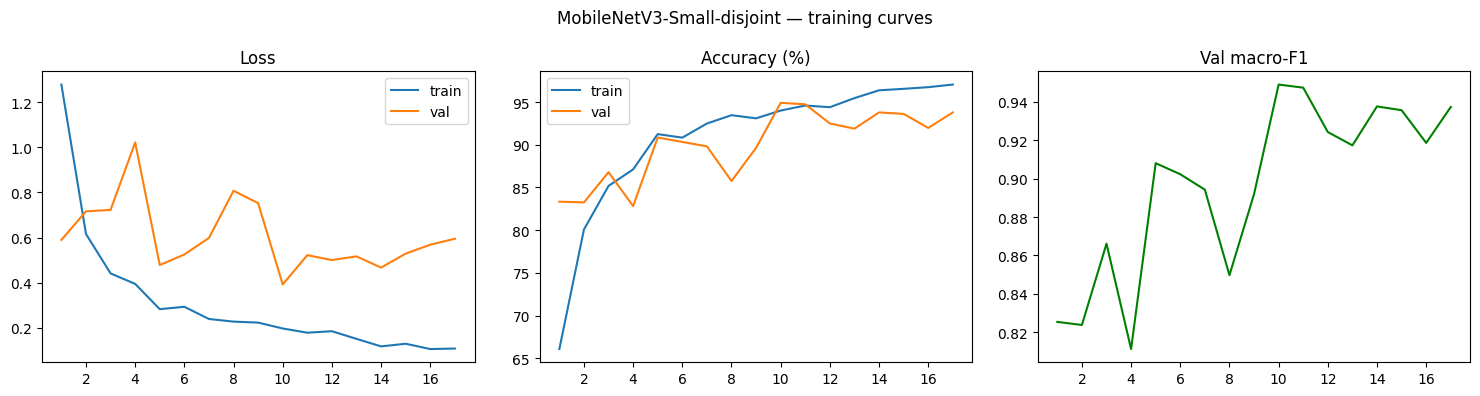

              precision    recall  f1-score   support

      glioma     0.9407    0.9588    0.9497       364
  meningioma     0.9216    0.9216    0.9216       357
     notumor     0.9614    0.9694    0.9654       360
   pituitary     0.9828    0.9554    0.9689       359

    accuracy                         0.9514      1440
   macro avg     0.9516    0.9513    0.9514      1440
weighted avg     0.9516    0.9514    0.9514      1440

DONE MobileNetV3-Small-disjoint | test accuracy 95.14% | macro-F1 0.9514 | best epoch 10
  [stage complete] train:MobileNetV3-Small-disjoint

TRAINING MobileViT-S-disjoint (mobilevit_s) on cuda — resumable, run once
  Epoch 01/30 | train 0.8602/69.62% | val 0.4957/83.16% | valF1 0.8255 | lr 1.00e-04 | ETA 33 min
    * new best — weights saved (val macro-F1 0.8255)
  Epoch 02/30 | train 0.4836/83.09% | val 0.4134/88.60% | valF1 0.8843 | lr 9.97e-05 | ETA 31 min
    * new best — weights saved (val macro-F1 0.8843)
  Epoch 03/30 | train 0.3870/86.81% | val 0.229

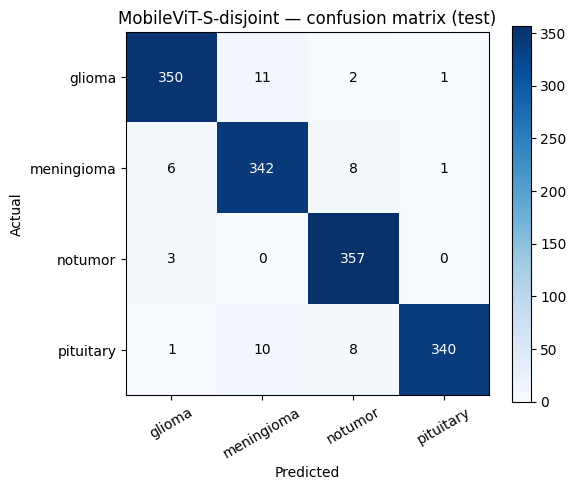

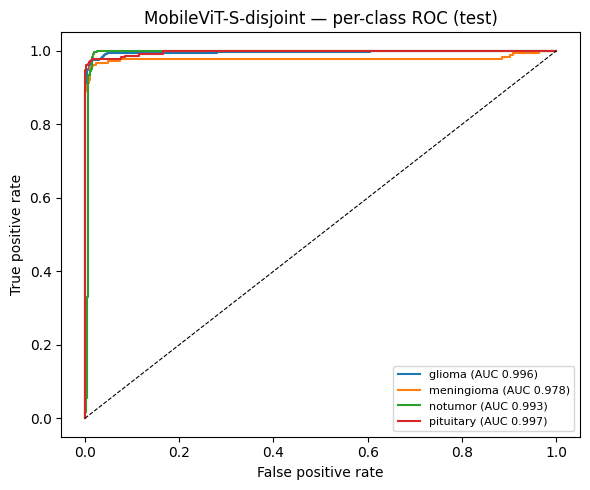

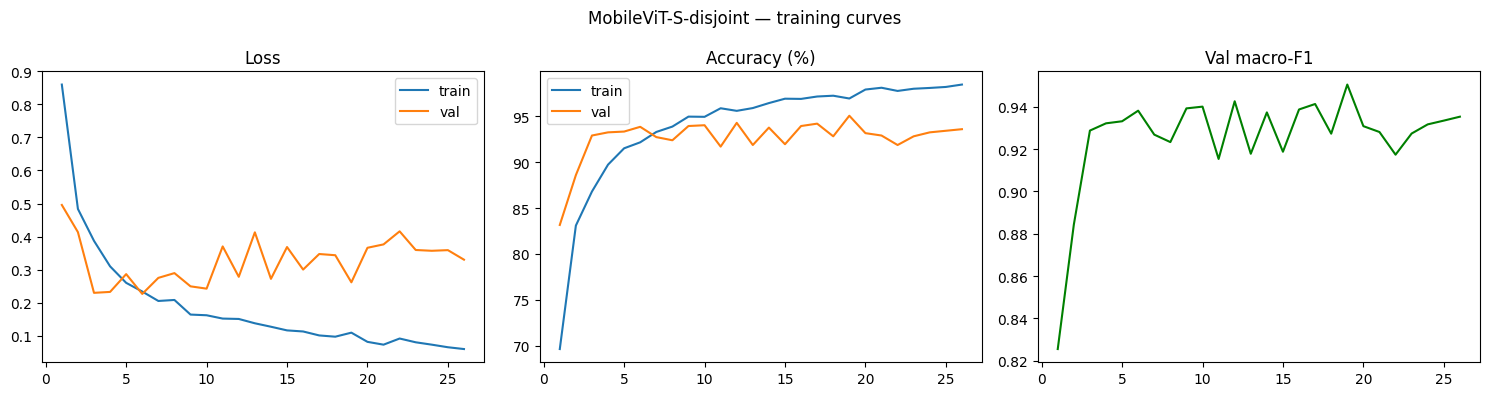

              precision    recall  f1-score   support

      glioma     0.9722    0.9615    0.9669       364
  meningioma     0.9421    0.9580    0.9500       357
     notumor     0.9520    0.9917    0.9714       360
   pituitary     0.9942    0.9471    0.9700       359

    accuracy                         0.9646      1440
   macro avg     0.9651    0.9646    0.9646      1440
weighted avg     0.9652    0.9646    0.9646      1440

DONE MobileViT-S-disjoint | test accuracy 96.46% | macro-F1 0.9646 | best epoch 19
  [stage complete] train:MobileViT-S-disjoint

TRAINING DeiT-Tiny-disjoint (deit_tiny_patch16_224) on cuda — resumable, run once
  Epoch 01/30 | train 0.5669/77.92% | val 0.2980/91.88% | valF1 0.9185 | lr 1.00e-04 | ETA 16 min
    * new best — weights saved (val macro-F1 0.9185)
  Epoch 02/30 | train 0.3525/87.05% | val 0.4887/86.18% | valF1 0.8529 | lr 9.97e-05 | ETA 16 min
  Epoch 03/30 | train 0.2984/88.81% | val 0.2765/92.40% | valF1 0.9232 | lr 9.89e-05 | ETA 15 min
    * 

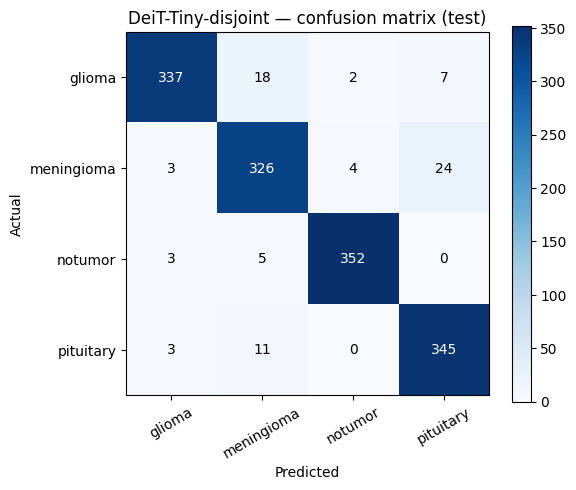

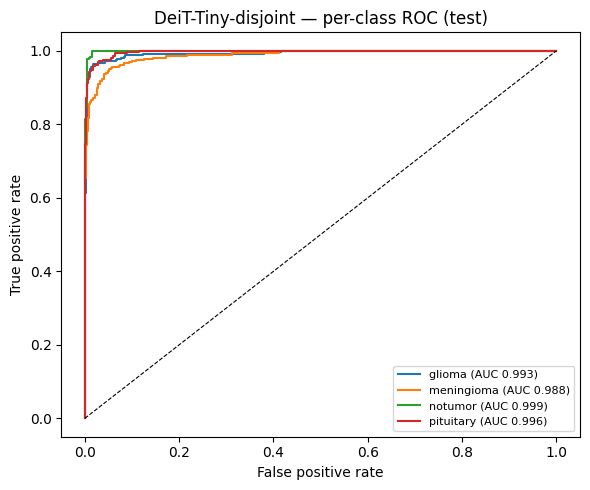

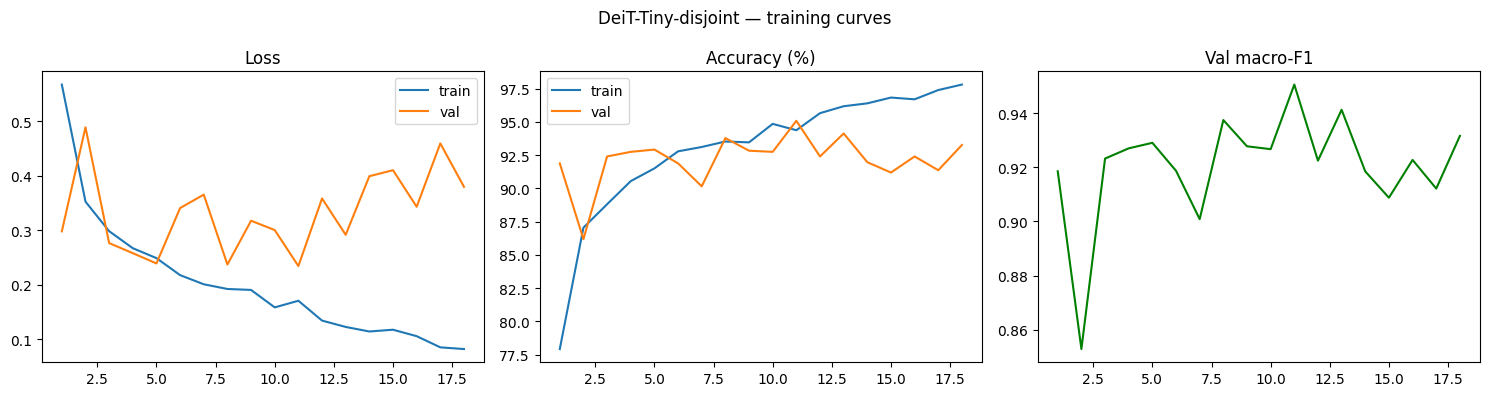

              precision    recall  f1-score   support

      glioma     0.9740    0.9258    0.9493       364
  meningioma     0.9056    0.9132    0.9093       357
     notumor     0.9832    0.9778    0.9805       360
   pituitary     0.9176    0.9610    0.9388       359

    accuracy                         0.9444      1440
   macro avg     0.9451    0.9444    0.9445      1440
weighted avg     0.9453    0.9444    0.9446      1440

DONE DeiT-Tiny-disjoint | test accuracy 94.44% | macro-F1 0.9445 | best epoch 11
  [stage complete] train:DeiT-Tiny-disjoint

TRAINING TinyViT-5M-disjoint (tiny_vit_5m_224) on cuda — resumable, run once
  Epoch 01/30 | train 0.6639/75.92% | val 0.2793/91.80% | valF1 0.9177 | lr 1.00e-04 | ETA 25 min
    * new best — weights saved (val macro-F1 0.9177)
  Epoch 02/30 | train 0.3121/88.83% | val 0.2847/91.02% | valF1 0.9082 | lr 9.97e-05 | ETA 24 min
  Epoch 03/30 | train 0.2351/91.98% | val 0.1838/94.21% | valF1 0.9424 | lr 9.89e-05 | ETA 22 min
    * new best 

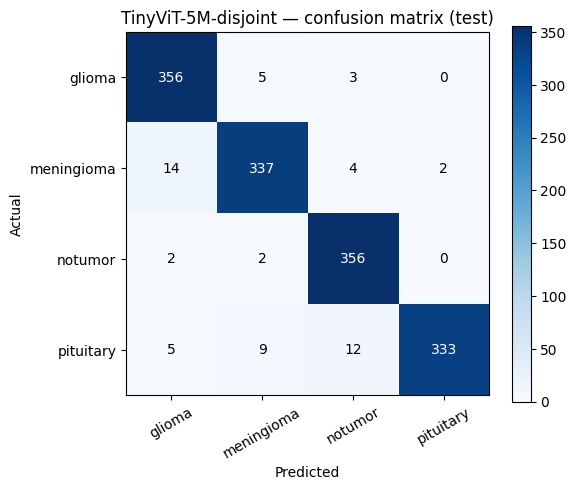

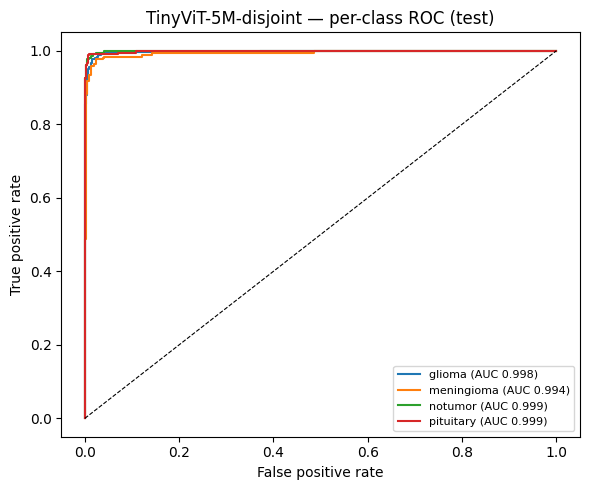

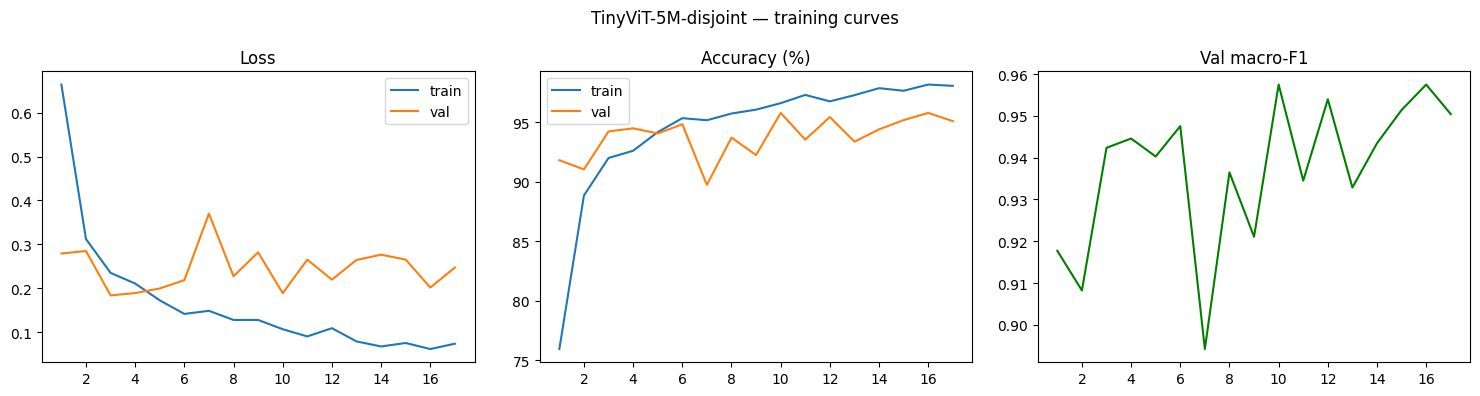

              precision    recall  f1-score   support

      glioma     0.9443    0.9780    0.9609       364
  meningioma     0.9547    0.9440    0.9493       357
     notumor     0.9493    0.9889    0.9687       360
   pituitary     0.9940    0.9276    0.9597       359

    accuracy                         0.9597      1440
   macro avg     0.9606    0.9596    0.9596      1440
weighted avg     0.9605    0.9597    0.9597      1440

DONE TinyViT-5M-disjoint | test accuracy 95.97% | macro-F1 0.9596 | best epoch 10
  [stage complete] train:TinyViT-5M-disjoint

TRAINING ResNet-50-disjoint (resnet50) on cuda — resumable, run once
  Epoch 01/30 | train 1.1898/52.78% | val 0.7271/76.17% | valF1 0.7525 | lr 1.00e-04 | ETA 30 min
    * new best — weights saved (val macro-F1 0.7525)
  Epoch 02/30 | train 0.7108/72.95% | val 0.5073/81.00% | valF1 0.7961 | lr 9.97e-05 | ETA 29 min
    * new best — weights saved (val macro-F1 0.7961)
  Epoch 03/30 | train 0.5216/79.90% | val 0.4820/82.21% | valF1 0.

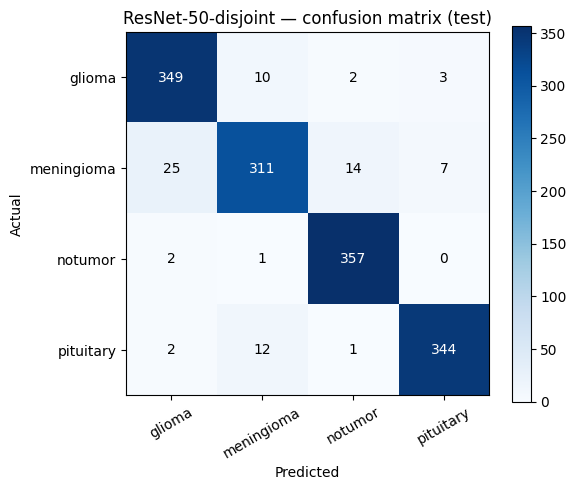

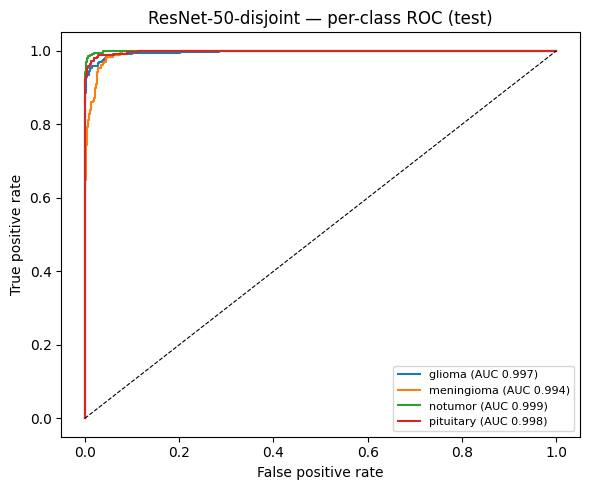

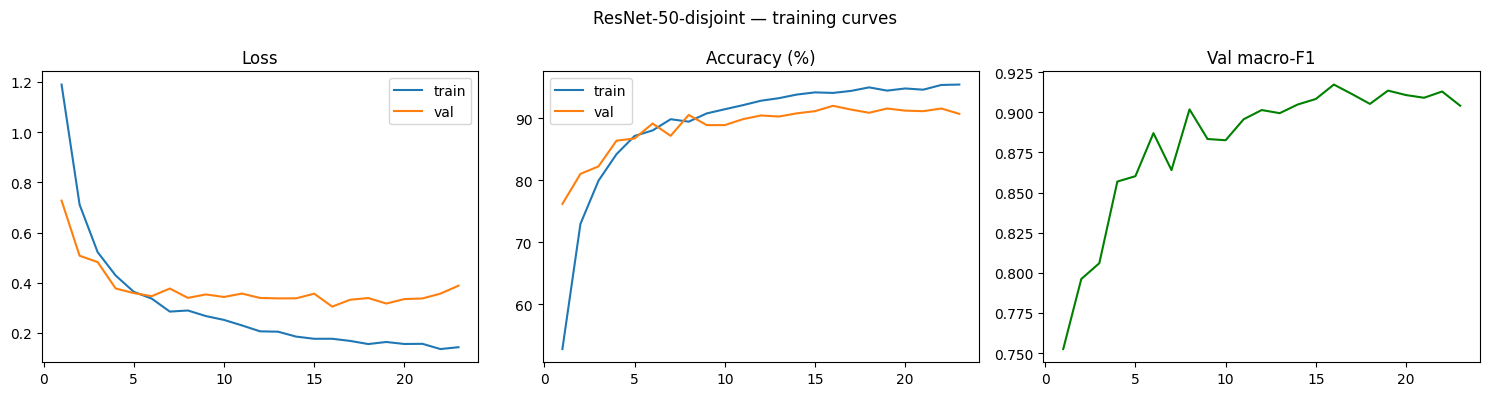

              precision    recall  f1-score   support

      glioma     0.9233    0.9588    0.9407       364
  meningioma     0.9311    0.8711    0.9001       357
     notumor     0.9545    0.9917    0.9728       360
   pituitary     0.9718    0.9582    0.9649       359

    accuracy                         0.9451      1440
   macro avg     0.9452    0.9450    0.9446      1440
weighted avg     0.9451    0.9451    0.9447      1440

DONE ResNet-50-disjoint | test accuracy 94.51% | macro-F1 0.9446 | best epoch 16
  [stage complete] train:ResNet-50-disjoint

TRAINING Xception-Reference-disjoint (xception) on cuda — resumable, run once
  Epoch 01/30 | train 0.5478/79.73% | val 0.2691/91.19% | valF1 0.9108 | lr 1.00e-04 | ETA 117 min
    * new best — weights saved (val macro-F1 0.9108)
  Epoch 02/30 | train 0.2566/91.66% | val 0.2815/91.62% | valF1 0.9151 | lr 9.97e-05 | ETA 112 min
    * new best — weights saved (val macro-F1 0.9151)
  Epoch 03/30 | train 0.2130/93.26% | val 0.3100/91.71% |

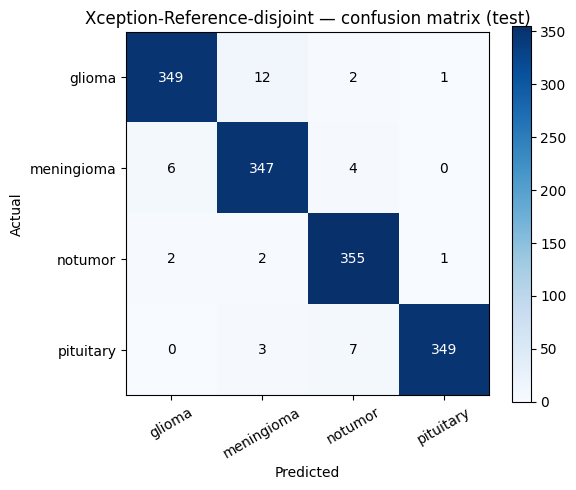

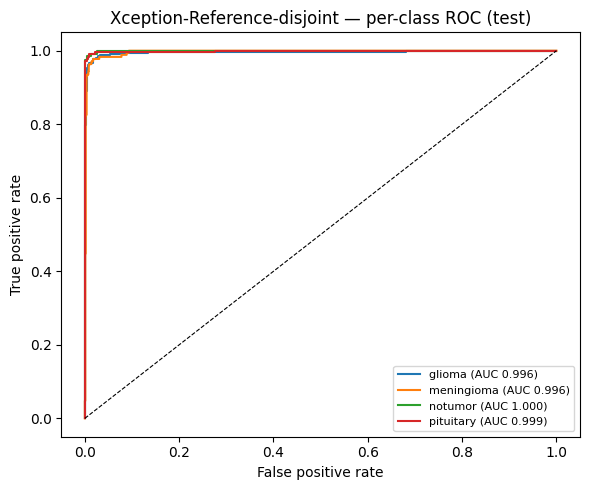

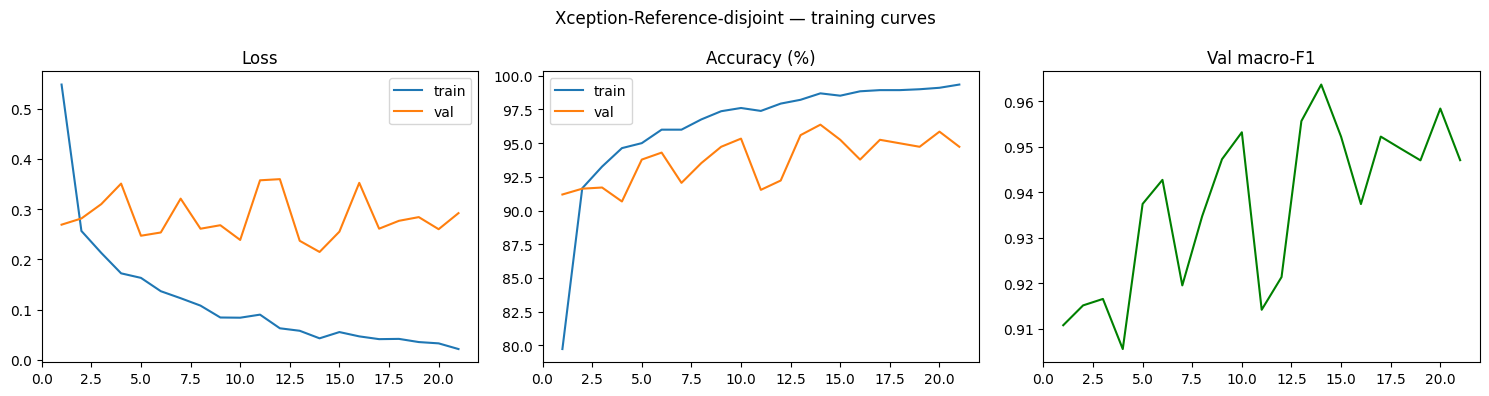

              precision    recall  f1-score   support

      glioma     0.9776    0.9588    0.9681       364
  meningioma     0.9533    0.9720    0.9626       357
     notumor     0.9647    0.9861    0.9753       360
   pituitary     0.9943    0.9721    0.9831       359

    accuracy                         0.9722      1440
   macro avg     0.9725    0.9723    0.9723      1440
weighted avg     0.9725    0.9722    0.9723      1440

DONE Xception-Reference-disjoint | test accuracy 97.22% | macro-F1 0.9723 | best epoch 14
  [stage complete] train:Xception-Reference-disjoint


,Model,Official split acc (%),Disjoint acc (%),Official macro-F1,Disjoint macro-F1,Disjoint n
0,Xception-Reference,95.19,97.22,0.9510,0.9723,1440
1,MobileViT-S,95.19,96.46,0.9513,0.9646,1440
2,EfficientNet-B0,95.19,96.18,0.9509,0.9619,1440
3,TinyViT-5M,96.12,95.97,0.9607,0.9596,1440
4,MobileNetV3-Small,95.12,95.14,0.9507,0.9514,1440
5,ResNet-50,95.25,94.51,0.9519,0.9446,1440
6,DeiT-Tiny,95.38,94.44,0.9533,0.9445,1440
7,Baseline-CNN,65.81,65.49,0.6515,0.6528,1440


  Every architecture, retrained from zero with families intact — the gap to the official column is the leakage premium, measured.
  [stage complete] cluster_eval


In [25]:
# ============================================================================
# STAGE 13 · CLUSTER-DISJOINT RE-SPLIT — the leakage-proof exam.
# Method follows the published audits of this benchmark (SSRN 7493561; Bassi
# 2026, Zenodo 22721030): pairs need DUAL evidence (pHash Hamming<=8 AND
# deep-feature cosine>=0.95 — a lone weak signal never merges two images),
# families = connected components of that strict graph with a size audit,
# the split moves whole families, stratified by majority class, and every
# model is retrained from zero so grading on this exam is honest.
# ============================================================================
stage = "cluster_split"
cpath = Config.RESULTS_DIR / "cluster_split.json"
if stage_done(stage):
    cluster_split = json.loads(cpath.read_text(encoding="utf-8"))
    print(f"SKIP cluster_split — loaded: {cluster_split['n_clusters']} families, "
          f"{len(cluster_split['test'])} disjoint-test images")
else:
    import imagehash
    from PIL import Image
    from scipy.sparse import coo_matrix
    from scipy.sparse.csgraph import connected_components

    all_files = sorted(set(split["train"] + split["val"] + split["test"]))
    paths = [DATA_DIR / p for p in all_files]
    labs = np.array([CLASS_TO_IDX[p.split("/")[1]] for p in all_files])
    n = len(paths)
    print(f"  fingerprinting {n} images (pHash + deep features, one-time) ...")

    def ph2u64(h):
        v = 0
        for bit in np.asarray(h.hash).flatten():
            v = (v << 1) | int(bit)
        return v

    hs = np.zeros(n, dtype=np.uint64)
    feats = np.zeros((n, 512), dtype=np.float32)
    feat_net = timm.create_model("resnet18", pretrained=True, num_classes=0)
    feat_net = feat_net.to(DEVICE).eval()
    B = 64
    with torch.no_grad():
        for i in range(0, n, B):
            chunk = paths[i:i + B]
            xs = []
            for p in chunk:
                with Image.open(p) as im:
                    hs[i + len(xs)] = ph2u64(imagehash.phash(im))
                img = cv2.imread(str(p))
                img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
                img = cv2.resize(img, (224, 224), interpolation=cv2.INTER_AREA)
                xs.append(img)
            xb = torch.from_numpy(np.stack(xs)).permute(0, 3, 1, 2).float().div_(255)
            xb = (xb - torch.tensor(Config.NORM_MEAN).view(1, 3, 1, 1)) / \
                 torch.tensor(Config.NORM_STD).view(1, 3, 1, 1)
            feats[i:i + len(xs)] = feat_net(xb.to(DEVICE)).cpu().numpy()
    del feat_net
    torch.cuda.empty_cache()
    fn = feats / (np.linalg.norm(feats, axis=1, keepdims=True) + 1e-8)

    # pairwise masks — blockwise to bound memory
    link_i, link_j = [], []
    for i0 in range(0, n, 1024):
        i1 = min(i0 + 1024, n)
        hb = np.bitwise_count(hs[i0:i1, None] ^ hs[None, :])
        cb = fn[i0:i1] @ fn.T
        m = (hb <= 8) & (cb >= 0.95)
        ii, jj = np.where(m)
        keep = (ii + i0) > jj          # upper triangle — each pair once
        link_i.append(ii[keep] + i0); link_j.append(jj[keep])
    link_i = np.concatenate(link_i); link_j = np.concatenate(link_j)
    print(f"  dual-evidence near-duplicate links: {len(link_i)}")

    g = coo_matrix((np.ones(len(link_i)), (link_i, link_j)), shape=(n, n))
    n_comp, comp_ids = connected_components(g, directed=False)
    sizes = np.bincount(comp_ids)
    multi = int((sizes > 1).sum())
    big = sizes[sizes > 50]
    cross = 0
    for cid in range(n_comp):
        if sizes[cid] > 1 and len(set(labs[comp_ids == cid].tolist())) > 1:
            cross += 1
    print(f"  families: {n_comp} ({multi} with >1 image); "
          f">{50}-image families: {len(big)} (largest {sizes.max()}); "
          f"cross-class families (label disagreements): {cross}")

    # stratified family assignment: per class, shuffle families, fill the
    # disjoint-test side to ~20% of that class's images, then carve val (~20%
    # of the remainder) from the train side — families never split apart
    rng = np.random.RandomState(Config.SEED)
    fam_test = []
    per_target = {i: int((labs == i).sum() * 0.20) for i in range(Config.NUM_CLASSES)}
    fam_of = comp_ids
    for ci in range(Config.NUM_CLASSES):
        fams = [f for f in range(n_comp)
                if any(labs[k] == ci for k in np.where(fam_of == f)[0]) and f not in fam_test]
        fams.sort(key=lambda f: -sizes[f])
        order = rng.permutation([f for f in fams if sizes[f] <= 10])
        rest = [f for f in fams if f not in order]
        got = 0
        for f in list(order) + rest:
            if got >= per_target[ci]:
                break
            fam_test.append(f)
            got += int(sizes[f])
    test_mask = np.isin(fam_of, fam_test)
    val_target = {i: int((labs == i).sum() * 0.16) for i in range(Config.NUM_CLASSES)}
    fam_val = []
    for ci in range(Config.NUM_CLASSES):
        fams = [f for f in range(n_comp)
                if not test_mask[np.where(fam_of == f)[0]].any()
                and any(labs[k] == ci for k in np.where(fam_of == f)[0])
                and f not in fam_val]
        fams.sort(key=lambda f: -sizes[f])
        got = 0
        for f in fams:
            if got >= val_target[ci]:
                break
            fam_val.append(f)
            got += int(sizes[f])
    val_mask = np.isin(fam_of, fam_val) & ~test_mask
    assert not (test_mask & val_mask).any()
    cluster_split = {"train": [all_files[i] for i in np.where(~test_mask & ~val_mask)[0]],
                    "val":   [all_files[i] for i in np.where(val_mask)[0]],
                    "test":  [all_files[i] for i in np.where(test_mask)[0]]}
    # final guarantee: no family crosses a boundary
    side = np.where(test_mask, 2, np.where(val_mask, 1, 0))
    for f in range(n_comp):
        assert len(set(side[comp_ids == f].tolist())) == 1, f"family {f} crosses a boundary"
    atomic_write_json(cpath, {**cluster_split, "n_clusters": int(n_comp),
                              "n_links": int(len(link_i)), "n_cross_class": cross})
    print(f"  disjoint split: train {len(cluster_split['train'])} / "
          f"val {len(cluster_split['val'])} / test {len(cluster_split['test'])} "
          f"(families: {n_comp})")
    mark_stage(stage, {"n_clusters": int(n_comp), "test_images": len(cluster_split["test"])})

# ---- retrain every model from zero on the leakage-proof split ----
for mname, (spec, mtype) in Config.MODELS.items():
    train_one_model(f"{mname}-disjoint", spec, mtype, split_dict=cluster_split)

# ---- score the leakage-proof exam ----
stage = "cluster_eval"
if stage_done(stage):
    print("SKIP cluster_eval — see results/cluster_report.json")
else:
    rows = []
    for mname in Config.MODELS:
        dname = f"{mname}-disjoint"
        ev = json.loads((Config.MODELS_DIR / dname / "eval.json").read_text(encoding="utf-8"))
        full = json.loads((Config.MODELS_DIR / mname / "eval.json").read_text(encoding="utf-8"))
        rows.append({"Model": mname,
                     "Official split acc (%)": round(full["accuracy"] * 100, 2),
                     "Disjoint acc (%)": round(ev["accuracy"] * 100, 2),
                     "Official macro-F1": round(full["f1_macro"], 4),
                     "Disjoint macro-F1": round(ev["f1_macro"], 4),
                     "Disjoint n": ev["n_test"]})
    ddf = pd.DataFrame(rows).sort_values("Disjoint macro-F1", ascending=False).reset_index(drop=True)
    display(ddf)
    atomic_write_json(Config.RESULTS_DIR / "cluster_report.json",
                      {"rule": "families never cross the split; dual-evidence links "
                               "(pHash<=8 AND cosine>=0.95)",
                       "n_test": len(cluster_split["test"]), "rows": rows})
    print("  Every architecture, retrained from zero with families intact — "
          "the gap to the official column is the leakage premium, measured.")
    mark_stage(stage, {"best": ddf.iloc[0]["Model"]})

## Stage 14 — ensembles: does combining models beat the leak?

**Why this stage exists:** an ensemble (averaging several models' probabilities) is the classic "just squeeze more accuracy" move. The honest question is whether its gain survives the clean exams — or whether the ensemble is also largely patient-recognition. Two ensembles, both computed from already-trained weights: the five lightweight architectures on the official + clean exams, and their family-disjoint counterparts on the leakage-proof exam. Zero training involved.


In [26]:
# ============================================================================
# STAGE 14 · ENSEMBLES — the five lightweight architectures, averaged.
# Softmax probabilities are averaged across the five models (a standard
# probability-vote ensemble) and scored on every exam tier they can legally
# be scored on: official, clean subset, and — for the retrained
# family-disjoint counterparts — the leakage-proof exam.
# ============================================================================
stage = "ensemble"
if stage_done(stage):
    print("SKIP ensemble — see results/ensemble_report.json")
else:
    five = ["EfficientNet-B0", "MobileNetV3-Small", "MobileViT-S", "DeiT-Tiny", "TinyViT-5M"]
    from scipy.special import softmax as _softmax

    def ensemble_probs(names, files, size):
        outs = []
        for m in names:
            base = m.removesuffix("-disjoint")   # disjoint runs share the base model's spec
            model = build_model(Config.MODELS[base][0])
            model.load_state_dict(torch.load(Config.MODELS_DIR / m / "best_weights.pth",
                                             map_location=DEVICE, weights_only=False)["model"])
            model = model.to(DEVICE).eval()
            logits, labels = collect_logits(model, make_loader(
                BrainTumorDataset(files, get_eval_transforms(size), size)))
            outs.append(_softmax(logits, axis=1))
            del model
            gc.collect()
        return np.mean(outs, axis=0), labels   # outs is a list — np.mean, not list.mean

    report = {}
    probs, labels = ensemble_probs(five, split["test"], Config.IMG_SIZE)
    report["official_acc"] = float(accuracy_score(labels, probs.argmax(1)))
    report["official_macro_f1"] = float(f1_score(labels, probs.argmax(1), average="macro"))
    # clean-subset indices follow the exact Stage-11 rule (pHash Hamming<=8 vs train)
    import imagehash
    from PIL import Image
    def ph2u64(h):
        v = 0
        for bit in np.asarray(h.hash).flatten():
            v = (v << 1) | int(bit)
        return v
    tr_h = []
    for p in split["train"]:
        with Image.open(DATA_DIR / p) as im:
            tr_h.append(ph2u64(imagehash.phash(im)))
    tr_h = np.array(tr_h, dtype=np.uint64)
    te_h = []
    for p in split["test"]:
        with Image.open(DATA_DIR / p) as im:
            te_h.append(ph2u64(imagehash.phash(im)))
    te_h = np.array(te_h, dtype=np.uint64)
    dirty = (np.bitwise_count(te_h[:, None] ^ tr_h[None, :]) <= 8).any(axis=1)
    clean_idx = np.where(~dirty)[0]
    clean_files = [split["test"][i] for i in clean_idx]
    probs_c, labels_c = ensemble_probs(five, clean_files, Config.IMG_SIZE)
    report["clean_acc"] = float(accuracy_score(labels_c, probs_c.argmax(1)))
    report["clean_macro_f1"] = float(f1_score(labels_c, probs_c.argmax(1), average="macro"))
    # family-disjoint ensemble on the leakage-proof exam
    dn = [f"{m}-disjoint" for m in five]
    csj = json.loads((Config.RESULTS_DIR / "cluster_split.json").read_text(encoding="utf-8"))
    probs_d, labels_d = ensemble_probs(dn, csj["test"], Config.IMG_SIZE)
    report["disjoint_acc"] = float(accuracy_score(labels_d, probs_d.argmax(1)))
    report["disjoint_macro_f1"] = float(f1_score(labels_d, probs_d.argmax(1), average="macro"))
    atomic_write_json(Config.RESULTS_DIR / "ensemble_report.json", report)
    print(json.dumps(report, indent=2))
    mark_stage(stage, report)

{
  "official_acc": 0.95875,
  "official_macro_f1": 0.9581320902993098,
  "clean_acc": 0.8744292237442922,
  "clean_macro_f1": 0.8720108742452268,
  "disjoint_acc": 0.9729166666666667,
  "disjoint_macro_f1": 0.9729118544938369
}
  [stage complete] ensemble


## Stage 15 — final summary

In [27]:
# ============================================================================
# STAGE 15 · FINAL SUMMARY — generates results/SUMMARY.md
# (Assembled ONLY from the JSON/CSV records earlier stages wrote — nothing is
# recomputed, so a duplicate or contradictory number is structurally
# impossible. The original's version of this cell crashed after 3 lines
# because three incompatible result schemas coexisted.)
# Environment-aware: test count and training device come from
# environment.json instead of hard-coded text.
# ============================================================================
summary = []
summary.append("# Brain Tumor MRI Classification — v2 Clean Rebuild — Results Summary")
summary.append("")
summary.append(f"Generated: {datetime.now().isoformat(timespec='seconds')}")
summary.append("")
env = json.loads((Config.RESULTS_DIR / "environment.json").read_text(encoding="utf-8"))
summary.append("## Environment")
summary.append(f"- Machine: {env.get('machine', '?')} | training device: {env.get('training_device')}")
summary.append(f"- torch {env.get('pkg_torch')} | timm {env.get('pkg_timm')} | "
               f"sklearn {env.get('pkg_sklearn')} | numpy {env.get('pkg_numpy')}")
summary.append(f"- Dataset: {env.get('dataset_provenance', '')}")
if (Config.RESULTS_DIR / "data_quality.json").exists():
    dq = json.loads((Config.RESULTS_DIR / "data_quality.json").read_text(encoding="utf-8"))
    summary.append("")
    summary.append("## Data-quality audit (leakage disclosure)")
    for k, v in dq.items():
        if k != "note":
            summary.append(f"- {k}: {v}")
    summary.append(f"- {dq.get('note', '')}")
summary.append("")
test_images = env.get("dataset_counts", {}).get("test", {})
test_count = sum(test_images.values()) if test_images else "?"
summary.append(f"## Model comparison (sealed test set, {test_count} images)")
summary.append("```")
summary.append(df.to_string(index=False))
summary.append("```")
REFERENCE = {"DeiT-Tiny": 99.31, "TinyViT-5M": 99.24, "EfficientNet-B0": 98.93,
             "MobileViT-S": 98.86, "MobileNetV3-Small": 98.78}
summary.append("")
summary.append("Reference run (Azure CPU session, Nov 2025): " +
               ", ".join(f"{k} {v}%" for k, v in REFERENCE.items()))
summary.append("Note: the reference run was scored on Version 1 of this dataset "
               "(2021 release — 5,712/1,311 images, 103 exact train/test copies, "
               "approximate fallback metrics); this run uses the 2026 Version 2 "
               "(5,600/1,600, exact overlap removed). The two scores are NOT "
               "directly comparable.")
if (Config.EXPORT_DIR / "onnx_parity.json").exists():
    par = json.loads((Config.EXPORT_DIR / "onnx_parity.json").read_text(encoding="utf-8"))
    summary.append("")
    summary.append("## ONNX export parity (max |Δlogit| vs PyTorch, 8-image fixed batch)")
    for k, v in par.items():
        summary.append(f"- {k}: {v['max_abs_diff']:.2e} "
                       f"({'PASS' if v['parity_ok'] else 'FAIL'})")
if (Config.RESULTS_DIR / "benchmarks.csv").exists():
    b = pd.read_csv(Config.RESULTS_DIR / "benchmarks.csv")
    summary.append("")
    summary.append("## Inference speed (median; warmup 10; 100 iters @ batch 1, 30 @ batch 16)")
    summary.append("```")
    summary.append(b.to_string(index=False))
    summary.append("```")
if (Config.RESULTS_DIR / "clean_subset_report.json").exists():
    cs = json.loads((Config.RESULTS_DIR / "clean_subset_report.json").read_text(encoding="utf-8"))
    summary.append("")
    summary.append("## Honest-split evaluation — clean test subset")
    summary.append(f"Of the {test_count} test images, {cs['dirty_test_images']} share a "
                   f"perceptual hash (Hamming<=8) with a training image and were removed; "
                   f"the remaining {cs['clean_test_images']} behave like unseen patients. "
                   "The full-vs-clean gap is the leakage premium of this benchmark:")
    summary.append("```")
    for r in cs["rows"]:
        summary.append(f"{r['Model']}: full {r['Full test acc (%)']}% -> clean "
                       f"{r['Clean subset acc (%)']}% (drop {r['Drop (pp)']} pp)")
    summary.append("```")
if (Config.RESULTS_DIR / "seed_stability.json").exists():
    ss = json.loads((Config.RESULTS_DIR / "seed_stability.json").read_text(encoding="utf-8"))
    summary.append("")
    summary.append("## Seed stability")
    summary.append(f"- Best model ({ss['best_model']}), 3 seeds: test accuracy "
                   f"{ss['acc_mean']:.2f}% ± {ss['acc_std_pp']:.2f} pp | "
                   f"macro-F1 {ss['f1_mean']:.4f} ± {ss['f1_std']:.4f}")
summary.append("")
summary.append("## Notes")
summary.append(f"- Training device: {env.get('training_device', '?')} ({env.get('device_name', '?')}).")
summary.append("- Test metrics are per-image on a dataset containing duplicated and "
               "patient-correlated slices (see data-quality audit); the clean-subset "
               "and family-disjoint sections above are the honest estimates. Disclosed "
               "rather than hidden.")
if (Config.RESULTS_DIR / "cluster_report.json").exists():
    cr = json.loads((Config.RESULTS_DIR / "cluster_report.json").read_text(encoding="utf-8"))
    summary.append("")
    summary.append("## Family-disjoint exam (leakage structurally impossible)")
    summary.append(f"Families never cross this split ({cr['n_test']} test images). "
                   "Every model was retrained from zero on it:")
    summary.append("```")
    for r in cr["rows"]:
        summary.append(f"{r['Model']}: official {r['Official split acc (%)']}% -> "
                       f"disjoint {r['Disjoint acc (%)']}%")
    summary.append("```")
if (Config.RESULTS_DIR / "ensemble_report.json").exists():
    er = json.loads((Config.RESULTS_DIR / "ensemble_report.json").read_text(encoding="utf-8"))
    summary.append("")
    summary.append("## Ensemble of the five lightweight architectures")
    summary.append(f"- official {er['official_acc']*100:.2f}% | clean subset "
                   f"{er['clean_acc']*100:.2f}% | family-disjoint {er['disjoint_acc']*100:.2f}% "
                   "(macro-F1 " f"{er['official_macro_f1']:.4f} / "
                   f"{er['clean_macro_f1']:.4f} / {er['disjoint_macro_f1']:.4f})")
if (Config.RESULTS_DIR / "clean_subset_report.json").exists():
    cs2 = json.loads((Config.RESULTS_DIR / "clean_subset_report.json").read_text(encoding="utf-8"))
    if "clean_class_composition" in cs2:
        summary.append("")
        summary.append("## Clean-subset class composition")
        summary.append("- " + ", ".join(f"{k}: {v}" for k, v in cs2["clean_class_composition"].items()))
summary.append("- Research prototype only — not for clinical use. Single public dataset; "
               "no external or multi-institution validation.")

text = "\n".join(summary)
(Config.RESULTS_DIR / "SUMMARY.md").write_text(text, encoding="utf-8")
mark_stage("summary")
print(text)

  [stage complete] summary
# Brain Tumor MRI Classification — v2 Clean Rebuild — Results Summary

Generated: 2026-10-08T14:44:25

## Environment
- Machine: Linux-6.18.48+-x86_64-with-glibc2.39 | training device: cuda
- torch 2.11.0+cu128 | timm 1.0.29 | sklearn 1.6.1 | numpy 2.1.3
- Dataset: Kaggle 'Brain Tumor MRI Dataset' by Masoud Nickparvar (masoudnickparvar/brain-tumor-mri-dataset). Public Kaggle version: 5,600 Training / 1,600 Testing (balanced 1,400/class train, 400/class test). Local v2 copy: 5,712 Training / 1,311 Testing (unbalanced). Combines Figshare (Cheng Jun) + SARTAJ + Br35H. The original notebook's download cell cited sartajbhuvaji/brain-tumor-classification-mri, which is a DIFFERENT dataset (2,870/3,919) - citation corrected in v2.

## Data-quality audit (leakage disclosure)
- exact_duplicates_within_train: 171
- exact_duplicates_within_test: 16
- exact_duplicates_train_test_overlap: 0
- near_duplicates_test_with_near_match_in_train (pHash Hamming<=8): 1248
- near_dup

---
**Finished.** Everything lives in `results/` — `SUMMARY.md` (the self-written report), `model_comparison.csv`, `clean_subset_report.json`, `cluster_report.json`, `ensemble_report.json`, `seed_stability.json`, `benchmarks.csv`, per-model `eval.json` + plots, and the manifest that makes the whole notebook re-runnable without recomputing anything.

## References

- Zhang, Xu, Qin & Li — *Near-Duplicate Leakage in Brain Tumor MRI Classification: Cluster-Disjoint Re-Evaluation* (SSRN, DOI 10.2139/ssrn.7493561) — 68.8% test-side near-duplicates; ResNet-18 99.73% matched vs 85.40% unmatched.
- Bassi — *Brain Tumor MRI Benchmark Audit* (Zenodo 22721030; code github.com/imjbassi/brain-tumor-mri-classification) — patient mapping of this dataset's Figshare lineage; family-disjoint CV 99.22% → 95.19%.
- Khan et al. — WICA-Net-M, *Computers* 15(9):586 (DOI 10.3390/computers15090586) — 99.42% standard vs 95.25% deduplicated split.
- Recht et al. — *Do ImageNet Classifiers Generalize to ImageNet?* (arXiv 1902.10811) · Barz & Denzler — *Purging CIFAR of Near-Duplicates* (arXiv 1902.00423) — the audit tradition this notebook follows.
- Dataset: *Brain Tumor MRI Dataset* by Masoud Nickparvar (CC BY 4.0, DOI 10.34740/kaggle/dsv/14832123); sources: Figshare (Cheng et al.), SARTAJ, Br35H.